# THYREC-LC — Reviewer 2: Complete 2026 Research & Reviewer-2 Validation Notebook | v3.0

**Study:** A Leakage-Controlled Machine Learning Benchmark for Differentiated Thyroid Cancer Recurrence Prediction  
**Manuscript ID:** 2006743 | **Author:** Hamza Shahbaz | **Data:** UCI Differentiated Thyroid Cancer Recurrence (383 records; DOI [10.24432/C5632J](https://doi.org/10.24432/C5632J))

This is an **additional analytical study** addressing Reviewer 2's unsatisfied substantive requests; it additionally **reconstructs** (without claiming exact historical parameters) the manuscript's 20 × 10 (200-pipeline) screening, native TreeSHAP and temporal Response sensitivity. These are not used to alter the prespecified original selection. Outcomes **must be computed by running this notebook**. No supplemental results are asserted in advance.

**Analyses provided:** exact-record and feature-identity leakage audit; ATA Risk-only and Risk+Adenopathy logistic baselines; locked XGBoost; paired bootstrap improvements; 5×5 repeated CV on the development partition; stability under alternative ranking criteria; repeated *nested* model-selection CV; group-disjoint sensitivity evaluation; out-of-fold calibration, slope/intercept/Brier score; sigmoid calibration versus uncalibrated model; decision curves from training OOF predictions; subgroup descriptive diagnostics; Risk-feature ablation; publication-quality figures; parameter/version logs; and a TRIPOD+AI evidence map.

**Rules:** Response is excluded from every main predictor set; model selection and threshold choices are development-only. The original seed-42 77-record test set is retained and treated as **previously reported**, not a newly independent test set. Apparent performance changes must not be disguised as new external validation.

**Enhanced extensions (§18A–§18K):** nested training-only hyperparameter tuning, additional XGBoost/RandomForest/ExtraTrees/CatBoost/LightGBM candidates, fold-contained interaction features, threshold optimization with specificity trade-offs, held-out fold permutation importance, learning curves, shuffled-label negative controls, split conformal prediction sets, head-to-head training-only comparisons and detailed results auditing. **No guaranteed metric gain is asserted.**

**Public-upload coverage:** Original 20×10 independent reconstruction (full run), original TreeSHAP and Response temporal sensitivity, all Reviewer 2 experiments, additional advanced comparisons, 320-dpi figures, all settings, versions, data fingerprints and reproducibility manifests.

**New in v3.0:** colorful cohort EDA, interactive 3D plots, categorical association heatmaps, 30+ feature ablations, resampling/scaling ablations, calibration comparison, paired statistical testing, clinical utility curves, strict independent-cohort workflow and an optional separate TCGA exploratory transport experiment. **Results must be generated by running the notebook; no values are invented.**

## 1. Environment and execution settings

Run top to bottom on Kaggle with **Internet ON** (the notebook fetches the UCI file). If Internet is disabled, add the official `Thyroid_Diff.csv` or UCI ZIP to Kaggle Input; the loader will discover it. All analysis outputs are written to `/kaggle/working/THYREC_LC_R2` (or `./THYREC_LC_R2` outside Kaggle). Set `FAST_MODE=True` for a quick technical check, then **rerun with `FAST_MODE=False` for the manuscript**.

In [28]:
import os, sys, subprocess, importlib.util
REQUIRED = {'numpy':'numpy','pandas':'pandas','scipy':'scipy','scikit-learn':'sklearn',
            'imbalanced-learn':'imblearn','xgboost':'xgboost','statsmodels':'statsmodels',
            'matplotlib':'matplotlib','joblib':'joblib','requests':'requests'}
missing = [pkg for pkg, module in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print('Installing missing dependencies:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import json, zipfile, io, hashlib, warnings, platform, inspect, copy
from pathlib import Path
import numpy as np, pandas as pd, scipy, sklearn, imblearn, xgboost, statsmodels, matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     StratifiedGroupKFold)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, AdaBoostClassifier
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score, matthews_corrcoef,
    confusion_matrix, roc_auc_score, average_precision_score, brier_score_loss, log_loss,
    roc_curve, precision_recall_curve)
from sklearn.base import clone
from xgboost import XGBClassifier
from scipy.stats import spearmanr
from joblib import dump
warnings.filterwarnings('ignore', message='Found unknown categories')
print('Ready: Python', platform.python_version(), '| sklearn', sklearn.__version__, '| XGBoost', xgboost.__version__)

Ready: Python 3.13.15 | sklearn 1.6.1 | XGBoost 3.4.1


In [29]:
SEED = 42
FAST_MODE = os.getenv('THYREC_FAST_MODE', '0') == '1'  # final analysis must be False
R2_REPEATS = 2 if FAST_MODE else 5
NESTED_REPEATS = 1 if FAST_MODE else 3
BOOT_N = 150 if FAST_MODE else 2000
N_JOBS = 1             # deterministic experiments on small tabular cohort
OUTPUT = Path('/kaggle/working/THYREC_LC_R2' if Path('/kaggle/working').exists() else './THYREC_LC_R2')
OUTPUT.mkdir(exist_ok=True, parents=True)
CSV_OVERRIDE = os.getenv('THYREC_CSV_PATH', '')  # optional test/local path
np.random.seed(SEED)
assert not (FAST_MODE and BOOT_N > 500)
print('OUT:', OUTPUT, '| Fast mode:', FAST_MODE,
      '| repeated CV:', f'{R2_REPEATS}x5', '| bootstrap:', BOOT_N)

OUT: /kaggle/working/THYREC_LC_R2 | Fast mode: False | repeated CV: 5x5 | bootstrap: 2000


## 2. Official data acquisition and time-point guard

**Source of truth:** Borzooei and Tarokhian, UCI DOI 10.24432/C5632J (dataset ID 915). No website-screen-scraped or synthetic training data. The loader records the file SHA-256 and verifies 383 patients / 108 recurrences. It does not touch post-treatment `Response` after the temporal audit.

In [30]:
import requests
UCI_URL='https://archive.ics.uci.edu/static/public/915/differentiated%2Bthyroid%2Bcancer%2Brecurrence.zip'
def find_official_local():
    if CSV_OVERRIDE:
        p=Path(CSV_OVERRIDE)
        if not p.exists(): raise FileNotFoundError('THYREC_CSV_PATH not found: '+str(p))
        return p
    for root in [Path('/kaggle/input'), Path('/mnt/data'), Path.cwd()]:
        if not root.exists(): continue
        matches=sorted(p for p in root.rglob('*') if p.is_file() and
            (p.name.lower()=='thyroid_diff.csv' or ('thyroid' in p.name.lower() and p.suffix.lower()=='.zip')))
        if matches: return matches[0]
    return None
def read_uci_file(path):
    raw=path.read_bytes()
    if path.suffix.lower()=='.zip':
        with zipfile.ZipFile(io.BytesIO(raw)) as z:
            candidates=[n for n in z.namelist() if n.lower().endswith('thyroid_diff.csv')]
            if not candidates: raise ValueError('ZIP does not contain Thyroid_Diff.csv')
            csv=z.read(candidates[0]); return pd.read_csv(io.BytesIO(csv)),csv
    return pd.read_csv(io.BytesIO(raw)),raw
path=find_official_local()
if path is None:
    try:
        response=requests.get(UCI_URL, timeout=45);response.raise_for_status()
        path=OUTPUT/'uci_dataset_915.zip'; path.write_bytes(response.content)
        print('Downloaded official UCI ZIP')
    except Exception as exc:
        raise RuntimeError('Cannot fetch official UCI dataset. Enable Kaggle Internet OR attach Thyroid_Diff.csv as a Kaggle input.') from exc
raw_df, source_bytes=read_uci_file(path)
raw_df.columns=raw_df.columns.astype(str).str.strip().str.replace('\ufeff','',regex=False)
for c in raw_df.select_dtypes(include=['object','string']).columns:
    raw_df[c]=raw_df[c].astype('string').str.strip()
REQUIRED_COLS={'Risk','Adenopathy','Response','Recurred','Age'}
assert REQUIRED_COLS.issubset(raw_df.columns), f'Missing columns: {REQUIRED_COLS-set(raw_df.columns)}'
y=raw_df['Recurred'].str.casefold().map({'yes':1,'no':0})
assert y.notna().all(), 'Only Yes/No target labels are permitted'
y=y.astype(int)
assert len(raw_df)==383 and int(y.sum())==108, 'Dataset version mismatch; verify UCI DOI and file contents'
X=raw_df.drop(columns=['Recurred','Response']).copy()
assert 'Response' not in X.columns and 'Recurred' not in X.columns
X['Age']=pd.to_numeric(X['Age'], errors='raise')
SOURCE_SHA256=hashlib.sha256(source_bytes).hexdigest()
metadata={'url':UCI_URL,'doi':'10.24432/C5632J','local_source':str(path),
          'csv_sha256':SOURCE_SHA256,'records':len(y),'events':int(y.sum()),'features':X.columns.tolist()}
(OUTPUT/'source_metadata.json').write_text(json.dumps(metadata,indent=2))
print('Authenticity guard passed:',len(y),'records;',int(y.sum()),'recurrences;',X.shape[1],'predictors')
print('CSV SHA-256:',SOURCE_SHA256)
print(X.head(3).to_string(index=False))

Downloaded official UCI ZIP
Authenticity guard passed: 383 records; 108 recurrences; 15 predictors
CSV SHA-256: a2c65f7c8fa0e78a65aa4946961aafd45218c92760d10375fe2c778045c97b44
 Age Gender Smoking Hx Smoking Hx Radiothreapy Thyroid Function        Physical Examination Adenopathy      Pathology  Focality Risk   T  N  M Stage
  27      F      No         No              No        Euthyroid  Single nodular goiter-left         No Micropapillary Uni-Focal  Low T1a N0 M0     I
  34      F      No        Yes              No        Euthyroid         Multinodular goiter         No Micropapillary Uni-Focal  Low T1a N0 M0     I
  30      F      No         No              No        Euthyroid Single nodular goiter-right         No Micropapillary Uni-Focal  Low T1a N0 M0     I


## 3. Duplicate and predictor-collision audit **before** splitting

Three different notions are reported: (1) fully identical rows including outcome, (2) identical **baseline predictor** vectors, and (3) identical predictor vectors with **discordant recurrence labels**. Identical clinical features **do not prove the same patient**: this public dataset contains no verified patient identifier. Nothing is silently removed. Hashes (not patient names) are used in downstream group sensitivity tests.

In [31]:
def signatures(frame):
    normalized=frame.copy().astype('string').fillna('<MISSING>')
    return normalized.apply(lambda row: hashlib.sha256('||'.join(row).encode()).hexdigest(),axis=1)
features_signature=signatures(X)
full_signature=signatures(raw_df)
predictor_counts=features_signature.value_counts()
label_groups=pd.DataFrame({'signature':features_signature,'outcome':y}).groupby('signature')['outcome'].nunique()
frequency_table=predictor_counts.rename_axis('group').reset_index(name='records_in_group')
frequency_table.to_csv(OUTPUT/'duplicate_group_sizes.csv',index=False)
AUDIT={'records':len(y),'exact_duplicate_rows_after_first':int(full_signature.duplicated().sum()),
       'all_records_belonging_to_exact_duplicate_groups':int(full_signature.duplicated(keep=False).sum()),
       'predictor_duplicate_rows_after_first':int(features_signature.duplicated().sum()),
       'all_records_in_predictor_collision_groups':int(features_signature.duplicated(keep=False).sum()),
       'conflicting_label_predictor_groups':int((label_groups>1).sum()),
       'record_based_groups':int(features_signature.nunique()),
       'policy':'Matching measurements are not patient IDs; no unverified deduplication'}
(OUTPUT/'duplicate_audit.json').write_text(json.dumps(AUDIT,indent=2))
print(pd.Series(AUDIT).to_string())
print('Target class counts:', y.value_counts().sort_index().to_dict())
print('Missing values per predictor:',X.isna().sum().to_dict())

records                                                                                          383
exact_duplicate_rows_after_first                                                                  19
all_records_belonging_to_exact_duplicate_groups                                                   35
predictor_duplicate_rows_after_first                                                              27
all_records_in_predictor_collision_groups                                                         49
conflicting_label_predictor_groups                                                                 1
record_based_groups                                                                              356
policy                                             Matching measurements are not patient IDs; no ...
Target class counts: {0: 275, 1: 108}
Missing values per predictor: {'Age': 0, 'Gender': 0, 'Smoking': 0, 'Hx Smoking': 0, 'Hx Radiothreapy': 0, 'Thyroid Function': 0, 'Physical Examination': 

## 4. Reconstruct the manuscript's held-out split and audit cross-boundary matches

The original 80/20 `random_state=42` split is recreated **without changing the published model-selection decision**. We report cross-boundary matching predictor vectors, not automatically assume those are repeated patients. If any collisions exist, group-disjoint sensitivity CV in §10 is especially important.

In [32]:
indices=np.arange(len(y))
train_idx,test_idx=train_test_split(indices,test_size=0.20,random_state=SEED,stratify=y)
Xdev,Xtest=X.iloc[train_idx].copy(),X.iloc[test_idx].copy()
ydev,ytest=y.iloc[train_idx].copy(),y.iloc[test_idx].copy()
assert (len(train_idx),len(test_idx))==(306,77)
assert (int(ydev.sum()),int(ytest.sum()))==(86,22)
common=set(features_signature.iloc[train_idx]) & set(features_signature.iloc[test_idx])
train_cross=features_signature.iloc[train_idx].isin(common)
test_cross=features_signature.iloc[test_idx].isin(common)
SPLIT_AUDIT={'dev_n':len(ydev),'test_n':len(ytest),'dev_events':int(ydev.sum()),
             'test_events':int(ytest.sum()),'cross_split_predictor_signature_groups':len(common),
             'dev_rows_in_shared_signature_groups':int(train_cross.sum()),
             'test_rows_in_shared_signature_groups':int(test_cross.sum()),
             'interpretation':'Feature collisions may be clinically distinct patients; assess group-disjoint sensitivity'}
(OUTPUT/'original_split_audit.json').write_text(json.dumps(SPLIT_AUDIT,indent=2))
print(pd.Series(SPLIT_AUDIT).to_string())
if common: print('CAUTION: cross-split predictor collisions exist; original split is not group-disjoint.')

dev_n                                                                                   306
test_n                                                                                   77
dev_events                                                                               86
test_events                                                                              22
cross_split_predictor_signature_groups                                                    7
dev_rows_in_shared_signature_groups                                                       8
test_rows_in_shared_signature_groups                                                      8
interpretation                            Feature collisions may be clinically distinct ...
CAUTION: cross-split predictor collisions exist; original split is not group-disjoint.


## 5. Locked model definitions and scientific comparators

The original manuscript's **weighted-F1 selected model** is `XGB_raw` (no class balancing, unscaled Age). Other candidates are **additional exploratory robustness comparisons**, not substitutes selected by looking at the previous test set. The published 200-pipeline code would be needed to reproduce its exact software defaults. This notebook explicitly saves *all* its own estimator settings. SMOTE is fitted inside training folds only.

In [33]:
ALL_PREDICTORS=X.columns.tolist()
def encoder():
    try: return OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False)
    except TypeError: return OneHotEncoder(drop='first',handle_unknown='ignore',sparse=False)
def preprocessing(columns,scale='raw'):
    categories=[c for c in columns if c!='Age']; steps=[]
    if categories:
        steps.append(('categorical',Pipeline([('fill',SimpleImputer(strategy='most_frequent')),
                                               ('onehot',encoder())]),categories))
    if 'Age' in columns:
        how={'raw':'passthrough','standard':StandardScaler(),'minmax':MinMaxScaler(),
             'robust':RobustScaler()}[scale]
        steps.append(('age',Pipeline([('fill',SimpleImputer(strategy='median')),
                                       ('scale',how)]),['Age']))
    return ColumnTransformer(steps,remainder='drop',sparse_threshold=0)
def xgb():
    return XGBClassifier(n_estimators=100,max_depth=6,learning_rate=0.3,subsample=1.,
         colsample_bytree=1.,objective='binary:logistic',eval_metric='logloss',
         random_state=SEED,n_jobs=N_JOBS,tree_method='hist',verbosity=0)
def build_model(name):
    if name=='ATA_Risk_only':
        cols=['Risk']; model=LogisticRegression(max_iter=2000,solver='liblinear',random_state=SEED);scale='raw'; sm=False
    elif name=='Risk_Adenopathy_LR':
        cols=['Risk','Adenopathy'];model=LogisticRegression(max_iter=2000,solver='liblinear',random_state=SEED);scale='raw';sm=False
    elif name=='XGB_without_Risk': cols=[c for c in ALL_PREDICTORS if c!='Risk'];model=xgb();scale='raw';sm=False
    elif name.startswith('XGB_'):
        cols=ALL_PREDICTORS;model=xgb();scale=name.split('_',1)[1].lower();sm=False
    elif name=='HistGB_Standard_SMOTE':
        cols=ALL_PREDICTORS;model=HistGradientBoostingClassifier(random_state=SEED);scale='standard';sm=True
    elif name=='QDA_Standard':
        cols=ALL_PREDICTORS;model=QuadraticDiscriminantAnalysis(reg_param=0.05);scale='standard';sm=False
    elif name=='AdaBoost_raw':
        cols=ALL_PREDICTORS;model=AdaBoostClassifier(n_estimators=50,random_state=SEED);scale='raw';sm=False
    else: raise KeyError('Unknown model '+name)
    steps=[('preprocess',preprocessing(cols,scale))]
    if sm: steps.append(('smote',SMOTE(random_state=SEED,k_neighbors=3)))
    steps.append(('model',model))
    return ImbPipeline(steps) if sm else Pipeline(steps)
BASELINES=['ATA_Risk_only','Risk_Adenopathy_LR']
LOCKED=['XGB_raw']
CANDIDATES=['XGB_raw','XGB_standard','XGB_minmax','XGB_robust',
            'HistGB_Standard_SMOTE','QDA_Standard','AdaBoost_raw']
EVAL_SET=BASELINES+CANDIDATES
print('Baselines:', BASELINES,'| ML models:',CANDIDATES)
print('NOTE: exact original 200-pipeline parameter settings remain externally unverified.')

Baselines: ['ATA_Risk_only', 'Risk_Adenopathy_LR'] | ML models: ['XGB_raw', 'XGB_standard', 'XGB_minmax', 'XGB_robust', 'HistGB_Standard_SMOTE', 'QDA_Standard', 'AdaBoost_raw']
NOTE: exact original 200-pipeline parameter settings remain externally unverified.


## 4A. Publication-quality EDA and transparent cohort description (development patients only)
This section **does not select predictors, tune models, or inspect held-out outcomes**. The pictures are descriptive evidence, not a test of predictive performance. All colorful and 3D displays are produced from real observations; no synthetic patients are added. 3D embeddings do **not** establish clinical subtypes. Interactive Plotly HTML is saved as a self-contained file alongside print-ready PNG/SVG.

In [34]:
import matplotlib as mpl
from matplotlib.colors import Normalize
from sklearn.decomposition import PCA
from scipy.stats import chi2_contingency
from sklearn.preprocessing import OrdinalEncoder
import seaborn as sns
sns.set_theme(style='whitegrid',context='notebook')
PALETTE=['#0D3B66','#19A7CE','#F4A261','#D62828','#7B2CBF','#26A69A','#F72585','#72EFDD']
try:
    import plotly.express as px
    import plotly.graph_objects as go
    PLOTLY_OK=True
except ImportError:
    PLOTLY_OK=False
    print('Plotly not installed: static 3D PNGs will still be produced; install plotly for interactive HTML.')
EDA_DIR=OUTPUT/'EDA_advanced'; EDA_DIR.mkdir(parents=True,exist_ok=True)
def save_plot(fig,name):
    fig.savefig(EDA_DIR/f'{name}.png',dpi=320,bbox_inches='tight',facecolor='white')
    fig.savefig(EDA_DIR/f'{name}.svg',bbox_inches='tight',facecolor='white')
def plotly_save(fig,name):
    if PLOTLY_OK:
        fig.write_html(str(EDA_DIR/f'{name}.html'),include_plotlyjs=True,full_html=True)
        print('Interactive:',(EDA_DIR/f'{name}.html').name)
print('Exploratory plots restricted to n=',len(Xdev),'training/development observations.')

Exploratory plots restricted to n= 306 training/development observations.


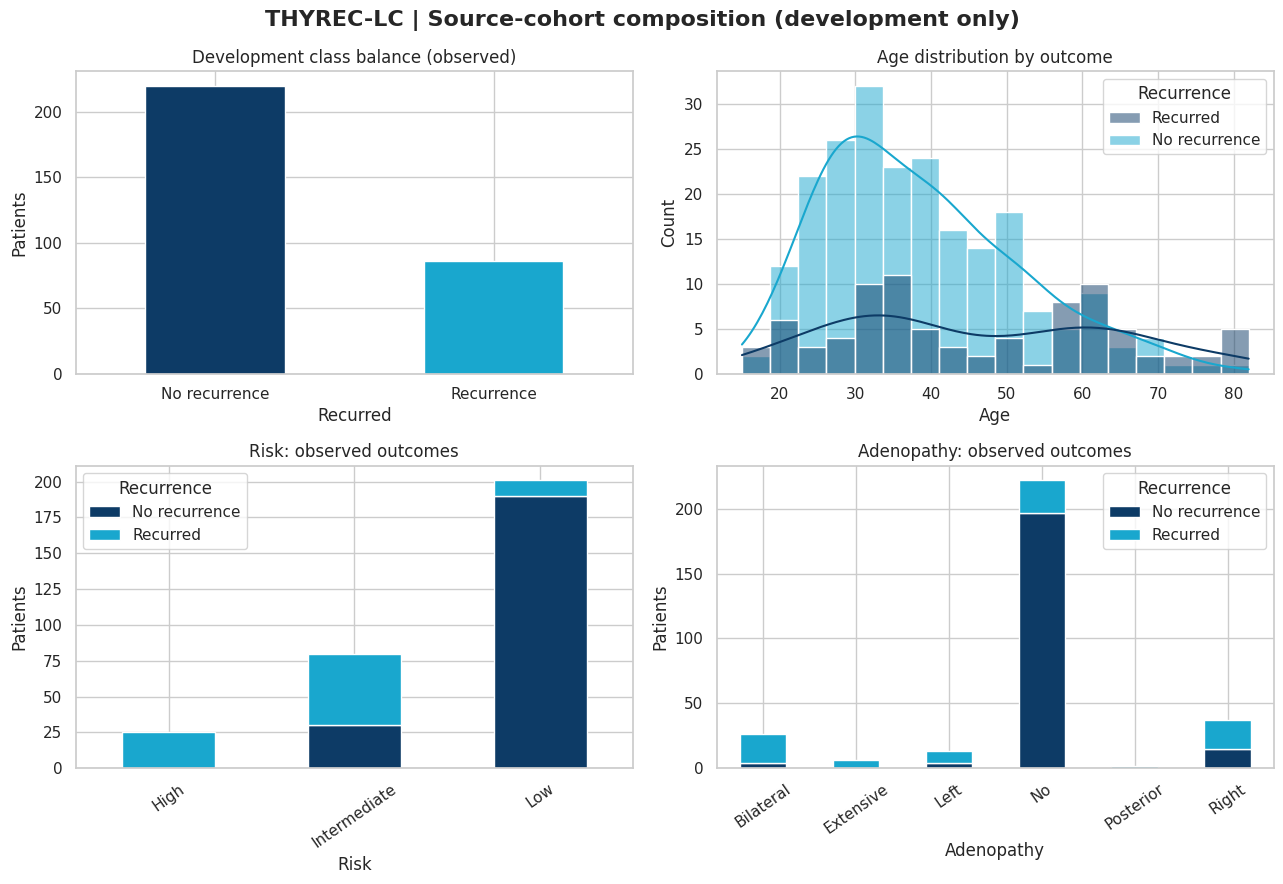

In [35]:
cohort=Xdev.copy();cohort['Recurrence']=np.where(ydev.to_numpy()==1,'Recurred','No recurrence')
profile=[]
for col in Xdev.columns:
    is_numeric=col=='Age'
    profile.append({'feature':col,'type':'numeric' if is_numeric else 'categorical',
      'missing_n':int(Xdev[col].isna().sum()),'unique_values':int(Xdev[col].nunique(dropna=True)),
      'most_common':str(Xdev[col].mode().iloc[0]) if Xdev[col].notna().any() else 'NA'})
pd.DataFrame(profile).to_csv(EDA_DIR/'Table_Development_Data_Dictionary.csv',index=False)
fig,axs=plt.subplots(2,2,figsize=(13,9))
ydev.value_counts().sort_index().rename(index={0:'No recurrence',1:'Recurrence'}).plot.bar(ax=axs[0,0],color=PALETTE[:2],rot=0)
axs[0,0].set_title('Development class balance (observed)');axs[0,0].set_ylabel('Patients')
sns.histplot(data=cohort,x='Age',hue='Recurrence',kde=True,bins=18,alpha=.5,palette=PALETTE[:2],ax=axs[0,1]);axs[0,1].set_title('Age distribution by outcome')
for ax,col in [(axs[1,0],'Risk'),(axs[1,1],'Adenopathy')]:
    tmp=pd.crosstab(cohort[col],cohort['Recurrence']);tmp.plot(kind='bar',stacked=True,ax=ax,
      color=PALETTE[:2],rot=35);ax.set_title(f'{col}: observed outcomes');ax.set_ylabel('Patients')
fig.suptitle('THYREC-LC | Source-cohort composition (development only)',fontsize=16,fontweight='bold')
fig.tight_layout();save_plot(fig,'EDA_01_cohort_dashboard');plt.show()

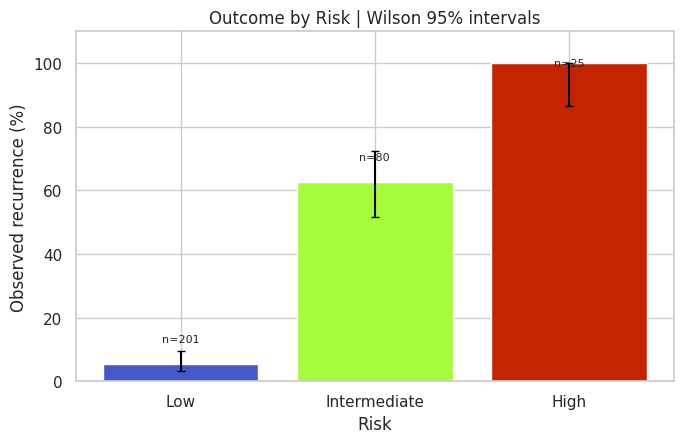

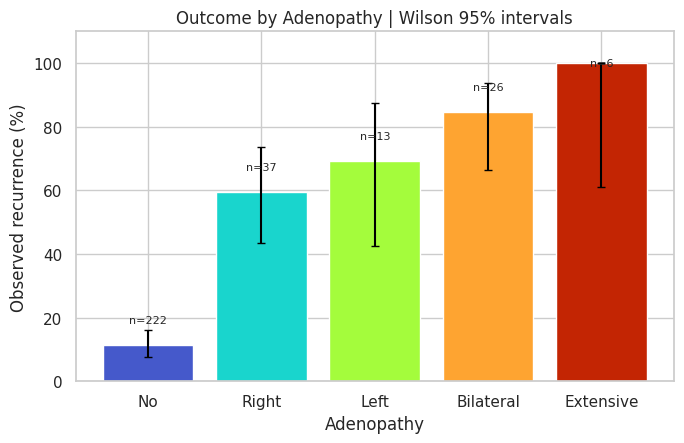

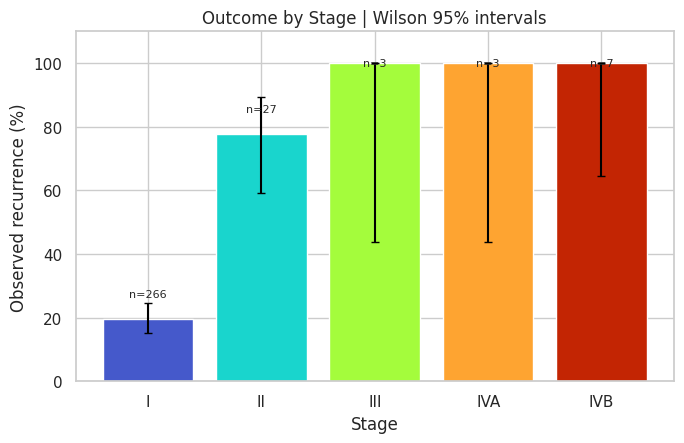

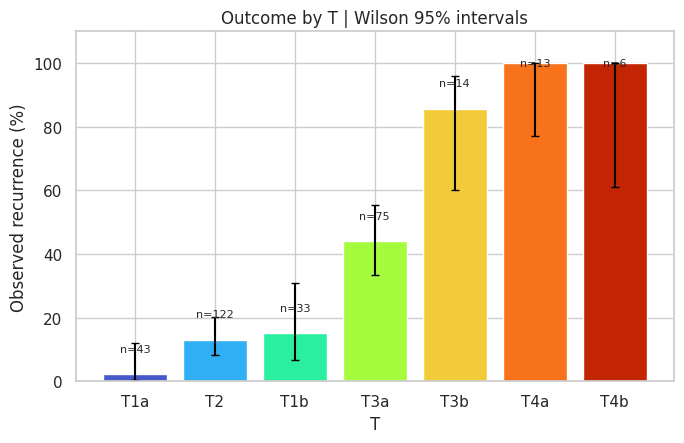

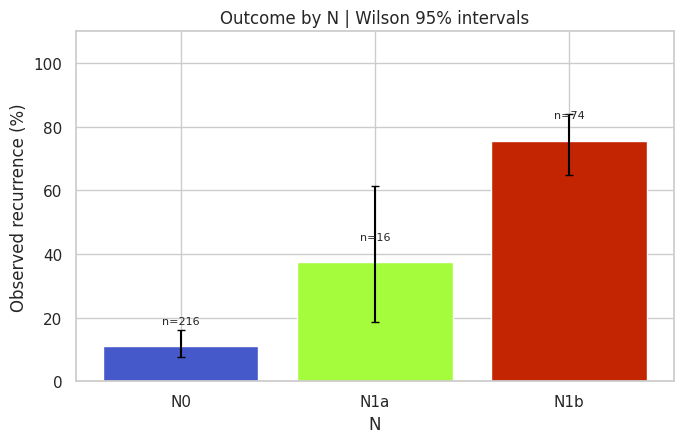

In [36]:
# Event rates by categorical level; use Wilson intervals rather than implying precision at n=1-2.
from statsmodels.stats.proportion import proportion_confint
levels=[]
for feat in [c for c in Xdev.columns if c!='Age']:
    for level,part in Xdev.groupby(feat,dropna=False,observed=True):
        yy=ydev.loc[part.index]; n=len(yy); k=int(yy.sum())
        low,high=proportion_confint(k,n,alpha=.05,method='wilson')
        levels.append({'feature':feat,'level':str(level),'n':n,'events':k,'event_rate':k/n,
                       'wilson95_low':low,'wilson95_high':high})
rates=pd.DataFrame(levels);rates.to_csv(EDA_DIR/'Table_Event_Rates_and_Wilson_Intervals.csv',index=False)
for feature in ['Risk','Adenopathy','Stage','T','N']:
    if feature not in rates.feature.values: continue
    d=rates[(rates.feature==feature)&(rates.n>=3)].sort_values('event_rate')
    fig,ax=plt.subplots(figsize=(max(7,len(d)*.9),4.6))
    ax.bar(d.level,d.event_rate*100,color=mpl.colormaps['turbo'](np.linspace(.1,.9,len(d))))
    # Matplotlib requires nonnegative asymmetric error lengths.  Wilson
    # bounds can differ from the point estimate by ~1e-16 through rounding,
    # particularly when all patients in a category have the same outcome.
    rate = d['event_rate'].to_numpy(dtype=float)
    lower = d['wilson95_low'].to_numpy(dtype=float)
    upper = d['wilson95_high'].to_numpy(dtype=float)
    if not (np.isfinite(rate).all() and np.isfinite(lower).all() and np.isfinite(upper).all()):
        raise ValueError(f'Non-finite Wilson interval detected for {feature}')
    tol = 1e-10  # comparison only; do not modify reported statistics
    if np.any(lower > rate + tol) or np.any(upper < rate - tol) or np.any(lower > upper + tol):
        raise ValueError(f'Inconsistent Wilson confidence interval for {feature}; inspect source data')
    yerr = np.vstack((np.maximum(0.0, (rate - lower) * 100),
                      np.maximum(0.0, (upper - rate) * 100)))
    ax.errorbar(np.arange(len(d)), rate * 100, yerr=yerr,
                fmt='none', ecolor='black', capsize=3)
    for i,r in enumerate(d.itertuples()):ax.text(i,min(99,r.event_rate*100+7),f'n={r.n}',ha='center',fontsize=8)
    ax.set(xlabel=feature,ylabel='Observed recurrence (%)',title=f'Outcome by {feature} | Wilson 95% intervals',ylim=(0,110))
    fig.tight_layout();save_plot(fig,'EDA_event_rate_'+feature);plt.show()

### 4A.1 3D clinical map and leakage-safe dimensionality reduction
The 3D clinical scatter uses real Age, Risk and clinical stage with deterministic jitter **only to reveal overlapping display points**. The 3D PCA embeds one-hot-encoded *development-only* inputs and colors points by their observed outcome; it does not imply phenotypic clusters or modify training features. The PCA fit excludes `Response` and `Recurred`.

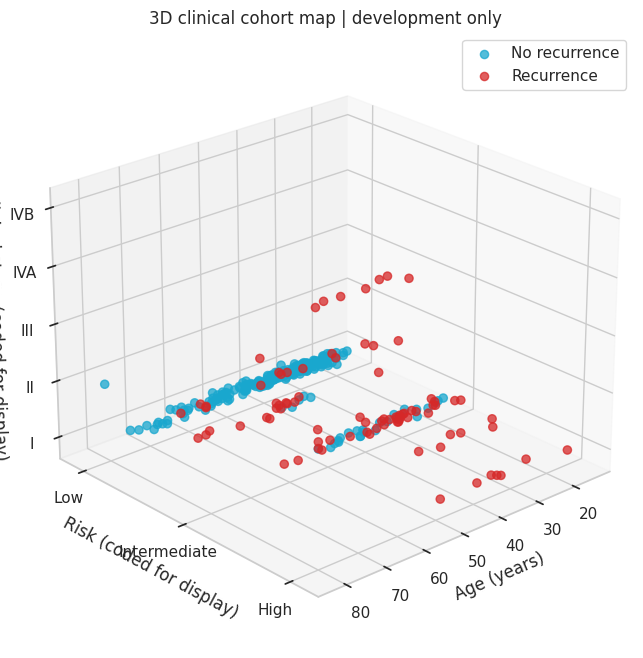

Interactive: EDA_3D_clinical_interactive.html


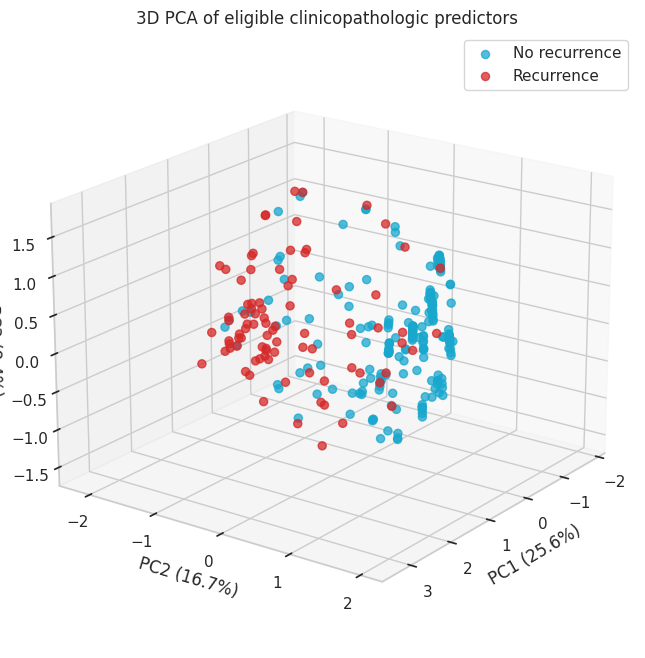

Interactive: EDA_3D_PCA_interactive.html


In [37]:
RISK_ORDER={'Low':0,'Intermediate':1,'High':2}
def numbered(series,prefer=None):
    s=series.astype(str).str.strip()
    mapping=prefer if prefer and s.isin(list(prefer)).any() else {t:i for i,t in enumerate(sorted(s.unique()))}
    return s.map(mapping).astype(float),mapping
rr,rm=numbered(Xdev['Risk'],RISK_ORDER)
ss,smapping=numbered(Xdev['Stage'])
rng=np.random.default_rng(SEED+1501)
x3=Xdev['Age'].to_numpy(dtype=float);y3=rr.to_numpy()+rng.normal(0,.035,len(rr));z3=ss.to_numpy()+rng.normal(0,.035,len(ss))
fig=plt.figure(figsize=(10,8));ax=fig.add_subplot(111,projection='3d')
for cl,c,lab in [(0,PALETTE[1],'No recurrence'),(1,PALETTE[3],'Recurrence')]:
    ix=ydev.to_numpy()==cl
    ax.scatter(x3[ix],y3[ix],z3[ix],s=35,alpha=.75,c=c,depthshade=True,label=lab)
ax.set(xlabel='Age (years)',ylabel='Risk (coded for display)',zlabel='Clinical stage (coded for display)',
       title='3D clinical cohort map | development only')
ax.set_yticks(list(rm.values()),list(rm.keys()));ax.set_zticks(list(smapping.values()),list(smapping.keys()))
ax.view_init(elev=24,azim=48);ax.legend();save_plot(fig,'EDA_3D_clinical_Risk_Stage_Age');plt.show()
if PLOTLY_OK:
    view=pd.DataFrame({'Age':x3,'Risk_display':y3,'Stage_display':z3,'Recurrence':cohort['Recurrence'].to_numpy(),
                        'Risk':Xdev.Risk.astype(str).to_numpy(),'Stage':Xdev.Stage.astype(str).to_numpy()})
    f=px.scatter_3d(view,x='Age',y='Risk_display',z='Stage_display',color='Recurrence',
       hover_data=['Risk','Stage'],color_discrete_map={'Recurred':PALETTE[3],'No recurrence':PALETTE[1]},
       title='Interactive 3D observed clinical landscape | descriptive only',opacity=.82)
    f.update_traces(marker={'size':4});plotly_save(f,'EDA_3D_clinical_interactive')
# Fit PCA on training/development only. No outcome-dependent embedding and no clinical inference.
pca_encoder=preprocessing(list(Xdev.columns),'standard').fit(Xdev)
P=pca_encoder.transform(Xdev)
embed=PCA(n_components=3,random_state=SEED).fit_transform(P)
expl=PCA(n_components=3,random_state=SEED).fit(P).explained_variance_ratio_
fig=plt.figure(figsize=(10,8));ax=fig.add_subplot(111,projection='3d')
for cl,c,l in [(0,PALETTE[1],'No recurrence'),(1,PALETTE[3],'Recurrence')]:
    ix=ydev.to_numpy()==cl
    ax.scatter(embed[ix,0],embed[ix,1],embed[ix,2],c=c,s=34,alpha=.75,label=l)
ax.set(xlabel=f'PC1 ({100*expl[0]:.1f}%)',ylabel=f'PC2 ({100*expl[1]:.1f}%)',
       zlabel=f'PC3 ({100*expl[2]:.1f}%)',title='3D PCA of eligible clinicopathologic predictors')
ax.view_init(20,36);ax.legend();save_plot(fig,'EDA_3D_PCA');plt.show()
if PLOTLY_OK:
    d=pd.DataFrame({'PC1':embed[:,0],'PC2':embed[:,1],'PC3':embed[:,2],
       'Class':cohort['Recurrence'].to_numpy(),'Risk':Xdev.Risk.astype(str).to_numpy()})
    f=px.scatter_3d(d,x='PC1',y='PC2',z='PC3',color='Class',symbol='Risk',
       color_discrete_map={'Recurred':PALETTE[3],'No recurrence':PALETTE[1]},
       title='Interactive 3D PCA | train/development only')
    plotly_save(f,'EDA_3D_PCA_interactive')

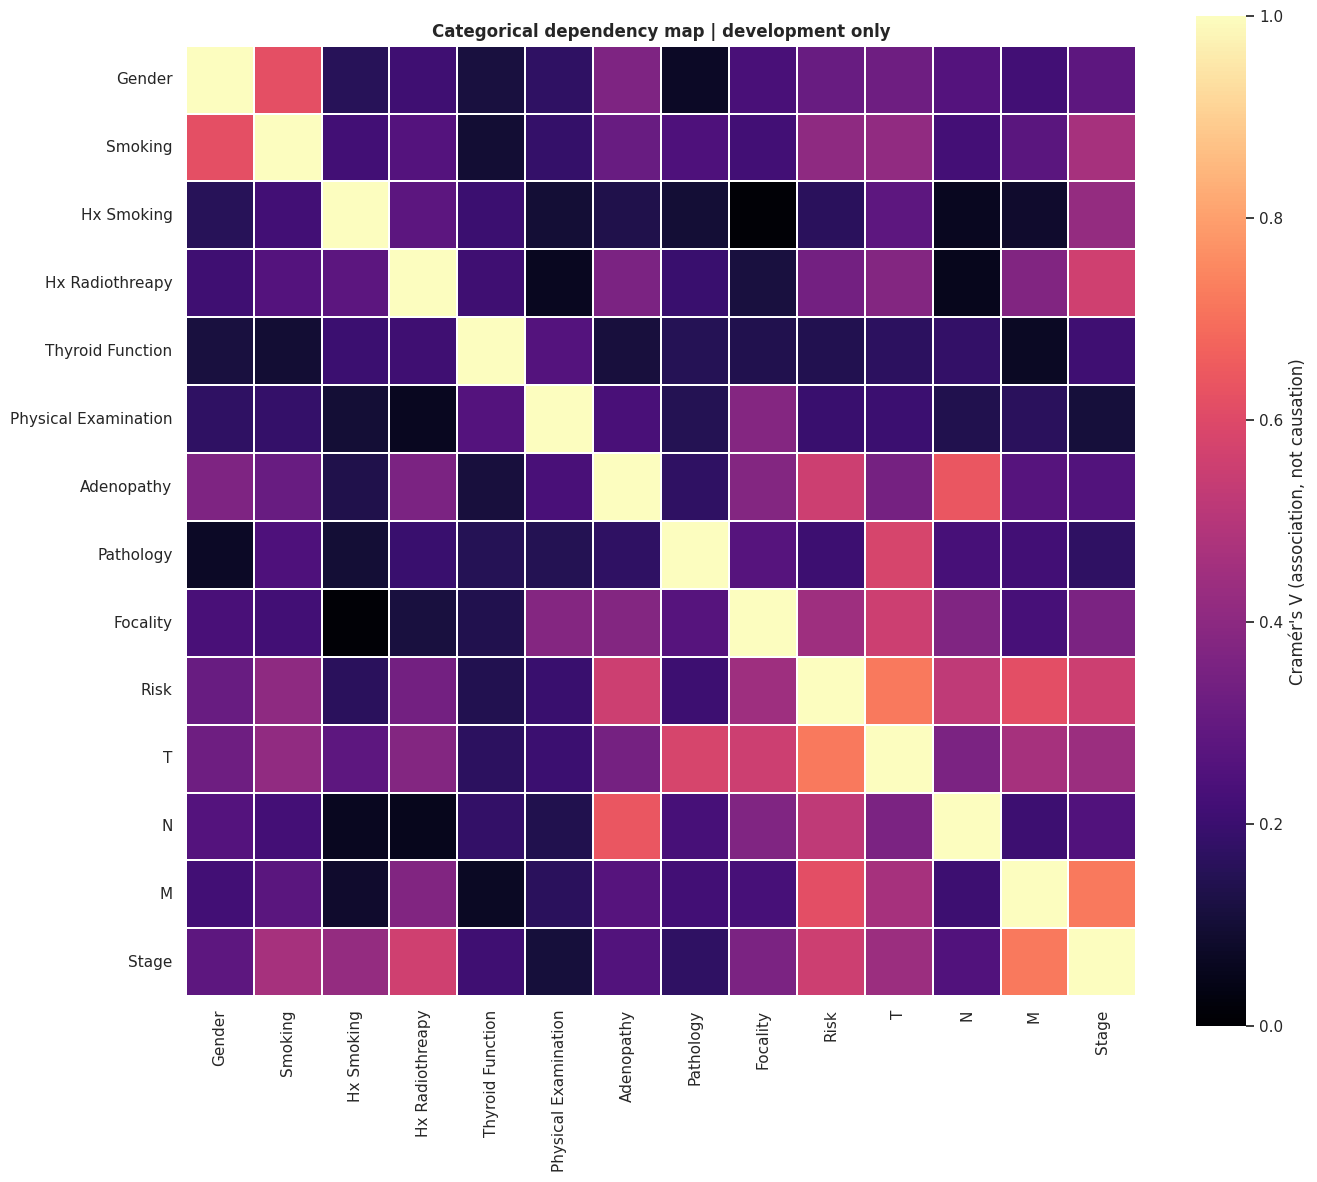

In [38]:
# Cramér's V association heatmap; associations, not causal or predictive importance.
from scipy.stats import chi2_contingency
ccols=[c for c in Xdev.columns if c!='Age']
def cramers_v(a,b):
    tab=pd.crosstab(a.astype(str),b.astype(str))
    if min(tab.shape)<2:return 0.
    chi2=chi2_contingency(tab,correction=False)[0];n=tab.to_numpy().sum()
    return float(np.sqrt(chi2/(n*max(1,min(tab.shape)-1))))
assoc=pd.DataFrame(index=ccols,columns=ccols,dtype=float)
for a in ccols:
    for b in ccols:assoc.loc[a,b]=cramers_v(Xdev[a],Xdev[b])
assoc.to_csv(EDA_DIR/'Table_Categorical_CramersV.csv')
fig,ax=plt.subplots(figsize=(14,12));sns.heatmap(assoc,cmap='magma',vmin=0,vmax=1,square=True,
  linewidths=.3,ax=ax,cbar_kws={'label':"Cramér's V (association, not causation)"})
ax.set_title('Categorical dependency map | development only',fontweight='bold');fig.tight_layout()
save_plot(fig,'EDA_CramersV_Heatmap');plt.show()

## 6. Clinical prediction metrics and calibration helpers

All positive-class measures concern **recurrence=1**. Accuracy is reported as a proportion in the exported CSV and can be formatted consistently as a percentage in the manuscript. Calibration slope/intercept are estimated by regressing outcome on logit of predicted risk; with only 22 test recurrences, uncertainty is substantial.

In [39]:
import statsmodels.api as sm
def evaluate(ytrue,probs,threshold=0.5):
    yy=np.asarray(ytrue,dtype=int);pp=np.clip(np.asarray(probs,dtype=float),1e-9,1-1e-9)
    pred=(pp>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(yy,pred,labels=[0,1]).ravel()
    result={'n':len(yy),'events':int(sum(yy)),'accuracy':accuracy_score(yy,pred),
      'weighted_f1':f1_score(yy,pred,average='weighted',zero_division=0),
      'recurrence_f1':f1_score(yy,pred,zero_division=0),
      'recurrence_recall':tp/max(tp+fn,1),'recurrence_precision':tp/max(tp+fp,1),
      'specificity':tn/max(tn+fp,1),'balanced_accuracy':balanced_accuracy_score(yy,pred),
      'mcc':matthews_corrcoef(yy,pred),'brier':brier_score_loss(yy,pp),
      'log_loss':log_loss(yy,pp,labels=[0,1]),
      'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}
    result['roc_auc']=roc_auc_score(yy,pp) if len(np.unique(yy))>1 else np.nan
    result['average_precision']=average_precision_score(yy,pp) if sum(yy)>0 else np.nan
    return result
def calibration_parameters(truth,prob):
    yy=np.asarray(truth,dtype=int);p=np.clip(np.asarray(prob,dtype=float),1e-5,1-1e-5)
    z=np.log(p/(1-p)); fit=sm.GLM(yy,sm.add_constant(z),family=sm.families.Binomial()).fit()
    # calibration-in-the-large (offset logistic intercept with slope fixed at 1)
    off=sm.GLM(yy,np.ones((len(yy),1)),offset=z,family=sm.families.Binomial()).fit()
    return {'calibration_intercept':float(fit.params[0]),'calibration_slope':float(fit.params[1]),
            'calibration_in_the_large':float(off.params[0])}
def expected_calibration_error(truth,prob,n_bins=8):
    yy=np.asarray(truth);pp=np.asarray(prob);edges=np.quantile(pp,np.linspace(0,1,n_bins+1));
    edges[0],edges[-1]=-1e-12,1+1e-12;weight=0.0
    for i in range(n_bins):
        include=(pp>edges[i])&(pp<=edges[i+1]);n=int(include.sum())
        if n: weight+=n/len(pp)*abs(float(yy[include].mean()-pp[include].mean()))
    return weight
print('Metric definitions loaded: weighted F1, recurrence F1, MCC, AUC, Brier, calibration.')

Metric definitions loaded: weighted F1, recurrence F1, MCC, AUC, Brier, calibration.


## 7. Compare full ML with ATA risk-only and Risk+Adenopathy baselines

**Primary additional comparison.** The risk-only and two-feature models are prespecified simple logistic regressions; all encoding happens *inside* each fitted pipeline. The primary XGBoost remains the original CV-selected winner, even if a reference model scores better on the 77-record test. The run saves model weights and per-person predicted probabilities without identifiers.

In [40]:
PRIMARY=BASELINES+LOCKED
holdout_rows=[];holdout_proba={};fitted={}
for name in PRIMARY:
    estimator=build_model(name)
    assert 'Response' not in Xdev.columns
    estimator.fit(Xdev,ydev)
    probabilities=estimator.predict_proba(Xtest)[:,1]
    holdout_proba[name]=probabilities;fitted[name]=estimator
    holdout_rows.append({'model':name,'sample':'historical_seed42_holdout',**evaluate(ytest,probabilities)})
    dump(estimator,OUTPUT/(name+'.joblib'))
holdout=pd.DataFrame(holdout_rows)
holdout.to_csv(OUTPUT/'table_R2_clinical_baselines_heldout.csv',index=False)
pred_table=pd.DataFrame({'test_original_row_index':test_idx,'y_true':ytest.to_numpy()})
for name,probs in holdout_proba.items(): pred_table[name+'_risk']=probs
pred_table.to_csv(OUTPUT/'heldout_prediction_probabilities.csv',index=False)
print(holdout[['model','accuracy','recurrence_recall','recurrence_f1','balanced_accuracy','mcc','roc_auc','brier']].round(3).to_string(index=False))

             model  accuracy  recurrence_recall  recurrence_f1  balanced_accuracy   mcc  roc_auc  brier
     ATA_Risk_only     0.883              0.955          0.824              0.905 0.754    0.928  0.085
Risk_Adenopathy_LR     0.922              0.818          0.857              0.891 0.805    0.950  0.071
           XGB_raw     0.909              0.909          0.851              0.909 0.789    0.949  0.083


## 8. Paired bootstrap confidence intervals for clinical incremental value

Evaluate **differences on the same test patients**; do not infer significance from comparing two independent error bars. 2,000 stratified-within-class bootstrap resamples give descriptive intervals for incremental AUC, recurrence F1, balanced accuracy, and Brier score. Because the test set has already featured in the manuscript, these are **descriptive extensions**, not confirmation on a new external cohort.

In [41]:
def paired_bootstrap(ytrue,prob_a,prob_b,nboot=BOOT_N,seed=SEED):
    yy=np.asarray(ytrue,dtype=int);a=np.asarray(prob_a);b=np.asarray(prob_b)
    rng=np.random.default_rng(seed); negatives=np.where(yy==0)[0];positives=np.where(yy==1)[0]
    metrics=['roc_auc','recurrence_f1','balanced_accuracy','mcc','brier']
    point_a=evaluate(yy,a);point_b=evaluate(yy,b)
    deltas={m:[] for m in metrics}
    for _ in range(nboot):
        idx=np.concatenate([rng.choice(negatives,len(negatives),replace=True),
                            rng.choice(positives,len(positives),replace=True)])
        aa=evaluate(yy[idx],a[idx]);bb=evaluate(yy[idx],b[idx])
        for met in metrics: deltas[met].append(aa[met]-bb[met])
    rows=[]
    for met in metrics:
        low,high=np.quantile(deltas[met],[0.025,0.975])
        rows.append({'metric':met,'delta_ml_minus_baseline':point_a[met]-point_b[met],
                     'ci95_low':low,'ci95_high':high,'n_boot':nboot,
                     'interpretation':'negative is better for Brier' if met=='brier' else 'positive is better'})
    return pd.DataFrame(rows)
paired=[]
for comparator in BASELINES:
    q=paired_bootstrap(ytest,holdout_proba['XGB_raw'],holdout_proba[comparator])
    q.insert(0,'baseline',comparator);paired.append(q)
paired=pd.concat(paired,ignore_index=True)
paired.to_csv(OUTPUT/'table_R2_paired_bootstrap_95ci.csv',index=False)
print(paired.round(3).to_string(index=False))

          baseline            metric  delta_ml_minus_baseline  ci95_low  ci95_high  n_boot               interpretation
     ATA_Risk_only           roc_auc                    0.021    -0.019      0.062    2000           positive is better
     ATA_Risk_only     recurrence_f1                    0.028    -0.047      0.099    2000           positive is better
     ATA_Risk_only balanced_accuracy                    0.005    -0.050      0.055    2000           positive is better
     ATA_Risk_only               mcc                    0.035    -0.071      0.136    2000           positive is better
     ATA_Risk_only             brier                   -0.002    -0.033      0.033    2000 negative is better for Brier
Risk_Adenopathy_LR           roc_auc                   -0.001    -0.036      0.034    2000           positive is better
Risk_Adenopathy_LR     recurrence_f1                   -0.006    -0.105      0.114    2000           positive is better
Risk_Adenopathy_LR balanced_accuracy    

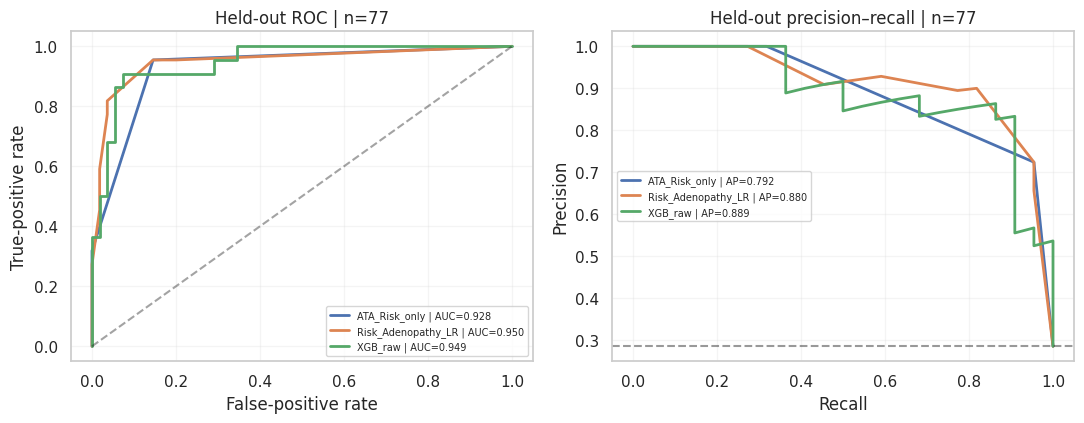

In [42]:
fig,axes=plt.subplots(1,2,figsize=(11,4.4))
for name in PRIMARY:
    prob=holdout_proba[name]
    fpr,tpr,_=roc_curve(ytest,prob)
    p,r,_=precision_recall_curve(ytest,prob)
    axes[0].plot(fpr,tpr,lw=2,label=f'{name} | AUC={roc_auc_score(ytest,prob):.3f}')
    axes[1].plot(r,p,lw=2,label=f'{name} | AP={average_precision_score(ytest,prob):.3f}')
axes[0].plot([0,1],[0,1],'k--',alpha=.4);axes[0].set(xlabel='False-positive rate',ylabel='True-positive rate',title='Held-out ROC | n=77')
axes[1].axhline(ytest.mean(),linestyle='--',color='black',alpha=.4);axes[1].set(xlabel='Recall',ylabel='Precision',title='Held-out precision–recall | n=77')
for ax in axes: ax.legend(fontsize=7);ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(OUTPUT/'figure_R2_baseline_ROC_PR.png',dpi=320,bbox_inches='tight')
plt.show()

## 9. Repeated CV stability on development partition only (5 folds × 5 repeats)

This is **not** another sweep over all 200 original pipelines: it tests the substantive reviewer concern—whether leading algorithms and scaling variants retain their ranking under resampling. Record every fold, metrics, failures, and training sample counts. Repeated fold measurements are correlated; their naive standard deviation is **descriptive**, not a confidence interval for independent replications.

In [43]:
repeat_cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=R2_REPEATS,random_state=SEED+31)
repeated_rows=[];cv_errors=[]
for j,(tr,va) in enumerate(repeat_cv.split(Xdev,ydev)):
    rep=j//5+1;fold=j%5+1
    for name in EVAL_SET:
        try:
            model=build_model(name);model.fit(Xdev.iloc[tr],ydev.iloc[tr])
            probs=model.predict_proba(Xdev.iloc[va])[:,1]
            repeated_rows.append({'repeat':rep,'fold':fold,'model':name,'train_n':len(tr),
                                  'validation_n':len(va),**evaluate(ydev.iloc[va],probs)})
        except Exception as exc:
            cv_errors.append({'repeat':rep,'fold':fold,'model':name,
                              'error_type':type(exc).__name__,'error':str(exc)[:260]})
repeated=pd.DataFrame(repeated_rows)
repeated.to_csv(OUTPUT/'repeated_5fold_full_fold_results.csv',index=False)
pd.DataFrame(cv_errors,columns=['repeat','fold','model','error_type','error']).to_csv(OUTPUT/'cv_errors.csv',index=False)
if cv_errors: print('MODEL FAILURES: see cv_errors.csv',len(cv_errors))
print('Successfully evaluated fold-model combinations:',len(repeated),'of',5*R2_REPEATS*len(EVAL_SET))
assert not repeated.empty

Successfully evaluated fold-model combinations: 225 of 225


In [44]:
MEASURES=['weighted_f1','recurrence_f1','recurrence_recall','balanced_accuracy','mcc','roc_auc','brier']
cv_summary=(repeated.groupby('model')[MEASURES].agg(['mean','std'])
            .sort_values(('weighted_f1','mean'),ascending=False))
cv_summary.to_csv(OUTPUT/'table_R2_repeated_CV_summary.csv')
ranking=[]
for measure in ['weighted_f1','recurrence_f1','balanced_accuracy','mcc','roc_auc']:
    agg=repeated.groupby('model')[measure].mean().sort_values(ascending=False)
    for place,(name,score) in enumerate(agg.items(),1):
        ranking.append({'selection_criterion':measure,'rank':place,'model':name,'cv_mean':score})
ranking=pd.DataFrame(ranking)
ranking.to_csv(OUTPUT/'table_R2_alternative_selection_rankings.csv',index=False)
print(cv_summary.round(3).to_string())
print('\nAlternate-criterion winner:')
print(ranking[ranking['rank']==1].to_string(index=False))

                      weighted_f1        recurrence_f1        recurrence_recall        balanced_accuracy           mcc        roc_auc         brier       
                             mean    std          mean    std              mean    std              mean    std   mean    std    mean    std   mean    std
model                                                                                                                                                     
AdaBoost_raw                0.887  0.040         0.800  0.069             0.801  0.098             0.861  0.050  0.728  0.096   0.934  0.032  0.158  0.008
Risk_Adenopathy_LR          0.879  0.043         0.778  0.086             0.755  0.123             0.843  0.062  0.704  0.107   0.901  0.035  0.097  0.020
ATA_Risk_only               0.870  0.038         0.787  0.055             0.873  0.072             0.868  0.040  0.702  0.080   0.888  0.040  0.103  0.020
QDA_Standard                0.869  0.042         0.752  0.083         

XGB raw is among fold winners: 2 / 25


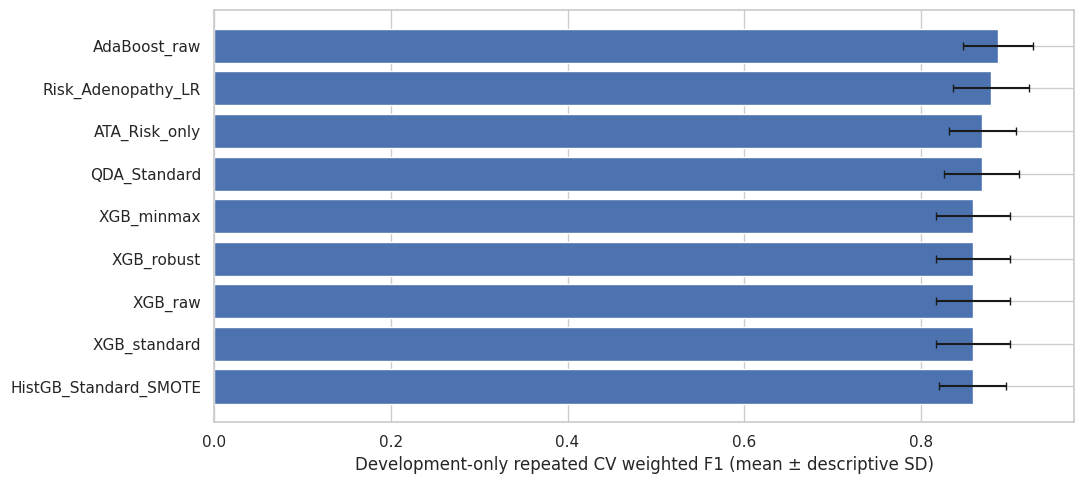

In [45]:
# Stability of per-fold winner and exact numerical ties (within a prespecified tolerance).
fold_wins=[];tie_tolerance=1e-8
for (rep,fold),part in repeated.groupby(['repeat','fold']):
    best=float(part.weighted_f1.max());winners=part.loc[abs(part.weighted_f1-best)<tie_tolerance,'model'].tolist()
    fold_wins.append({'repeat':rep,'fold':fold,'best_weighted_f1':best,
                      'winners':' | '.join(sorted(winners)),'ties':len(winners),
                      'xgb_raw_wins':int('XGB_raw' in winners)})
fold_wins=pd.DataFrame(fold_wins);fold_wins.to_csv(OUTPUT/'foldwise_winner_ties.csv',index=False)
print('XGB raw is among fold winners:',int(fold_wins.xgb_raw_wins.sum()),'/',len(fold_wins))
plt.figure(figsize=(11,5));plot_data=cv_summary.reset_index()
names=plot_data.model.tolist();means=plot_data[('weighted_f1','mean')].to_numpy()
sd=plot_data[('weighted_f1','std')].to_numpy()
plt.barh(names[::-1],means[::-1],xerr=sd[::-1],capsize=3)
plt.xlabel('Development-only repeated CV weighted F1 (mean ± descriptive SD)')
plt.tight_layout();plt.savefig(OUTPUT/'figure_R2_repeated_ranking.png',dpi=320,bbox_inches='tight');plt.show()

## 10. Nested model-selection validation (additional reviewer-strengthened test)

**Outer:** 5-fold stratified CV repeated 3 times, solely in the 306-record development partition. **Inner:** three folds for selecting among four locked candidate algorithms by *weighted F1*. Each outer validation fold is untouched by inner fitting/selection. This gives an **honest development-side evaluation of the selection procedure**, distinct from the historical held-out split. No use is made of `Response`.

In [46]:
from sklearn.model_selection import cross_val_score
NESTED_SET=['XGB_raw','HistGB_Standard_SMOTE','QDA_Standard','AdaBoost_raw']
nested_cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=NESTED_REPEATS,random_state=SEED+71)
nested_rows=[];inner_rows=[]
for iteration,(tr,va) in enumerate(nested_cv.split(Xdev,ydev),1):
    inner=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED+100+iteration)
    winners=[]
    for name in NESTED_SET:
        try:
            fold_scores=cross_val_score(build_model(name),Xdev.iloc[tr],ydev.iloc[tr],
                                        cv=inner,scoring='f1_weighted',n_jobs=1,error_score='raise')
            score=float(fold_scores.mean());winners.append((name,score))
            inner_rows.append({'outer_iteration':iteration,'model':name,'inner_mean_weighted_f1':score,
                               'inner_sd':float(fold_scores.std(ddof=1))})
        except Exception as exc:
            inner_rows.append({'outer_iteration':iteration,'model':name,'error':str(exc)[:260]})
    if not winners: raise RuntimeError('All inner models failed; inspect nested CV diagnostics.')
    selected=sorted(winners,key=lambda pair:(-pair[1],NESTED_SET.index(pair[0])))[0][0]
    model=build_model(selected);model.fit(Xdev.iloc[tr],ydev.iloc[tr]);p=model.predict_proba(Xdev.iloc[va])[:,1]
    nested_rows.append({'outer_iteration':iteration,'repeat':(iteration-1)//5+1,
                        'fold':(iteration-1)%5+1,'selected_model':selected,
                        'outer_n':len(va),**evaluate(ydev.iloc[va],p)})
nested_results=pd.DataFrame(nested_rows)
nested_results.to_csv(OUTPUT/'nested_outer_CV_results.csv',index=False)
pd.DataFrame(inner_rows).to_csv(OUTPUT/'nested_inner_CV_scores.csv',index=False)
print('Nested selection frequency:',nested_results.selected_model.value_counts().to_dict())
print('Outer evaluation mean (folds correlated):')
print(nested_results[MEASURES].mean().round(3).to_string())

Nested selection frequency: {'QDA_Standard': 5, 'XGB_raw': 4, 'AdaBoost_raw': 4, 'HistGB_Standard_SMOTE': 2}
Outer evaluation mean (folds correlated):
weighted_f1          0.855
recurrence_f1        0.729
recurrence_recall    0.687
balanced_accuracy    0.806
mcc                  0.643
roc_auc              0.914
brier                0.129


## 11. Group-disjoint sensitivity CV (protect identical predictor signatures)

**Clinical caveat:** groups are **exact predictor-vector signatures**, not verified patient IDs. This analysis asks how scores respond when feature-identical records cannot occur on both sides of an evaluation fold. It neither removes records nor proves a duplicated patient. Per-fold class prevalence and sizes may differ from ordinary stratified CV.

In [47]:
dev_groups=features_signature.iloc[train_idx].to_numpy()
sgkf=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED+19)
group_rows=[]
for fold,(tr,va) in enumerate(sgkf.split(Xdev,ydev,groups=dev_groups),1):
    assert set(dev_groups[tr]).isdisjoint(dev_groups[va]),'Group leakage found'
    for name in PRIMARY:
        m=build_model(name);m.fit(Xdev.iloc[tr],ydev.iloc[tr]);p=m.predict_proba(Xdev.iloc[va])[:,1]
        group_rows.append({'fold':fold,'model':name,'n_train':len(tr),'n_eval':len(va),
                           'eval_events':int(ydev.iloc[va].sum()),**evaluate(ydev.iloc[va],p)})
group_results=pd.DataFrame(group_rows)
group_results.to_csv(OUTPUT/'table_R2_group_disjoint_sensitivity.csv',index=False)
print(group_results.groupby('model')[['weighted_f1','recurrence_f1','roc_auc','brier']].agg(['mean','std']).round(3).to_string())
print('NB: evaluation groups are matching predictor vectors, not verified patient identifiers.')

                   weighted_f1        recurrence_f1        roc_auc         brier       
                          mean    std          mean    std    mean    std   mean    std
model                                                                                  
ATA_Risk_only            0.870  0.033         0.786  0.043   0.891  0.032  0.103  0.020
Risk_Adenopathy_LR       0.858  0.087         0.753  0.137   0.899  0.071  0.102  0.041
XGB_raw                  0.856  0.040         0.733  0.070   0.882  0.072  0.115  0.042
NB: evaluation groups are matching predictor vectors, not verified patient identifiers.


## 12. Development-only out-of-fold (OOF) probability predictions

These are generated by five independent training-fold pipelines for **every development record**, avoiding the optimistic bias of assessing calibration on training predictions. The simple clinical baselines and raw XGBoost use identical folds; this also enables a fair training-side decision-curve comparison.

In [48]:
oof_cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED+13)
oof_preds={name:np.full(len(ydev),np.nan) for name in PRIMARY}
oof_fold_info=[]
for fold,(tr,va) in enumerate(oof_cv.split(Xdev,ydev),1):
    for name in PRIMARY:
        model=build_model(name);model.fit(Xdev.iloc[tr],ydev.iloc[tr])
        oof_preds[name][va]=model.predict_proba(Xdev.iloc[va])[:,1]
    oof_fold_info.extend([{'fold':fold,'development_position':int(k)} for k in va])
assert all(np.isfinite(p).all() for p in oof_preds.values())
oof_table=pd.DataFrame({'source_row_index':train_idx,'outcome':ydev.to_numpy()})
for name,prob in oof_preds.items():oof_table[name+'_oof_probability']=prob
oof_table.to_csv(OUTPUT/'development_out_of_fold_predictions.csv',index=False)
print('OOF n:',len(ydev),'positive:',int(ydev.sum()),'| all probabilities fold-pure:',True)

OOF n: 306 positive: 86 | all probabilities fold-pure: True


## 13. Calibration: reliability curves, Brier, ECE, slope and intercept

We report **probability calibration**, not just discrimination. Expected calibration error (ECE) depends on binning and is included as secondary descriptive evidence. The logistic calibration slope and intercept are estimated on development OOF probabilities; ideal values are approximately 1 and 0, respectively. No estimate proves safe clinical deployment.

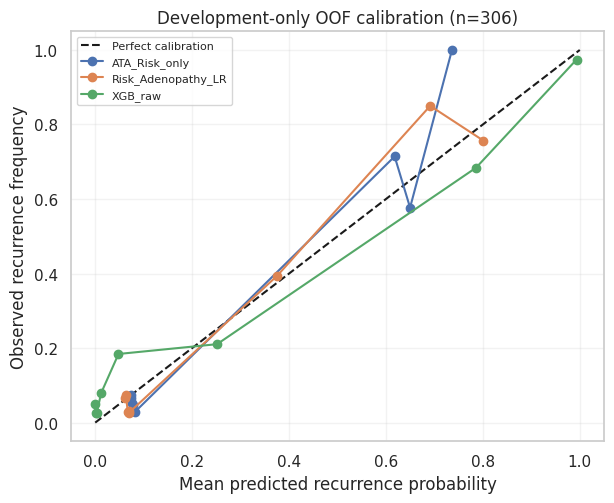

             model                sample  brier  log_loss  ece_8quantile  calibration_intercept  calibration_slope  calibration_in_the_large
     ATA_Risk_only development_5fold_OOF  0.102     0.342          0.057                  0.128              1.214                     0.030
Risk_Adenopathy_LR development_5fold_OOF  0.098     0.329          0.044                  0.153              1.169                     0.053
           XGB_raw development_5fold_OOF  0.096     0.372          0.058                 -0.096              0.537                     0.349


In [49]:
calibration_rows=[]
for name,prob in oof_preds.items():
    try: cal=calibration_parameters(ydev,prob)
    except Exception as exc:
        print('Calibration-fit failed for',name,exc)
        cal={'calibration_intercept':np.nan,'calibration_slope':np.nan,'calibration_in_the_large':np.nan}
    calibration_rows.append({'model':name,'sample':'development_5fold_OOF',
        'brier':brier_score_loss(ydev,prob),'log_loss':log_loss(ydev,prob),
        'ece_8quantile':expected_calibration_error(ydev,prob),**cal})
calibration_df=pd.DataFrame(calibration_rows)
calibration_df.to_csv(OUTPUT/'table_R2_calibration_slope_intercept_brier.csv',index=False)
fig,ax=plt.subplots(figsize=(6.3,5.2))
ax.plot([0,1],[0,1],'k--',label='Perfect calibration')
for name,p in oof_preds.items():
    observed,predicted=calibration_curve(ydev,p,n_bins=8,strategy='quantile')
    ax.plot(predicted,observed,marker='o',label=name)
ax.set(xlabel='Mean predicted recurrence probability',ylabel='Observed recurrence frequency',
       title=f'Development-only OOF calibration (n={len(ydev)})')
ax.legend(fontsize=8);ax.grid(alpha=.25);fig.tight_layout()
fig.savefig(OUTPUT/'figure_R2_OOF_calibration.png',dpi=320,bbox_inches='tight');plt.show()
print(calibration_df.round(3).to_string(index=False))

## 14. Training-only sigmoid recalibration (cross-fitted)

A 3-fold internal sigmoid calibrator is fitted **within each of five development OOF folds**; the corresponding calibrated probabilities are genuinely held out from both base-model and calibration fitting. A final calibrated model is then fitted on all development records for *descriptive* comparison with the same historical test set. Because calibration introduces complexity, compare Brier/log-loss and retain raw XGBoost as the prespecified primary unless a separate protocol authorizes a change.

In [50]:
def sigmoid_wrapper():
    try: return CalibratedClassifierCV(estimator=build_model('XGB_raw'),method='sigmoid',cv=3)
    except TypeError: return CalibratedClassifierCV(base_estimator=build_model('XGB_raw'),method='sigmoid',cv=3)
calibrated_oof=np.full(len(ydev),np.nan)
for tr,va in oof_cv.split(Xdev,ydev):
    wrapper=sigmoid_wrapper();wrapper.fit(Xdev.iloc[tr],ydev.iloc[tr])
    calibrated_oof[va]=wrapper.predict_proba(Xdev.iloc[va])[:,1]
assert np.isfinite(calibrated_oof).all()
cal_final=sigmoid_wrapper();cal_final.fit(Xdev,ydev)
pred_cal_test=cal_final.predict_proba(Xtest)[:,1]
dump(cal_final,OUTPUT/'XGB_sigmoid_calibrated.joblib')
cal_rows=[]
for sample,ground,rawp,calp in [('dev_oof',ydev,oof_preds['XGB_raw'],calibrated_oof),
                                 ('historical_test',ytest,holdout_proba['XGB_raw'],pred_cal_test)]:
    for treatment,p in [('uncalibrated',rawp),('sigmoid_calibrated',calp)]:
        cal_rows.append({'partition':sample,'risk_calibration':treatment,
                         **{k:evaluate(ground,p)[k] for k in ['brier','log_loss','roc_auc','weighted_f1','recurrence_f1']}})
cal_summary=pd.DataFrame(cal_rows)
cal_summary.to_csv(OUTPUT/'table_R2_sigmoid_calibration_comparison.csv',index=False)
pd.DataFrame({'y_true':ydev.to_numpy(),'XGB_raw_OOF':oof_preds['XGB_raw'],
              'XGB_calibrated_OOF':calibrated_oof}).to_csv(OUTPUT/'OOF_uncalibrated_vs_sigmoid.csv',index=False)
print(cal_summary.round(3).to_string(index=False))

      partition   risk_calibration  brier  log_loss  roc_auc  weighted_f1  recurrence_f1
        dev_oof       uncalibrated  0.096     0.372    0.909        0.884          0.785
        dev_oof sigmoid_calibrated  0.087     0.309    0.920        0.896          0.805
historical_test       uncalibrated  0.083     0.304    0.949        0.911          0.851
historical_test sigmoid_calibrated  0.081     0.286    0.955        0.896          0.818


## 15. Clinical decision curves (development OOF only)

Net benefit at a proposed risk threshold \(p_t\): \(NB=TP/n-(FP/n)\cdot p_t/(1-p_t)\). Compare ATA-only, two-feature logistic, XGBoost raw, calibrated XGBoost, treat-all, and treat-none, for exploratory thresholds **0.05–0.50**. This is not a claim that a threshold is clinically endorsed; the journal should identify the intended clinical decision and harms before suggesting deployment.

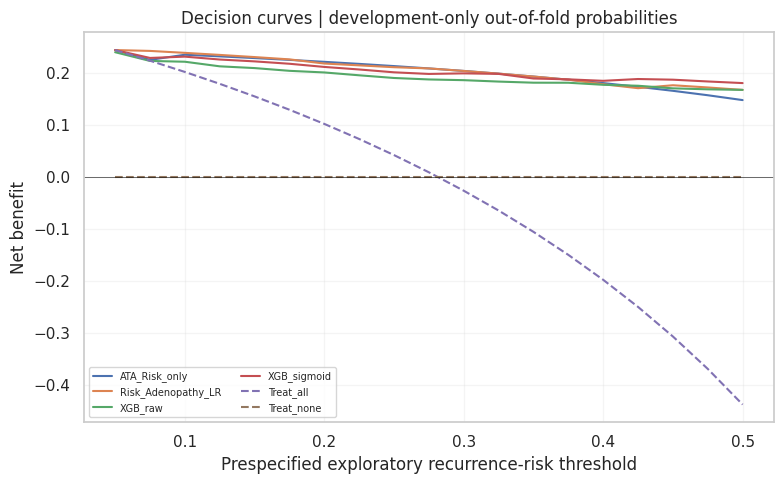

In [51]:
def decision_curve(truth,probabilities,thresholds):
    yy=np.asarray(truth,dtype=int);out=[]
    for threshold in thresholds:
        for label,prob in probabilities.items():
            cls=np.asarray(prob)>=threshold
            true_pos=np.sum(cls & (yy==1));false_pos=np.sum(cls & (yy==0))
            net=true_pos/len(yy)-false_pos/len(yy)*threshold/(1-threshold)
            out.append({'strategy':label,'risk_threshold':threshold,'net_benefit':net,
                        'tp':int(true_pos),'fp':int(false_pos),'n':len(yy)})
    return pd.DataFrame(out)
thresholds=np.round(np.arange(.05,.501,.025),3)
strategies={**oof_preds,'XGB_sigmoid':calibrated_oof,
            'Treat_all':np.ones(len(ydev)),'Treat_none':np.zeros(len(ydev))}
dca=decision_curve(ydev,strategies,thresholds)
dca.to_csv(OUTPUT/'table_R2_OOF_decision_curve.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
for name,part in dca.groupby('strategy',sort=False):
    ax.plot(part.risk_threshold,part.net_benefit,label=name,linestyle='--' if name.startswith('Treat_') else '-')
ax.axhline(0,color='black',lw=.4)
ax.set(xlabel='Prespecified exploratory recurrence-risk threshold',ylabel='Net benefit',
       title='Decision curves | development-only out-of-fold probabilities')
ax.legend(fontsize=7,ncol=2);ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(OUTPUT/'figure_R2_OOF_decision_curve.png',dpi=320,bbox_inches='tight');plt.show()

## 16. Additional novelty test: does ML add value beyond ATA Risk?

Alongside clinical baselines, retrain the **same XGBoost architecture after removing `Risk`**. This helps distinguish models that mostly reconstruct ATA risk from models that leverage other clinicopathological predictors. This is an **ablation of information**, not a claim that withholding ATA risk is a desirable clinical protocol.

In [52]:
ablation_model=build_model('XGB_without_Risk');ablation_model.fit(Xdev,ydev)
ablation_p=ablation_model.predict_proba(Xtest)[:,1]
dump(ablation_model,OUTPUT/'XGB_without_Risk.joblib')
ablation_holdout=pd.DataFrame([
    {'model':'XGB_raw','sample':'historical_test',**evaluate(ytest,holdout_proba['XGB_raw'])},
    {'model':'XGB_without_Risk','sample':'historical_test',**evaluate(ytest,ablation_p)},
    {'model':'ATA_Risk_only','sample':'historical_test',**evaluate(ytest,holdout_proba['ATA_Risk_only'])}])
ablation_holdout.to_csv(OUTPUT/'table_R2_ATA_risk_ablation_heldout.csv',index=False)
abl_cv=[]
for fold,(tr,va) in enumerate(StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED+32).split(Xdev,ydev),1):
    for name in ['XGB_raw','XGB_without_Risk','ATA_Risk_only']:
        m=build_model(name);m.fit(Xdev.iloc[tr],ydev.iloc[tr]);p=m.predict_proba(Xdev.iloc[va])[:,1]
        abl_cv.append({'fold':fold,'model':name,**evaluate(ydev.iloc[va],p)})
pd.DataFrame(abl_cv).to_csv(OUTPUT/'table_R2_ATA_risk_ablation_development_CV.csv',index=False)
print(ablation_holdout[['model','weighted_f1','recurrence_f1','roc_auc','brier']].round(3).to_string(index=False))

           model  weighted_f1  recurrence_f1  roc_auc  brier
         XGB_raw        0.911          0.851    0.949  0.083
XGB_without_Risk        0.908          0.837    0.939  0.091
   ATA_Risk_only        0.887          0.824    0.928  0.085


## 17. Descriptive subgroup safety checks (not powered for fairness conclusions)

Check sex/gender, clinical Risk level, and broad age group on the **same historical test set**. Metrics for tiny groups can fluctuate dramatically and should be marked as unstable; no causal, bias-free, or subgroup-equivalence claims follow from this table. At least 5 recurrences and 5 non-recurrences are required to print subgroup AUROC.

In [53]:
subframe=Xtest[['Gender','Risk','Age']].copy()
subframe['Age_group']=np.where(subframe['Age']<50,'Age_under_50','Age_50_plus')
subrows=[]
for feature in ['Gender','Risk','Age_group']:
    for value in sorted(subframe[feature].dropna().astype(str).unique()):
        choose=(subframe[feature].astype(str).to_numpy()==value)
        truth=ytest.to_numpy()[choose];p=holdout_proba['XGB_raw'][choose]
        if len(truth)<1:continue
        row={'subgroup_feature':feature,'subgroup_value':value,'n':len(truth),
             'events':int(truth.sum()),'nonevents':int(len(truth)-truth.sum()),
             'recurrence_recall':np.nan,'brier':np.nan,'roc_auc':np.nan,'unstable':True}
        if len(truth)>=5 and truth.sum()>0:
            row['recurrence_recall']=evaluate(truth,p)['recurrence_recall']
            row['brier']=brier_score_loss(truth,p)
        if truth.sum()>=5 and (len(truth)-truth.sum())>=5:
            row['roc_auc']=roc_auc_score(truth,p);row['unstable']=False
        subrows.append(row)
subgroups=pd.DataFrame(subrows)
subgroups.to_csv(OUTPUT/'table_R2_exploratory_subgroups.csv',index=False)
print(subgroups.round(3).to_string(index=False))

subgroup_feature subgroup_value  n  events  nonevents  recurrence_recall  brier  roc_auc  unstable
          Gender              F 60      13         47              1.000  0.059    0.975     False
          Gender              M 17       9          8              0.778  0.169    0.847     False
            Risk           High  7       7          0              1.000  0.000      NaN      True
            Risk   Intermediate 22      14          8              0.929  0.219    0.723     False
            Risk            Low 48       1         47              0.000  0.033      NaN      True
       Age_group    Age_50_plus 23      11         12              0.909  0.111    0.947     False
       Age_group   Age_under_50 54      11         43              0.909  0.072    0.947     False


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning:

A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning:

A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.



## 18. Minimum sample-size evidence, audit statements and reproducible settings

Riley et al.'s clinical model sample-size literature is a reason to **discuss event counts and optimism**; it does not support a claim of adequate power from 108 events. All installed package versions and explicit model parameters are exported. The figures and tables are new supplemental evidence only. A separately labeled independent reconstruction of the original 200-model performance, TreeSHAP, and Response ablation is provided in §18R; historical exact defaults remain unverified.

In [54]:
import importlib.metadata as importmeta
package_names=['numpy','pandas','scipy','scikit-learn','imbalanced-learn','xgboost',
               'statsmodels','matplotlib','joblib','requests']
version_data={p:importmeta.version(p) for p in package_names}
version_data['python']=platform.python_version();version_data['platform']=platform.platform()
(OUTPUT/'exact_package_versions.json').write_text(json.dumps(version_data,indent=2))
params={name:build_model(name).get_params(deep=True) for name in sorted(set(EVAL_SET+['XGB_without_Risk']))}
(OUTPUT/'supplementary_exact_model_settings.json').write_text(json.dumps(params,indent=2,default=str))
settings=[]
for name in params:
    m=build_model(name)
    for key,value in m.get_params(deep=True).items():
        if ('__' not in key or key.startswith('model__') or key.startswith('smote__')):
            settings.append({'model':name,'parameter':key,'value':str(value)})
pd.DataFrame(settings).to_csv(OUTPUT/'supplementary_classifier_settings.csv',index=False)
CONFIG={'seed':SEED,'fast_mode':FAST_MODE,'repeat_folds':5,'repeats':R2_REPEATS,
        'nested_outer_repeats':NESTED_REPEATS,'nested_inner_folds':3,
        'bootstrap_resamples':BOOT_N,'test_is_historically_reported':True,
        'holdout_threshold':0.5,'selection_scorer':'f1_weighted',
        'data_fingerprint':SOURCE_SHA256,'response_excluded':True,
        'not_external_validation':True}
(OUTPUT/'study_config.json').write_text(json.dumps(CONFIG,indent=2))
print('Saved version log, full parameters and configuration to', OUTPUT)

Saved version log, full parameters and configuration to /kaggle/working/THYREC_LC_R2


## 18R. Reproduce the manuscript's original machine-learning experiment in the same notebook

**Complete 20×10 reconstruction.** The original manuscript reports 20 classifiers, 10 preprocessing/balancing settings, five-fold development CV, an XGBoost reference, SHAP, and a temporal `Response` sensitivity experiment. To make this a genuinely **end-to-end shareable notebook**, this section recreates all those experiments from the official UCI source. No test labels guide the preprocessing choices or winner. **Important:** because the authors' original package versions and complete classifier parameters were not supplied, this is a documented **independent reconstruction**, not a verified bitwise replication. Deviations from the original manuscript must be reconciled transparently before submission.

The 200-configuration study is run when `FAST_MODE=False` and skipped in the synthetic technical smoke-test mode. Training-only random oversampling, SMOTE and ADASYN are inside `imblearn` pipelines. This section extends the earlier reviewer analyses rather than replacing them.

In [55]:
from sklearn.naive_bayes import BernoulliNB,GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, VotingClassifier, ExtraTreesClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import RidgeClassifier, SGDClassifier
from sklearn.svm import LinearSVC,SVC
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
try:
    from lightgbm import LGBMClassifier
    ORIG_HAS_LIGHTGBM=True
except ImportError:
    ORIG_HAS_LIGHTGBM=False
RUN_FULL_ORIGINAL = not FAST_MODE
CONFIG_10={
 'Raw':('raw',None),'Standard':('standard',None),'MinMax':('minmax',None),'Robust':('robust',None),
 'Raw_ROS':('raw','ros'),'Standard_ROS':('standard','ros'),'MinMax_ROS':('minmax','ros'),
 'Standard_SMOTE':('standard','smote'),'MinMax_SMOTE':('minmax','smote'),
 'Robust_ADASYN':('robust','adasyn')}
CLASSIFIER_20=['AdaBoost','BernoulliNB','DecisionTree','ExtraTrees','GradientBoosting',
 'GaussianNB','HistGradientBoosting','KNN','LDA','LogisticRegression','MLP','RandomForest',
 'Ridge','SGD','SVC_Linear','SVC_RBF','XGBoost','LightGBM','Voting','QDA']
assert len(CONFIG_10)==10 and len(CLASSIFIER_20)==20
print('Manuscript reconstruction:',len(CONFIG_10),'x',len(CLASSIFIER_20),'=',len(CONFIG_10)*len(CLASSIFIER_20))

Manuscript reconstruction: 10 x 20 = 200


In [56]:
def original_estimator(name):
    if name=='AdaBoost':return AdaBoostClassifier(n_estimators=50,random_state=SEED)
    if name=='BernoulliNB':return BernoulliNB()
    if name=='DecisionTree':return DecisionTreeClassifier(random_state=SEED)
    if name=='ExtraTrees':return ExtraTreesClassifier(n_estimators=100,random_state=SEED,n_jobs=1)
    if name=='GradientBoosting':return GradientBoostingClassifier(random_state=SEED)
    if name=='GaussianNB':return GaussianNB()
    if name=='HistGradientBoosting':return HistGradientBoostingClassifier(random_state=SEED)
    if name=='KNN':return KNeighborsClassifier(n_neighbors=5)
    if name=='LDA':return LinearDiscriminantAnalysis()
    if name=='LogisticRegression':return LogisticRegression(max_iter=3000,solver='liblinear',random_state=SEED)
    if name=='MLP':return MLPClassifier(hidden_layer_sizes=(64,),max_iter=300,early_stopping=True,random_state=SEED)
    if name=='RandomForest':return RandomForestClassifier(n_estimators=100,random_state=SEED,n_jobs=1)
    if name=='Ridge':return RidgeClassifier()
    if name=='SGD':return SGDClassifier(loss='log_loss',random_state=SEED,max_iter=1000)
    if name=='SVC_Linear':return LinearSVC(random_state=SEED,max_iter=5000)
    if name=='SVC_RBF':return SVC(kernel='rbf',probability=False,random_state=SEED)
    if name=='XGBoost':return xgb()
    if name=='LightGBM':
        if not ORIG_HAS_LIGHTGBM:raise ImportError('LightGBM required for full 200 reconstruction')
        return LGBMClassifier(n_estimators=100,random_state=SEED,verbosity=-1,n_jobs=1)
    if name=='Voting':return VotingClassifier([('lr',LogisticRegression(max_iter=2000,solver='liblinear')),
            ('rf',RandomForestClassifier(n_estimators=100,random_state=SEED,n_jobs=1)),
            ('xb',xgb())],voting='soft',n_jobs=1)
    if name=='QDA':return QuadraticDiscriminantAnalysis(reg_param=.05)
    raise KeyError(name)
def original_pipeline(classifier_name,config_name):
    scale,balance=CONFIG_10[config_name]
    steps=[('preprocess',preprocessing(ALL_PREDICTORS,scale))]
    if balance=='ros':steps.append(('sampler',RandomOverSampler(random_state=SEED)))
    if balance=='smote':steps.append(('sampler',SMOTE(k_neighbors=5,random_state=SEED)))
    if balance=='adasyn':steps.append(('sampler',ADASYN(n_neighbors=5,random_state=SEED)))
    steps.append(('model',original_estimator(classifier_name)))
    return ImbPipeline(steps) if balance else Pipeline(steps)
print('Pipeline factory loaded; no non-training-fold scaler/sampler fitting.')

Pipeline factory loaded; no non-training-fold scaler/sampler fitting.


### 18R.1 Re-run and preserve all five-fold scores for all 200 reconstructed pipelines

All model families and settings are logged, including failed folds. Scores can differ from the submitted manuscript because exact historical versions, earlier default parameters and the original tuning code are unavailable. **Do not change any code to force agreement with published held-out scores.**

In [57]:
full200=[];full200_failures=[]
if RUN_FULL_ORIGINAL:
    orig_cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
    from sklearn.metrics import precision_score,recall_score
    for ci,model_name in enumerate(CLASSIFIER_20,1):
        for cfg in CONFIG_10:
            for fold,(tr,va) in enumerate(orig_cv.split(Xdev,ydev),1):
                try:
                    m=original_pipeline(model_name,cfg)
                    m.fit(Xdev.iloc[tr],ydev.iloc[tr]);pred=m.predict(Xdev.iloc[va])
                    trues=ydev.iloc[va].to_numpy()
                    full200.append({'classifier':model_name,'configuration':cfg,'fold':fold,
                        'weighted_f1':f1_score(trues,pred,average='weighted',zero_division=0),
                        'recurrence_f1':f1_score(trues,pred,zero_division=0),
                        'recurrence_recall':recall_score(trues,pred,zero_division=0),
                        'balanced_accuracy':balanced_accuracy_score(trues,pred),
                        'mcc':matthews_corrcoef(trues,pred),'n_train':len(tr),'n_val':len(va)})
                except Exception as exc:
                    full200_failures.append({'classifier':model_name,'configuration':cfg,'fold':fold,
                         'exception_type':type(exc).__name__,'message':str(exc)[:500]})
        if ci%4==0:print('Finished',ci,'of',len(CLASSIFIER_20),'classifier families')
else:
    print('FAST_MODE=True: full 1,000-fit reconstruction skipped for software testing only')
pd.DataFrame(full200,columns=['classifier','configuration','fold','weighted_f1','recurrence_f1',
     'recurrence_recall','balanced_accuracy','mcc','n_train','n_val']).to_csv(OUTPUT/'ORIG_200_five_fold_reconstruction.csv',index=False)
pd.DataFrame(full200_failures,columns=['classifier','configuration','fold','exception_type','message']).to_csv(
    OUTPUT/'ORIG_200_reconstruction_errors.csv',index=False)
print('Reconstructed folds:',len(full200),'expected:',1000,'| recorded failures:',len(full200_failures))

Finished 4 of 20 classifier families
Finished 8 of 20 classifier families
Finished 12 of 20 classifier families
Finished 16 of 20 classifier families


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, 

Finished 20 of 20 classifier families
Reconstructed folds: 1000 expected: 1000 | recorded failures: 0


### 18R.2 Complete 20 × 10 heatmap, top-20 table, and reproducibility manifest

This heatmap is **newly computed**, not a copied manuscript figure. A high score in the reconstruction does **not** supersede the originally prespecified published model, nor justify test-guided reselection.

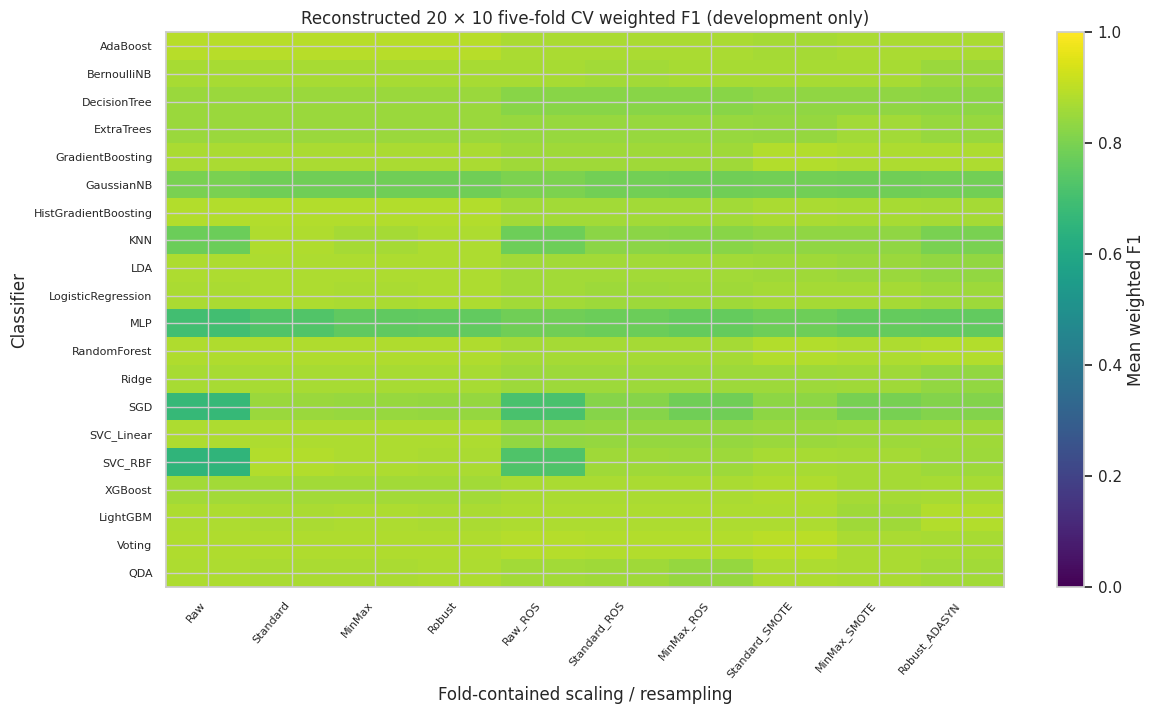

      classifier  configuration  weighted_f1_mean  weighted_f1_sd  recurrence_f1_mean  recall_mean  balanced_accuracy_mean  completed_folds
          Voting Standard_SMOTE            0.8950          0.0294              0.8118       0.8020                  0.8669                5
        AdaBoost         MinMax            0.8920          0.0486              0.8071       0.8013                  0.8643                5
        AdaBoost       Standard            0.8920          0.0486              0.8071       0.8013                  0.8643                5
        AdaBoost            Raw            0.8920          0.0486              0.8071       0.8013                  0.8643                5
        AdaBoost         Robust            0.8920          0.0486              0.8071       0.8013                  0.8643                5
          Voting        Raw_ROS            0.8896          0.0369              0.8067       0.8248                  0.8692                5
GradientBoosting Sta

290

In [58]:
if RUN_FULL_ORIGINAL:
    full200_df=pd.DataFrame(full200)
    top200=(full200_df.groupby(['classifier','configuration'])[['weighted_f1','recurrence_f1',
        'recurrence_recall','balanced_accuracy','mcc']].agg(['mean','std']).round(4))
    top200.to_csv(OUTPUT/'ORIG_200_pipeline_summary_mean_sd.csv')
    desc=(full200_df.groupby(['classifier','configuration']).agg(weighted_f1_mean=('weighted_f1','mean'),
          weighted_f1_sd=('weighted_f1','std'),recurrence_f1_mean=('recurrence_f1','mean'),
          recall_mean=('recurrence_recall','mean'),balanced_accuracy_mean=('balanced_accuracy','mean'),
          completed_folds=('fold','count')).reset_index().sort_values('weighted_f1_mean',ascending=False))
    desc.head(20).to_csv(OUTPUT/'ORIG_200_top20_reconstructed_pipelines.csv',index=False)
    heat=desc.pivot(index='classifier',columns='configuration',values='weighted_f1_mean')
    heat=heat.reindex(index=CLASSIFIER_20,columns=list(CONFIG_10))
    fig,ax=plt.subplots(figsize=(12.4,7.3))
    z=ax.imshow(heat.to_numpy(),cmap='viridis',aspect='auto',vmin=0,vmax=1)
    ax.set_xticks(np.arange(len(CONFIG_10)),list(CONFIG_10),rotation=50,ha='right',fontsize=8)
    ax.set_yticks(np.arange(len(CLASSIFIER_20)),list(CLASSIFIER_20),fontsize=8)
    ax.set(xlabel='Fold-contained scaling / resampling',ylabel='Classifier',
           title='Reconstructed 20 × 10 five-fold CV weighted F1 (development only)')
    fig.colorbar(z,ax=ax,label='Mean weighted F1');fig.tight_layout()
    fig.savefig(OUTPUT/'ORIG_200_reconstructed_heatmap.png',dpi=320,bbox_inches='tight');plt.show()
    print(desc.head(12).round(4).to_string(index=False))
else:
    desc=pd.DataFrame();print('No original-reconstruction plot in FAST_MODE')
(OUTPUT/'ORIG_200_reconstruction_manifest.json').write_text(json.dumps({
 'ran_full_200':RUN_FULL_ORIGINAL,'intended_pipelines':200,'intended_model_fits':1000,
 'completed_model_fits':len(full200),'failed_model_fits':len(full200_failures),
 'historical_exact_settings_available':False,
 'no_claim_of_exact_replication':True,'settings':'ORIG_200_all_classifier_parameters.json'},indent=2))

In [59]:
orig_model_settings={name:original_estimator(name).get_params(deep=True) if (
    name!='LightGBM' or ORIG_HAS_LIGHTGBM) else {'error':'not installed'} for name in CLASSIFIER_20}
(OUTPUT/'ORIG_200_all_classifier_parameters.json').write_text(json.dumps(orig_model_settings,indent=2,default=str))
if RUN_FULL_ORIGINAL:
    complete=len(full200)==1000 and len(full200_failures)==0
    print('ALL 200 pipelines × 5 folds completed:',complete)
    if not complete:print('NOT AN EXACT COMPLETE RECONSTRUCTION. Check failure log before submission.')

ALL 200 pipelines × 5 folds completed: True


### 18R.3 Explainability: native TreeSHAP, 17-source-feature aggregation, and local contributions

For XGBoost the notebook uses **native TreeSHAP contributions** from the fitted XGBoost booster, avoiding a dependency on version-specific `shap` plotting APIs. Each one-hot level is mapped back to its original clinical variable, with normalized mean absolute contributions and an individual-level contribution plot. Unlike causal effects, these represent properties of the fitted model. SHAP is computed **after** the model-selection process; no importance-derived feature changes are made.

In [60]:
from xgboost import DMatrix
xai_est=fitted['XGB_raw']
transformer=xai_est.named_steps['preprocess']
enc_x=transformer.transform(Xtest)
enc_names=list(transformer.get_feature_names_out())
booster=xai_est.named_steps['model'].get_booster()
contrib=booster.predict(DMatrix(enc_x),pred_contribs=True)
assert contrib.shape==(len(Xtest),len(enc_names)+1),(contrib.shape,len(enc_names))
original_columns=list(X.columns)
def source_for_encoded_feature(ename):
    bare=ename.split('__',1)[-1]
    if bare=='Age':return 'Age'
    matches=[src for src in original_columns if bare.startswith(src+'_')]
    return sorted(matches,key=len,reverse=True)[0] if matches else 'Unknown:'+ename
mapping=pd.DataFrame({'encoded_feature':enc_names,'original_feature':[source_for_encoded_feature(x) for x in enc_names]})
mapping.to_csv(OUTPUT/'ORIG_SHAP_onehot_to_source_mapping.csv',index=False)
contrib_df=pd.DataFrame(contrib[:,:-1],columns=enc_names)
source_shap=pd.DataFrame({src:contrib_df[mapping.loc[mapping.original_feature==src,'encoded_feature']]
                            .sum(axis=1) for src in original_columns})
# Manuscript convention: sum the absolute SHAP magnitudes over all one-hot levels, per source.
shap_magnitude=pd.Series({src:contrib_df[mapping.loc[mapping.original_feature==src,
                           'encoded_feature']].abs().sum(axis=1).mean()
                          for src in original_columns}).sort_values(ascending=False)
shap_report=pd.DataFrame({'feature':shap_magnitude.index,'mean_abs_shap_log_odds':shap_magnitude.values})
shap_report['normalized_shap']=shap_report.mean_abs_shap_log_odds/shap_report.mean_abs_shap_log_odds.max()
shap_report.to_csv(OUTPUT/'ORIG_TreeSHAP_all_clinical_features.csv',index=False)
print(shap_report.head(12).round(4).to_string(index=False))

             feature  mean_abs_shap_log_odds  normalized_shap
                Risk                  2.8025           1.0000
                 Age                  1.3304           0.4747
          Adenopathy                  0.7509           0.2680
                   T                  0.7368           0.2629
Physical Examination                  0.6876           0.2454
                   N                  0.6730           0.2401
              Gender                  0.5832           0.2081
           Pathology                  0.2368           0.0845
            Focality                  0.1576           0.0562
    Thyroid Function                  0.1516           0.0541
             Smoking                  0.1124           0.0401
               Stage                  0.0859           0.0307


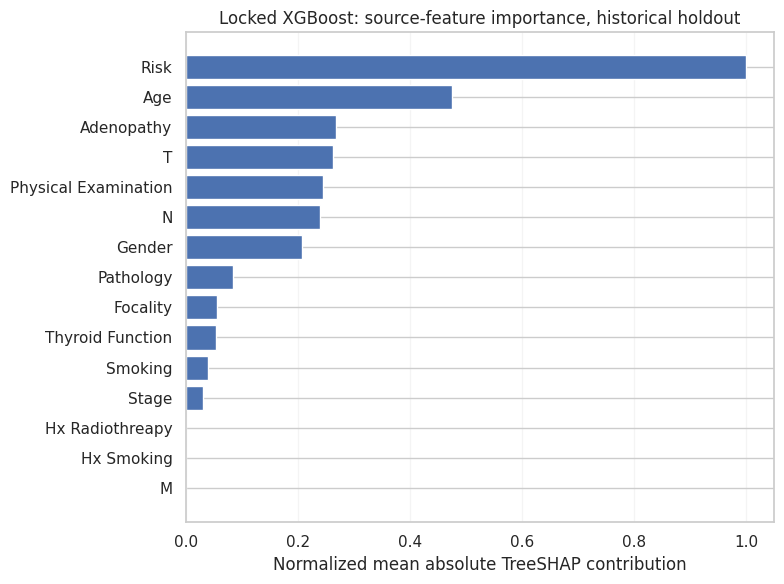

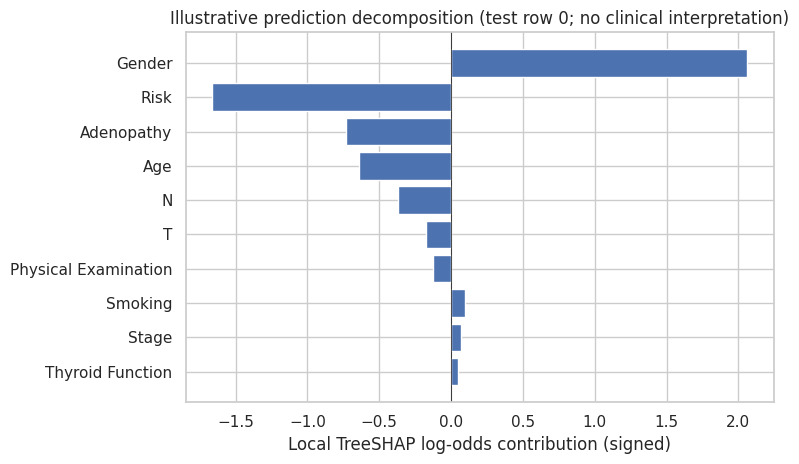

Max SHAP logit reconstruction deviation: 0.0001506805419921875


In [61]:
fig,ax=plt.subplots(figsize=(8,6))
shap_top=shap_report.head(15).iloc[::-1]
ax.barh(shap_top.feature,shap_top.normalized_shap)
ax.set(xlabel='Normalized mean absolute TreeSHAP contribution',
 title='Locked XGBoost: source-feature importance, historical holdout')
ax.grid(axis='x',alpha=.2);fig.tight_layout()
fig.savefig(OUTPUT/'ORIG_SHAP_source_importance.png',dpi=320,bbox_inches='tight');plt.show()
# Local prediction explanation for one deterministic record chosen without looking at its outcome.
row_i=0
local=source_shap.iloc[row_i].sort_values(key=lambda col:col.abs(),ascending=False).head(10)
fig,ax=plt.subplots(figsize=(8,4.8));loc=local.iloc[::-1]
ax.barh(loc.index,loc.values);ax.axvline(0,lw=.5,color='black')
ax.set(xlabel='Local TreeSHAP log-odds contribution (signed)',
 title='Illustrative prediction decomposition (test row 0; no clinical interpretation)')
fig.tight_layout();fig.savefig(OUTPUT/'ORIG_SHAP_example_local.png',dpi=300,bbox_inches='tight');plt.show()
shap_decomposition_error=float(np.max(np.abs(contrib.sum(axis=1) -
                              np.log(np.clip(holdout_proba['XGB_raw'],1e-9,1-1e-9)/
                                  np.clip(1-holdout_proba['XGB_raw'],1e-9,1-1e-9)))))
print('Max SHAP logit reconstruction deviation:',shap_decomposition_error)

### 18R.4 Independent `Response` temporal-availability sensitivity (non-deployable)

Repeat the paper's post-treatment-variable ablation by refitting XGBoost with `Response` restored, **solely** to demonstrate how a downstream feature changes apparent performance. This is not a valid baseline risk model. Training and test indices remain the originally fixed ones; the new fit is never used to select the actual clinical prediction pipeline.

In [62]:
X_with_response=raw_df.drop(columns=['Recurred']).copy()
X_with_response['Age']=pd.to_numeric(X_with_response['Age'],errors='raise')
assert 'Response' in X_with_response and 'Response' not in Xdev
all_with_response=list(X_with_response.columns)
response_model=Pipeline([('preprocess',preprocessing(all_with_response,'raw')),('model',xgb())])
response_model.fit(X_with_response.iloc[train_idx],ydev)
response_test_probability=response_model.predict_proba(X_with_response.iloc[test_idx])[:,1]
response_ablation=pd.DataFrame([
 {'task':'Valid clinicopathological time point','Response_present':False,
       **evaluate(ytest,holdout_proba['XGB_raw'])},
 {'task':'Artificial post-treatment response sensitivity','Response_present':True,
       **evaluate(ytest,response_test_probability)}])
response_ablation.to_csv(OUTPUT/'ORIG_response_temporal_ablation_reconstructed.csv',index=False)
dump(response_model,OUTPUT/'ORIG_response_temporal_sensitivity_DO_NOT_DEPLOY.joblib')
print(response_ablation[['task','accuracy','weighted_f1','recurrence_recall','roc_auc','tn','fp','fn','tp']].round(3).to_string(index=False))

                                          task  accuracy  weighted_f1  recurrence_recall  roc_auc  tn  fp  fn  tp
          Valid clinicopathological time point     0.909        0.911              0.909    0.949  50   5   2  20
Artificial post-treatment response sensitivity     0.961        0.961              0.955    0.995  53   2   1  21


## 18A. Advanced predictive modeling: controlled improvement, not test-set optimization

**Purpose.** Reviewer 2 specifically asks whether a sophisticated ML model adds value over ATA Risk and Risk+Adenopathy. The following **additional** analyses test modern tabular algorithms, fold-contained clinical interactions and tuning, without modifying the reported original XGBoost result.

**Improvement rule:** no technique is assumed to improve accuracy. All candidate outcomes, including declines, are exported. The historical 77-person test data are **not used for model/hyperparameter/threshold selection**. Development-side nested cross-validation is the primary evidence; evaluation on the already-reported historical test is a secondary sensitivity comparison, not new independent validation.

**Methodological hierarchy:** source verification → group-collision audit → clinical baselines → fold-contained training and tuning → nested outer-fold predictions → training-only selection → diagnostic historical test. Larger ROC-AUC alone does not establish clinical improvement; assess recurrence sensitivity, F1, false negatives, calibration and decision utility together.

In [63]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.inspection import permutation_importance
from scipy.stats import binomtest
import time
# Advanced analysis runs at higher cost: on Kaggle prefer CPU with Internet ON.
ADV_INNER_SPLITS = 2 if FAST_MODE else 3
ADV_OUTER_SPLITS = 3 if FAST_MODE else 5
ADV_TRIALS = 2 if FAST_MODE else 8
ADV_PERMUTATIONS = 2 if FAST_MODE else 6
ADV_BOOTSTRAPS = 150 if FAST_MODE else 2000
print('Advanced plan:',ADV_OUTER_SPLITS,'outer folds x',ADV_TRIALS,'random configurations x',ADV_INNER_SPLITS,'inner folds')

Advanced plan: 5 outer folds x 8 random configurations x 3 inner folds


### 18A.1 Fold-safe, clinically intelligible interaction features

Explicit source-feature combinations are generated **inside** the estimator pipeline; categorical encoders are then fitted separately in each fold. No post-treatment `Response`, recurrence outcome, or test-set statistics are used to construct inputs. Interaction features are an exploratory hypothesis; their measured value will be reported even if it is negative.

In [64]:
class ClinicalInteractions(BaseEstimator, TransformerMixin):
    def __init__(self, enabled=False): self.enabled=enabled
    def fit(self, X, y=None):
        if not isinstance(X,pd.DataFrame): raise TypeError('ClinicalInteractions expects source DataFrame')
        self.columns_in_=tuple(X.columns)
        return self
    def transform(self,X):
        D=X.copy()
        if self.enabled:
            for a,b,dest in [('Risk','Adenopathy','Risk_x_Adenopathy'),
                              ('T','N','T_x_N'),('Risk','T','Risk_x_T')]:
                if a in D.columns and b in D.columns:
                    D[dest]=D[a].astype(str)+'__'+D[b].astype(str)
        return D
INTERACTION_COLS=[]
for a,b,c in [('Risk','Adenopathy','Risk_x_Adenopathy'),('T','N','T_x_N'),('Risk','T','Risk_x_T')]:
    if a in Xdev.columns and b in Xdev.columns:INTERACTION_COLS.append(c)
print('Potential new interaction features:',INTERACTION_COLS)

Potential new interaction features: ['Risk_x_Adenopathy', 'T_x_N', 'Risk_x_T']


### 18A.2 Models and distributions, versioned and deterministic

Includes tuned XGBoost, ExtraTrees and Random Forest, plus CatBoost and LightGBM when installed. CatBoost/LightGBM are **optional**: the notebook does not silently change to a different model when a dependency is unavailable. All candidates use identical core predictors and fold-contained encoding. Search spaces were chosen before the historical test comparison; random trial draws are reproducible.

In [65]:
from scipy.stats import randint, uniform, loguniform
AVAILABLE_ADV=['XGB','ExtraTrees','RandomForest']
OPTIONAL_MISSING=[]
try:
    from catboost import CatBoostClassifier
    AVAILABLE_ADV.append('CatBoost')
except ImportError:
    OPTIONAL_MISSING.append('catboost')
try:
    from lightgbm import LGBMClassifier
    AVAILABLE_ADV.append('LightGBM')
except ImportError:
    OPTIONAL_MISSING.append('lightgbm')
print('Candidate families:',AVAILABLE_ADV)
if OPTIONAL_MISSING: print('OPTIONAL MODELS OMITTED (not errors):',OPTIONAL_MISSING,
                           '| Install with !pip install catboost lightgbm and rerun to compare all families')
def advanced_model(name):
    if name=='XGB': return XGBClassifier(n_estimators=180,eval_metric='logloss',objective='binary:logistic',
                        tree_method='hist',random_state=SEED,n_jobs=1,verbosity=0)
    if name=='ExtraTrees':return ExtraTreesClassifier(n_estimators=200,random_state=SEED,n_jobs=1)
    if name=='RandomForest':return RandomForestClassifier(n_estimators=200,random_state=SEED,n_jobs=1)
    if name=='CatBoost':return CatBoostClassifier(iterations=250,loss_function='Logloss',verbose=False,
                                  random_seed=SEED,thread_count=1,allow_writing_files=False)
    if name=='LightGBM':return LGBMClassifier(n_estimators=200,random_state=SEED,n_jobs=1,verbosity=-1)
    raise KeyError(name)

Candidate families: ['XGB', 'ExtraTrees', 'RandomForest', 'CatBoost', 'LightGBM']


In [66]:
def advanced_space(name):
    p='model__'
    if name=='XGB':return {p+'n_estimators':[100,180,260,400],p+'max_depth':[2,3,4,5],
        p+'learning_rate':[.02,.04,.07,.12],p+'min_child_weight':[1,2,5,9],
        p+'subsample':[.75,.9,1.],p+'colsample_bytree':[.7,.85,1.],
        p+'reg_lambda':[1,3,8],p+'scale_pos_weight':[1.,1.4,2.]}
    if name in ('RandomForest','ExtraTrees'):return {p+'n_estimators':[150,300,500],
        p+'max_features':['sqrt',.65,1.],p+'max_depth':[None,4,6,10],
        p+'min_samples_leaf':[1,2,4,7],p+'class_weight':[None,'balanced']}
    if name=='CatBoost':return {p+'iterations':[150,250,400],p+'depth':[3,4,5,6],
        p+'learning_rate':[.025,.05,.1],p+'l2_leaf_reg':[3,6,10],p+'auto_class_weights':[None,'Balanced']}
    if name=='LightGBM':return {p+'n_estimators':[100,200,350],p+'num_leaves':[7,15,31],
        p+'learning_rate':[.02,.05,.1],p+'min_child_samples':[5,10,20],
        p+'reg_lambda':[0.,1.,5.],p+'class_weight':[None,'balanced']}
    raise KeyError(name)
def advanced_pipeline(name,interaction=False):
    columns=ALL_PREDICTORS+(INTERACTION_COLS if interaction else [])
    return Pipeline([('clinical_interactions',ClinicalInteractions(enabled=interaction)),
       ('preprocess',preprocessing(columns,'raw')),('model',advanced_model(name))])
def advanced_search(name,seed,interaction=False,n_trials=ADV_TRIALS,inner_splits=ADV_INNER_SPLITS):
    cv=StratifiedKFold(n_splits=inner_splits,shuffle=True,random_state=seed+100)
    return RandomizedSearchCV(advanced_pipeline(name,interaction),advanced_space(name),
         n_iter=n_trials,scoring={'ap':'average_precision','f1_rec':'f1','f1w':'f1_weighted',
                                  'bacc':'balanced_accuracy','auc':'roc_auc'},
         refit='ap',cv=cv,random_state=seed,n_jobs=1,error_score='raise',return_train_score=False)
print('Fold-wise AP-ranked randomized search ready; full chosen parameters saved later.')

Fold-wise AP-ranked randomized search ready; full chosen parameters saved later.


### 18B. Training-only nested evaluation with fold-specific tuning

At each outer fold, **every candidate is retuned using only outer-training data**. The model family is selected on its inner cross-validated average precision. Outer validation observations are never used during selection. Accumulated outer-fold probabilities provide an out-of-sample diagnostic of the **adaptive selection procedure**. Its five outer folds constitute one cross-validation run, not a formal external validation cohort.

In [67]:
ADV_OUTER=StratifiedKFold(n_splits=ADV_OUTER_SPLITS,shuffle=True,random_state=SEED+140)
advanced_outer_rows=[];advanced_inner_rows=[];advanced_oof=np.full(len(ydev),np.nan)
advanced_fold_choice=np.full(len(ydev),'',dtype=object)
start=time.time()
for fold,(tr,va) in enumerate(ADV_OUTER.split(Xdev,ydev),1):
    candidates=[]
    for family in AVAILABLE_ADV:
        try:
            tuner=advanced_search(family,SEED+1000*fold+len(family));tuner.fit(Xdev.iloc[tr],ydev.iloc[tr])
            inner_ap=float(tuner.best_score_)
            candidates.append((inner_ap,family,tuner.best_estimator_))
            advanced_inner_rows.append({'outer_fold':fold,'family':family,'inner_cv_ap':inner_ap,
                       'best_parameters':json.dumps(tuner.best_params_,default=str,sort_keys=True)})
        except Exception as exc:
            advanced_inner_rows.append({'outer_fold':fold,'family':family,'error':repr(exc)[:350]})
            print('Search failed:',fold,family,repr(exc)[:180])
    if not candidates:raise RuntimeError('All advanced families failed in outer fold '+str(fold))
    candidates.sort(key=lambda s:(-s[0],AVAILABLE_ADV.index(s[1])))
    best_ap,family,best_est=candidates[0]
    prob=best_est.predict_proba(Xdev.iloc[va])[:,1]
    advanced_oof[va]=prob;advanced_fold_choice[va]=family
    advanced_outer_rows.append({'outer_fold':fold,'chosen_family':family,
             'inner_cv_average_precision':best_ap,'n_train':len(tr),'n_valid':len(va),
             **evaluate(ydev.iloc[va],prob)})
    print('Outer fold',fold,'selected',family,'inner AP',round(best_ap,3),
          'valid AP',round(average_precision_score(ydev.iloc[va],prob),3))
assert np.isfinite(advanced_oof).all() and all(advanced_fold_choice)
advanced_outer=pd.DataFrame(advanced_outer_rows)
advanced_outer.to_csv(OUTPUT/'ADV_nested_outer_each_fold.csv',index=False)
pd.DataFrame(advanced_inner_rows).to_csv(OUTPUT/'ADV_nested_all_inner_model_scores.csv',index=False)
print('Outer adaptive procedure pooled OOF:',{k:round(v,3) for k,v in evaluate(ydev,advanced_oof).items()
      if k in ('average_precision','weighted_f1','recurrence_f1','balanced_accuracy','roc_auc','brier')})
print('Advanced nested time (min):',round((time.time()-start)/60,2))

Search failed: 1 CatBoost CatBoostError('catboost/private/libs/options/json_helper.h:41: Can\'t parse parameter "auto_class_weights" with value: null')


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, 

Outer fold 1 selected RandomForest inner AP 0.867 valid AP 0.877
Search failed: 2 CatBoost CatBoostError('catboost/private/libs/options/json_helper.h:41: Can\'t parse parameter "auto_class_weights" with value: null')


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, 

Outer fold 2 selected XGB inner AP 0.89 valid AP 0.795
Search failed: 3 CatBoost CatBoostError('catboost/private/libs/options/json_helper.h:41: Can\'t parse parameter "auto_class_weights" with value: null')


...

Outer fold 3 selected RandomForest inner AP 0.888 valid AP 0.837
Search failed: 4 CatBoost CatBoostError('catboost/private/libs/options/json_helper.h:41: Can\'t parse parameter "auto_class_weights" with value: null')


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, 

Outer fold 4 selected RandomForest inner AP 0.846 valid AP 0.958
Search failed: 5 CatBoost CatBoostError('catboost/private/libs/options/json_helper.h:41: Can\'t parse parameter "auto_class_weights" with value: null')


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, 

Outer fold 5 selected RandomForest inner AP 0.862 valid AP 0.88
Outer adaptive procedure pooled OOF: {'weighted_f1': 0.872, 'recurrence_f1': 0.769, 'balanced_accuracy': np.float64(0.837), 'brier': np.float64(0.093), 'roc_auc': np.float64(0.909), 'average_precision': np.float64(0.863)}
Advanced nested time (min): 2.43


### 18B.1 Conservative improvement gate set from matching outer folds, before historical-test inspection

Protect the **original** XGBoost benchmark against unsupported claims of universal improvement. Using the same outer development folds, evaluate locked original XGBoost and the two prespecified logistic clinical comparators. The advanced procedure is recommended as a candidate only if its development nested predictions improve average precision, preserve weighted and recurrence-class F1, and do not materially worsen Brier score. Failing this gate retains original XGBoost as the preferred candidate; it does **not** hide the other experiments or prove original accuracy will improve on new patients. This gate itself is a training-based exploratory rule and its selection optimism should be stated.

In [68]:
orig_matched=np.full(len(ydev),np.nan)
clinical_matched=np.full(len(ydev),np.nan)
ata_matched=np.full(len(ydev),np.nan)
for tr,va in ADV_OUTER.split(Xdev,ydev):
    for family,arr in [('XGB_raw',orig_matched),('Risk_Adenopathy_LR',clinical_matched),
                       ('ATA_Risk_only',ata_matched)]:
        baseline=build_model(family);baseline.fit(Xdev.iloc[tr],ydev.iloc[tr])
        arr[va]=baseline.predict_proba(Xdev.iloc[va])[:,1]
assert all(np.isfinite(p).all() for p in (orig_matched,clinical_matched,ata_matched))
gate_old=evaluate(ydev,orig_matched);gate_advanced=evaluate(ydev,advanced_oof)
ADV_PASSES_GATE=bool(
    gate_advanced['average_precision'] > gate_old['average_precision']+0.005 and
    gate_advanced['weighted_f1'] >= gate_old['weighted_f1']-0.005 and
    gate_advanced['recurrence_f1'] >= gate_old['recurrence_f1']-0.005 and
    gate_advanced['brier'] <= gate_old['brier']+0.025)
ADV_RECOMMENDATION='advanced_candidate' if ADV_PASSES_GATE else 'original_XGB_retained'
gate_record={'recommended_candidate':ADV_RECOMMENDATION,'gate_passed':ADV_PASSES_GATE,
 'comparison_partition':'matching development outer folds only',
 'gate_conditions':{'AP_gain_strictly_greater_than':0.005,
   'maximum_allowed_weighted_F1_drop':0.005,'maximum_allowed_recurrence_F1_drop':0.005,
   'maximum_allowed_Brier_increase':0.025},
 'original':{m:float(gate_old[m]) for m in ['average_precision','weighted_f1','recurrence_f1','brier']},
 'advanced':{m:float(gate_advanced[m]) for m in ['average_precision','weighted_f1','recurrence_f1','brier']},
 'caution':'This is an exploratory training-side gate; external test performance not guaranteed'}
(OUTPUT/'ADV_development_only_model_gate.json').write_text(json.dumps(gate_record,indent=2))
print('Training-only gate recommendation:',ADV_RECOMMENDATION)
print('Previous model metrics:',gate_record['original'])
print('Advanced nested metrics:',gate_record['advanced'])

Training-only gate recommendation: advanced_candidate
Previous model metrics: {'average_precision': 0.8445721129814653, 'weighted_f1': 0.8466742071849039, 'recurrence_f1': 0.7283236994219653, 'brier': 0.11380089598697252}
Advanced nested metrics: {'average_precision': 0.8628279532486285, 'weighted_f1': 0.8718493474833934, 'recurrence_f1': 0.7692307692307693, 'brier': 0.09297966223507753}


### 18C. Select and lock the final advanced model *before* accessing the historical test

Rerun tuning on all 306 development cases. Select the winning **family and hyperparameters by development-only inner CV average precision**. The locked candidate is retained regardless of its historical-test performance. A higher AP is not a promise of superior fixed-threshold accuracy or clinical utility; all metrics will be disclosed.

In [69]:
family_search_rows=[];advanced_final_tuners={}
for family in AVAILABLE_ADV:
    try:
        search=advanced_search(family,seed=SEED+9000+len(family))
        search.fit(Xdev,ydev)
        advanced_final_tuners[family]=search
        family_search_rows.append({'family':family,'cv_ap':float(search.best_score_),
             'best_params':json.dumps(search.best_params_,sort_keys=True,default=str)})
    except Exception as exc:
        family_search_rows.append({'family':family,'error':repr(exc)[:350]})
family_df=pd.DataFrame(family_search_rows)
family_df.to_csv(OUTPUT/'ADV_full_development_tuning.csv',index=False)
assert advanced_final_tuners,'All final advanced searches failed'
FINAL_ADV_FAMILY=sorted(advanced_final_tuners,
    key=lambda family:(-advanced_final_tuners[family].best_score_,AVAILABLE_ADV.index(family)))[0]
FINAL_ADV_MODEL=advanced_final_tuners[FINAL_ADV_FAMILY].best_estimator_
FINAL_ADV_PARAMETERS=advanced_final_tuners[FINAL_ADV_FAMILY].best_params_
dump(FINAL_ADV_MODEL,OUTPUT/'ADV_locked_train_selected_model.joblib')
(OUTPUT/'ADV_locked_selection.json').write_text(json.dumps({
 'family':FINAL_ADV_FAMILY,'training_cv_AP':float(advanced_final_tuners[FINAL_ADV_FAMILY].best_score_),
 'parameters':FINAL_ADV_PARAMETERS,'selected_without_test_data':True,
 'train_only_gate_recommendation':ADV_RECOMMENDATION,
 'optimism_caution':'Full development tuning score is model-selection biased; use nested outer for evidence'},indent=2))
print('LOCKED selected advanced family (development only):',FINAL_ADV_FAMILY)
print('Best CV AP:',round(advanced_final_tuners[FINAL_ADV_FAMILY].best_score_,4))
print('Parameters:',FINAL_ADV_PARAMETERS)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, 

LOCKED selected advanced family (development only): XGB
Best CV AP: 0.8838
Parameters: {'model__subsample': 0.9, 'model__scale_pos_weight': 1.0, 'model__reg_lambda': 8, 'model__n_estimators': 180, 'model__min_child_weight': 2, 'model__max_depth': 4, 'model__learning_rate': 0.12, 'model__colsample_bytree': 0.7}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names



### 18D. Properly separate clinical gain, calibrated probabilities, and threshold changes

The advanced model is assessed on the original historical holdout only **after** development-only selection. The primary old XGBoost remains unchanged. Pairwise bootstrap is descriptive; a gain in accuracy accompanied by more missed recurrences is not labeled an unqualified improvement. Numerical comparisons in this section are not fresh external validation.

In [70]:
ADV_test_p=FINAL_ADV_MODEL.predict_proba(Xtest)[:,1]
advanced_holdout=pd.DataFrame([
 {'model':'Original_XGB_raw','phase':'historically_reported_holdout',**evaluate(ytest,holdout_proba['XGB_raw'])},
 {'model':'Clinical_ATA_Risk','phase':'historically_reported_holdout',**evaluate(ytest,holdout_proba['ATA_Risk_only'])},
 {'model':'Clinical_Risk_Adenopathy','phase':'historically_reported_holdout',**evaluate(ytest,holdout_proba['Risk_Adenopathy_LR'])},
 {'model':'Advanced_train_selected_'+FINAL_ADV_FAMILY,'phase':'historically_reported_holdout',**evaluate(ytest,ADV_test_p)}])
advanced_holdout.to_csv(OUTPUT/'ADV_historical_holdout_ALL_models.csv',index=False)
adv_pair=paired_bootstrap(ytest,ADV_test_p,holdout_proba['XGB_raw'],nboot=ADV_BOOTSTRAPS,seed=SEED+902)
adv_pair.insert(0,'comparison','Advanced minus original XGB')
adv_pair.to_csv(OUTPUT/'ADV_paired_ci_advanced_minus_original.csv',index=False)
compare=pd.DataFrame({'row_index':test_idx,'target':ytest.to_numpy(),
   'original_XGB_probability':holdout_proba['XGB_raw'],'advanced_locked_probability':ADV_test_p})
compare.to_csv(OUTPUT/'ADV_historical_test_predictions.csv',index=False)
print(advanced_holdout[['model','accuracy','recurrence_f1','recurrence_recall','balanced_accuracy','roc_auc','brier']].round(3).to_string(index=False))

                      model  accuracy  recurrence_f1  recurrence_recall  balanced_accuracy  roc_auc  brier
           Original_XGB_raw     0.909          0.851              0.909              0.909    0.949  0.083
          Clinical_ATA_Risk     0.883          0.824              0.955              0.905    0.928  0.085
   Clinical_Risk_Adenopathy     0.922          0.857              0.818              0.891    0.950  0.071
Advanced_train_selected_XGB     0.857          0.766              0.818              0.845    0.954  0.081


### 18E. Prospective threshold choice from development probabilities only

The clinical need to avoid false negatives suggests exploring a lower recurrence-risk threshold, but a lower threshold may increase false positives and reduce accuracy. **The reviewer cannot reasonably require every metric to improve simultaneously.** A risk threshold is selected using nested outer-fold development predictions only. A conservative score rewards recurrence F1 while respecting a prespecified specificity floor. Applied historical-test performance is explicitly secondary and all four confusion-matrix cells are reported.

In [71]:
# Decision rule locked before viewing advanced historical-test thresholded results:
# seek high recurrence-class F1 with >= 0.80 specificity in nested development OOF.
adv_threshold_grid=np.round(np.arange(.10,.711,.01),2)
adv_threshold_rows=[]
for cutoff in adv_threshold_grid:
    measures=evaluate(ydev,advanced_oof,threshold=float(cutoff))
    adv_threshold_rows.append({'threshold':float(cutoff),**measures})
adv_thresh_table=pd.DataFrame(adv_threshold_rows)
adv_thresh_table.to_csv(OUTPUT/'ADV_development_OOF_threshold_sweep.csv',index=False)
allowed=adv_thresh_table.loc[adv_thresh_table.specificity>=.80].copy()
if allowed.empty: allowed=adv_thresh_table.copy()
# In equal F1, favor greater specificity; deterministic tie break closer to 0.5.
ordered=allowed.sort_values(['recurrence_f1','specificity','threshold'],ascending=[False,False,True])
ADV_SELECTED_THRESHOLD=float(ordered.iloc[0].threshold)
(OUTPUT/'ADV_prespecified_threshold.json').write_text(json.dumps({'selection_sample':'nested-development-OOF',
     'objective':'maximize recurrence F1 subject to specificity >=0.80',
     'risk_threshold':ADV_SELECTED_THRESHOLD,'test_used_to_select':False},indent=2))
threshold_eval=pd.DataFrame([
 {'comparison':'Advanced_at_0.5','threshold':0.5,**evaluate(ytest,ADV_test_p,0.5)},
 {'comparison':'Advanced_development_selected','threshold':ADV_SELECTED_THRESHOLD,
  **evaluate(ytest,ADV_test_p,ADV_SELECTED_THRESHOLD)},
 {'comparison':'Original_XGB_at_0.5','threshold':0.5,**evaluate(ytest,holdout_proba['XGB_raw'],0.5)}])
threshold_eval.to_csv(OUTPUT/'ADV_historical_test_threshold_comparison.csv',index=False)
print('Selected without historical-test labels:',ADV_SELECTED_THRESHOLD)
print(threshold_eval[['comparison','accuracy','recurrence_f1','recurrence_recall','specificity','tn','fp','fn','tp']].round(3).to_string(index=False))

Selected without historical-test labels: 0.35
                   comparison  accuracy  recurrence_f1  recurrence_recall  specificity  tn  fp  fn  tp
              Advanced_at_0.5     0.857          0.766              0.818        0.873  48   7   4  18
Advanced_development_selected     0.870          0.800              0.909        0.855  47   8   2  20
          Original_XGB_at_0.5     0.909          0.851              0.909        0.909  50   5   2  20


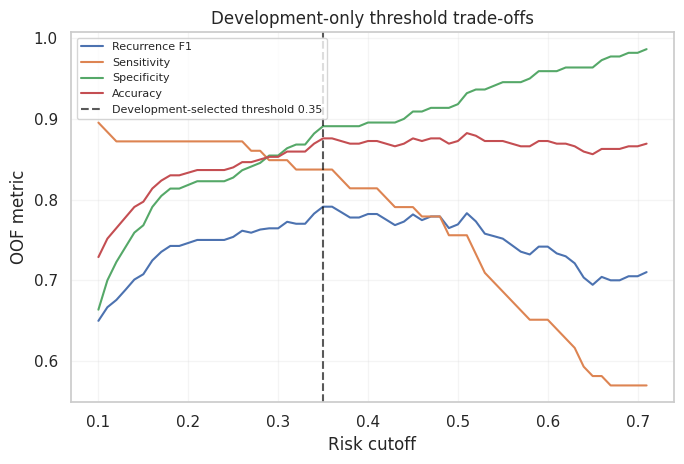

In [72]:
fig,ax=plt.subplots(figsize=(7,4.8))
ax.plot(adv_thresh_table.threshold,adv_thresh_table.recurrence_f1,label='Recurrence F1')
ax.plot(adv_thresh_table.threshold,adv_thresh_table.recurrence_recall,label='Sensitivity')
ax.plot(adv_thresh_table.threshold,adv_thresh_table.specificity,label='Specificity')
ax.plot(adv_thresh_table.threshold,adv_thresh_table.accuracy,label='Accuracy')
ax.axvline(ADV_SELECTED_THRESHOLD,ls='--',color='black',alpha=.65,
           label=f'Development-selected threshold {ADV_SELECTED_THRESHOLD:.2f}')
ax.set(xlabel='Risk cutoff',ylabel='OOF metric',title='Development-only threshold trade-offs')
ax.legend(fontsize=8);ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(OUTPUT/'ADV_development_threshold_tradeoffs.png',dpi=300,bbox_inches='tight');plt.show()

### 18F. Repeated-fold permutation-importance stability (explainability beyond a single plot)

Instead of fitting SHAP on the previously-used 77-patient test alone, compute **held-out fold permutation importance** on five new development folds for the original locked XGBoost. This captures model-reliance stability across folds, without claiming causality. Positive values are AP decreases when a feature is shuffled; correlations among predictors and low fold event counts can make signs unstable.

In [73]:
importance_rows=[]
imp_splits=3 if FAST_MODE else 5
imp_cv=StratifiedKFold(n_splits=imp_splits,shuffle=True,random_state=SEED+310)
for fold,(tr,va) in enumerate(imp_cv.split(Xdev,ydev),1):
    est=build_model('XGB_raw');est.fit(Xdev.iloc[tr],ydev.iloc[tr])
    imp=permutation_importance(est,Xdev.iloc[va],ydev.iloc[va],n_repeats=ADV_PERMUTATIONS,
                 scoring='average_precision',random_state=SEED+fold,n_jobs=1)
    for j,feature in enumerate(Xdev.columns):
        importance_rows.append({'fold':fold,'feature':feature,'ap_decrease':float(imp.importances_mean[j]),
             'within_fold_permutation_sd':float(imp.importances_std[j])})
importance=pd.DataFrame(importance_rows)
importance.to_csv(OUTPUT/'ADV_permutation_importance_each_fold.csv',index=False)
importance_summary=importance.groupby('feature',as_index=False).agg(
    mean_ap_decrease=('ap_decrease','mean'),fold_sd=('ap_decrease','std'),
    positive_fold_fraction=('ap_decrease',lambda x:float(np.mean(np.asarray(x)>0))))
importance_summary=importance_summary.sort_values('mean_ap_decrease',ascending=False)
importance_summary.to_csv(OUTPUT/'ADV_permutation_importance_stability_summary.csv',index=False)
print(importance_summary.head(12).round(3).to_string(index=False))

             feature  mean_ap_decrease  fold_sd  positive_fold_fraction
                Risk             0.246    0.088                     1.0
                 Age             0.061    0.020                     1.0
          Adenopathy             0.059    0.037                     1.0
                   T             0.027    0.016                     1.0
                   N             0.021    0.023                     1.0
Physical Examination             0.021    0.032                     0.8
              Gender             0.015    0.023                     0.6
             Smoking             0.000    0.005                     0.4
                   M             0.000    0.000                     0.0
     Hx Radiothreapy             0.000    0.000                     0.0
          Hx Smoking             0.000    0.000                     0.0
           Pathology            -0.000    0.006                     0.4


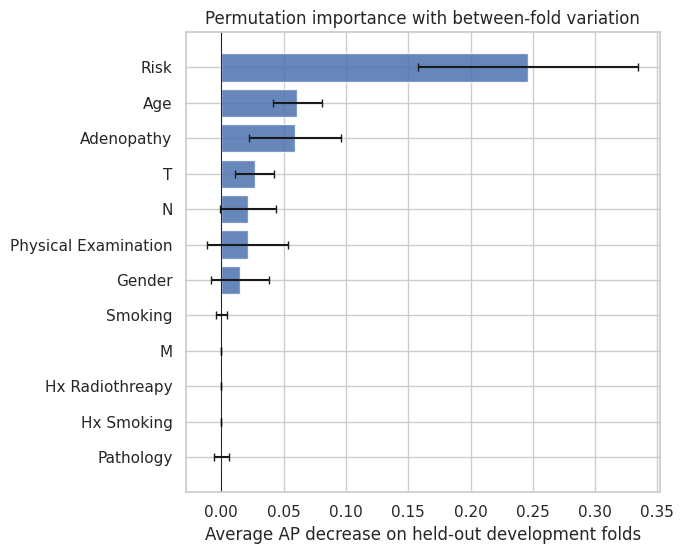

In [74]:
top=importance_summary.head(min(12,len(importance_summary))).iloc[::-1]
fig,ax=plt.subplots(figsize=(7,5.7))
ax.barh(top.feature,top.mean_ap_decrease,xerr=top.fold_sd,alpha=.85,capsize=3)
ax.axvline(0,color='black',lw=.6)
ax.set(xlabel='Average AP decrease on held-out development folds',
       title='Permutation importance with between-fold variation')
fig.tight_layout();fig.savefig(OUTPUT/'ADV_permutation_stability.png',dpi=320,bbox_inches='tight');plt.show()

### 18G. Learning curves and statistical sanity controls

Two extra tests strengthen methodological confidence: (1) a **learning curve** to assess whether the small development sample is a limiting factor and (2) label-permutation negative controls to detect gross performance inflation. The negative control shuffles training labels but evaluates against unchanged validation labels. Neither creates new clinical ground truth.

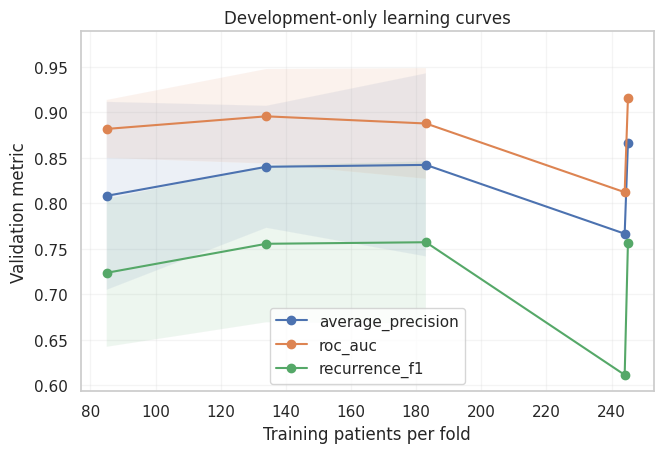

In [75]:
LEARN_FRACS=[.35,.55,.75,1.0]
learn_cv=StratifiedKFold(n_splits=3 if FAST_MODE else 5,shuffle=True,random_state=SEED+407)
learning_rows=[]
for fold,(tr,va) in enumerate(learn_cv.split(Xdev,ydev),1):
    for frac in LEARN_FRACS:
        if frac==1:sample_idx=tr
        else:
            subset_idx,_=train_test_split(tr,train_size=frac,random_state=SEED+fold+int(frac*100),
                                           stratify=ydev.iloc[tr])
            sample_idx=subset_idx
        est=build_model('XGB_raw');est.fit(Xdev.iloc[sample_idx],ydev.iloc[sample_idx])
        p=est.predict_proba(Xdev.iloc[va])[:,1]
        learning_rows.append({'fold':fold,'development_training_fraction':frac,
              'n_train':len(sample_idx),**evaluate(ydev.iloc[va],p)})
learning=pd.DataFrame(learning_rows)
learning.to_csv(OUTPUT/'ADV_learning_curve_fold_results.csv',index=False)
fig,ax=plt.subplots(figsize=(6.8,4.7))
for name in ['average_precision','roc_auc','recurrence_f1']:
    summ=learning.groupby('n_train')[name].agg(['mean','std']).reset_index().sort_values('n_train')
    ax.plot(summ.n_train,summ['mean'],marker='o',label=name)
    ax.fill_between(summ.n_train,(summ['mean']-summ['std']).clip(0),
                    (summ['mean']+summ['std']).clip(upper=1),alpha=.10)
ax.set(xlabel='Training patients per fold',ylabel='Validation metric',title='Development-only learning curves')
ax.grid(alpha=.2);ax.legend();fig.tight_layout()
fig.savefig(OUTPUT/'ADV_learning_curves.png',dpi=320,bbox_inches='tight');plt.show()

In [76]:
control_rows=[]
control_cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED+612)
rng_control=np.random.default_rng(SEED+990)
for fold,(tr,va) in enumerate(control_cv.split(Xdev,ydev),1):
    original=build_model('XGB_raw');original.fit(Xdev.iloc[tr],ydev.iloc[tr])
    genuine_p=original.predict_proba(Xdev.iloc[va])[:,1]
    control_rows.append({'fold':fold,'condition':'actual_training_labels',
         **evaluate(ydev.iloc[va],genuine_p)})
    for rep in range(2 if FAST_MODE else 5):
        shuffled=ydev.iloc[tr].to_numpy().copy();rng_control.shuffle(shuffled)
        negative=build_model('XGB_raw');negative.fit(Xdev.iloc[tr],shuffled)
        bogus=negative.predict_proba(Xdev.iloc[va])[:,1]
        control_rows.append({'fold':fold,'condition':'shuffled_training_labels',
              'permutation':rep+1,**evaluate(ydev.iloc[va],bogus)})
negative_controls=pd.DataFrame(control_rows)
negative_controls.to_csv(OUTPUT/'ADV_negative_control_label_shuffling.csv',index=False)
print(negative_controls.groupby('condition')[['roc_auc','average_precision','balanced_accuracy']].agg(['mean','std']).round(3))

                         roc_auc        average_precision         \
                            mean    std              mean    std   
condition                                                          
actual_training_labels     0.913  0.018             0.858  0.009   
shuffled_training_labels   0.509  0.086             0.311  0.069   

                         balanced_accuracy         
                                      mean    std  
condition                                          
actual_training_labels               0.831  0.018  
shuffled_training_labels             0.496  0.048  


### 18H. Split-conformal prediction sets (optional research-only uncertainty analysis)

To add a clearly distinguished *uncertainty* experiment, train an **original XGBoost** inside each development outer fold, reserve a disjoint inner calibration subset, and use a 90% split-conformal score threshold to output prediction sets (`{none}`, `{recurrence}`, `{both}`, or occasionally the empty set). This evaluates **marginal** set coverage under exchangeability assumptions, not patient safety, subgroup coverage, clinical action, or future transport. All reported coverage is based on untouched outer folds and never on the historical test.

In [77]:
def split_conformal_quantile(scores,alpha):
    scores=np.asarray(scores,dtype=float)
    k=int(np.ceil((len(scores)+1)*(1-alpha)))
    return float('inf') if k>len(scores) else float(np.sort(scores)[k-1])
conf_rows=[];conf_splits=3 if FAST_MODE else 5
conf_cv=StratifiedKFold(n_splits=conf_splits,shuffle=True,random_state=SEED+725)
for fold,(tr,va) in enumerate(conf_cv.split(Xdev,ydev),1):
    fit_idx,cal_idx=train_test_split(tr,test_size=.25,random_state=SEED+fold+721,
                                     stratify=ydev.iloc[tr])
    m=build_model('XGB_raw');m.fit(Xdev.iloc[fit_idx],ydev.iloc[fit_idx])
    cal_prob=m.predict_proba(Xdev.iloc[cal_idx])[:,1]
    cal_truth=ydev.iloc[cal_idx].to_numpy()
    scores=np.where(cal_truth==1,1-cal_prob,cal_prob)
    q=split_conformal_quantile(scores,alpha=.10)
    valid_prob=m.predict_proba(Xdev.iloc[va])[:,1]
    valid_truth=ydev.iloc[va].to_numpy()
    pred_0=valid_prob<=q;pred_1=(1-valid_prob)<=q
    covered=np.where(valid_truth==1,pred_1,pred_0)
    for i in range(len(va)):
        conf_rows.append({'fold':fold,'actual':int(valid_truth[i]),'risk':float(valid_prob[i]),
            'contains_true_label':bool(covered[i]),'set_size':int(pred_0[i])+int(pred_1[i]),
            'threshold_q':q,'contains_no_recurrence':bool(pred_0[i]),
            'contains_recurrence':bool(pred_1[i])})
conformal=pd.DataFrame(conf_rows)
conformal.to_csv(OUTPUT/'ADV_conformal_development_fold_level.csv',index=False)
conformal_summary={'nominal_marginal_coverage':.90,'observed_pooled_coverage':float(conformal.contains_true_label.mean()),
 'average_prediction_set_size':float(conformal.set_size.mean()),
 'empty_prediction_set_fraction':float((conformal.set_size==0).mean()),
 'both_labels_fraction':float((conformal.set_size==2).mean()),
 'class1_coverage_descriptive':float(conformal.loc[conformal.actual==1,'contains_true_label'].mean()),
 'not_external_validation':True}
(OUTPUT/'ADV_conformal_summary.json').write_text(json.dumps(conformal_summary,indent=2))
print(pd.Series(conformal_summary))

nominal_marginal_coverage             0.9
observed_pooled_coverage         0.901961
average_prediction_set_size      1.130719
empty_prediction_set_fraction         0.0
both_labels_fraction             0.130719
class1_coverage_descriptive      0.790698
not_external_validation              True
dtype: object


### 18I. Incremental net benefit, paired decision errors, and conservative improvement summary

A clinical model is valuable only if it improves on simple existing predictors. Recompute the **decision curves** from the fully nested development predictions, without choosing a threshold from the historical test. Export a clear comparison table stating where the advanced procedure improves, ties or deteriorates relative to the original XGBoost. No negative findings are discarded.

Comparators are evaluated on **exactly matching outer folds** computed before the historical-test comparison in §18B.1.

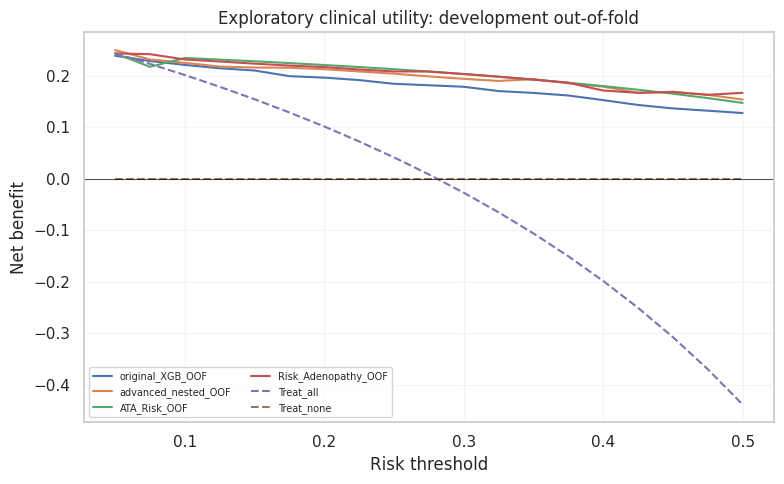

In [78]:
adv_dca=decision_curve(ydev,{'original_XGB_OOF':orig_matched,
     'advanced_nested_OOF':advanced_oof,'ATA_Risk_OOF':ata_matched,
     'Risk_Adenopathy_OOF':clinical_matched,
     'Treat_all':np.ones(len(ydev)),'Treat_none':np.zeros(len(ydev))},thresholds)
adv_dca.to_csv(OUTPUT/'ADV_development_nested_decision_curves.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
for label,part in adv_dca.groupby('strategy',sort=False):
    ax.plot(part.risk_threshold,part.net_benefit,label=label,
            ls='--' if label.startswith('Treat_') else '-')
ax.axhline(0,lw=.5,color='black');ax.set(xlabel='Risk threshold',ylabel='Net benefit',
 title='Exploratory clinical utility: development out-of-fold')
ax.legend(fontsize=7,ncol=2);ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(OUTPUT/'ADV_nested_decision_curves.png',dpi=320,bbox_inches='tight');plt.show()

In [79]:
adv_comparison=[]
for name,p in [('ATA Risk-only baseline',ata_matched),('ATA+adenopathy baseline',clinical_matched),('Original XGB',orig_matched),
               ('Nested tuned selection',advanced_oof)]:
    adv_comparison.append({'model':name,**evaluate(ydev,p)})
adv_comparison=pd.DataFrame(adv_comparison)
adv_comparison.to_csv(OUTPUT/'ADV_matching_fold_development_model_comparison.csv',index=False)
ref=adv_comparison.set_index('model').loc['Original XGB'];enh=adv_comparison.set_index('model').loc['Nested tuned selection']
benefit_metrics=['accuracy','weighted_f1','recurrence_f1','recurrence_recall','specificity',
                 'balanced_accuracy','mcc','roc_auc','average_precision','brier','log_loss']
change_summary=pd.DataFrame([{'metric':met,'original':float(ref[met]),'advanced':float(enh[met]),
    'advanced_minus_original':float(enh[met]-ref[met]),
    'advanced_direction':('improvement' if (enh[met]<ref[met] if met in ('brier','log_loss') else enh[met]>ref[met])
                          else 'tie' if np.isclose(enh[met],ref[met]) else 'decrease')}
    for met in benefit_metrics])
change_summary.to_csv(OUTPUT/'ADV_training_only_improvement_and_tradeoffs.csv',index=False)
print(adv_comparison[['model','accuracy','recurrence_recall','recurrence_f1','average_precision','brier']].round(3).to_string(index=False))
print(change_summary[['metric','advanced_direction','advanced_minus_original']].round(4).to_string(index=False))

                  model  accuracy  recurrence_recall  recurrence_f1  average_precision  brier
 ATA Risk-only baseline     0.866              0.872          0.785              0.761  0.102
ATA+adenopathy baseline     0.886              0.767          0.790              0.787  0.098
           Original XGB     0.846              0.733          0.728              0.845  0.114
 Nested tuned selection     0.873              0.756          0.769              0.863  0.093
           metric advanced_direction  advanced_minus_original
         accuracy        improvement                   0.0261
      weighted_f1        improvement                   0.0252
    recurrence_f1        improvement                   0.0409
recurrence_recall        improvement                   0.0233
      specificity        improvement                   0.0273
balanced_accuracy        improvement                   0.0253
              mcc        improvement                   0.0602
          roc_auc        improveme

### 18J. Feature-interaction gain experiment (development-only)

Check whether `Risk × Adenopathy`, `Risk × T`, and `T × N` add value to the **same locked advanced family and hyperparameters**. This is exploratory because the base parameters were previously selected using development data; no held-out test outcome influences the experiment. If interactions hurt, do not pretend they help. Pairwise fold results and coefficient of variation are exported.

In [80]:
base_family=FINAL_ADV_FAMILY
feature_rows=[];interaction_cv=StratifiedKFold(n_splits=3 if FAST_MODE else 5,
                                              shuffle=True,random_state=SEED+850)
for fold,(tr,va) in enumerate(interaction_cv.split(Xdev,ydev),1):
    for feature_mode in [False,True]:
        m=advanced_pipeline(base_family,interaction=feature_mode)
        m.set_params(**FINAL_ADV_PARAMETERS)
        m.fit(Xdev.iloc[tr],ydev.iloc[tr])
        p=m.predict_proba(Xdev.iloc[va])[:,1]
        feature_rows.append({'fold':fold,'interaction_features':feature_mode,
             'family':base_family,**evaluate(ydev.iloc[va],p)})
feature_cv=pd.DataFrame(feature_rows)
feature_cv.to_csv(OUTPUT/'ADV_clinical_interaction_fold_comparison.csv',index=False)
print(feature_cv.groupby('interaction_features')[['average_precision','weighted_f1','recurrence_f1','brier']].agg(['mean','std']).round(3))

                     average_precision        weighted_f1         \
                                  mean    std        mean    std   
interaction_features                                               
False                            0.862  0.041       0.878  0.046   
True                             0.874  0.035       0.889  0.043   

                     recurrence_f1         brier         
                              mean    std   mean    std  
interaction_features                                     
False                        0.782  0.078  0.091  0.025  
True                         0.804  0.072  0.083  0.026  


### 18K. Submission readiness: audit, manifest, and reproducibility package

This cell writes publication-ready CSV inventories and an explicit protocol summary. **Do not use `FAST_MODE` outputs for submission.** A passing software smoke test is not evidence of medical validity. Missing optional algorithms are logged, not mislabeled. The locked advanced family, its hyperparameters, and all reductions in performance are retained in the bundle. If a reconstructed historical XGBoost score differs from the article, investigate versions and one-hot coding **without tuning to match the reported test labels**.

In [81]:
advanced_protocol={'dataset_doi':'10.24432/C5632J','seed':SEED,
 'n_patients':len(y),'n_events':int(y.sum()),'historical_test_n':len(ytest),
 'advanced_cv':{'outer_folds':ADV_OUTER_SPLITS,'inner_folds':ADV_INNER_SPLITS,
                'n_random_search_draws_each_family':ADV_TRIALS,'primary_tuning_metric':'average_precision'},
 'candidate_families':AVAILABLE_ADV,'optional_dependencies_unavailable':OPTIONAL_MISSING,
 'new_interactions':INTERACTION_COLS,'selected_family':FINAL_ADV_FAMILY,
 'training_only_gate_recommendation':ADV_RECOMMENDATION,
 'locked_advanced_hyperparameters':FINAL_ADV_PARAMETERS,
 'decision_threshold_from_development':ADV_SELECTED_THRESHOLD,
 'performance_reporting':'All metrics and reductions included; no guarantee of improvement',
 'calibration_statement':'Existing reviewer module reports Brier, calibration slope/intercept and DCA',
 'data_access':'UCI public dataset; local CSV fingerprint stored in source_metadata.json',
 'test_selection_leakage':'Not used for selecting the advanced model family, parameters or threshold',
 'cannot_claim':['clinical utility in practice','independent external validation',
                 'prospective outcomes','novel architecture','guaranteed metric improvements']}
(OUTPUT/'ADV_full_research_protocol.json').write_text(json.dumps(advanced_protocol,indent=2,default=str))
advanced_readme=['# THYREC-LC Advanced Reviewer Notebook','',
 'All numbers are computed by executing this notebook on UCI source data, not hard-coded.',
 'Publication requires FAST_MODE=False, careful model-version reconciliation, and review of CV error logs.',
 'New experiments: 3-5 algorithms tuned within nested CV; threshold tradeoffs; importance stability;',
 'learning curves; label-permutation negative controls; split conformal prediction sets;',
 'feature-interaction ablation; comparative net benefit and honest score-change table.',
 '',f'Data SHA256: {SOURCE_SHA256}',f'Full model selected from development only: {FINAL_ADV_FAMILY}',
 f'Historical test: {len(ytest)} records, not an independent external validation.',
 '', 'Read ADV_training_only_improvement_and_tradeoffs.csv before claiming improvements.']
(OUTPUT/'ADV_README_FOR_REVIEWERS.md').write_text('\n'.join(advanced_readme),encoding='utf-8')
print('Advanced review package written. Selected family:',FINAL_ADV_FAMILY,
      '| files before packaging:',len(list(OUTPUT.iterdir())))

Advanced review package written. Selected family: XGB | files before packaging: 79


# 19X. Extended clinical validation, feature ablation, calibration, statistical tests and external transport
**Scientific controls:** All performance comparisons for new experiments use development-only cross-validation; feature groups and calibration choices are prespecified. The original 77-patient test was already examined in the earlier paper, so *even a new held-out analysis here remains exploratory*. No displayed result is invented. Separate independent-cohort outputs are generated **only if provenance, compatible fields and labels actually pass validation**. No model is selected on external outcomes.

In [82]:
from scipy.stats import binomtest, wilcoxon
from sklearn.metrics import cohen_kappa_score
from sklearn.model_selection import cross_val_predict
EXT_DIR=OUTPUT/'EXTENDED_VALIDATION';EXT_DIR.mkdir(parents=True,exist_ok=True)
EXT_REPEATS=2 if FAST_MODE else 5
EXT_BOOTSTRAPS=250 if FAST_MODE else 2000
EXT_CV=StratifiedKFold(n_splits=3 if FAST_MODE else 5,shuffle=True,random_state=SEED+3102)
FEATURE_GROUPS={
 'Risk':['Risk'], 'Adenopathy':['Adenopathy'], 'TNM':['T','N','M'],
 'Stage':['Stage'], 'Pathology':['Pathology','Focality'],
 'Examination':['Physical Examination','Thyroid Function'],
 'Demographics':['Age','Gender'],
 'History':[c for c in ['Smoking','Hx Smoking','Hx Radiothreapy','Hx Radiotherapy'] if c in ALL_PREDICTORS]
}
FEATURE_GROUPS={k:[c for c in cols if c in ALL_PREDICTORS] for k,cols in FEATURE_GROUPS.items()}
assert all(v for v in FEATURE_GROUPS.values())
assert len(set(sum(FEATURE_GROUPS.values(),[])))==len(sum(FEATURE_GROUPS.values(),[]))
assert set(sum(FEATURE_GROUPS.values(),[]))==set(ALL_PREDICTORS), 'Unassigned source feature group detected'
(EXT_DIR/'feature_groups.json').write_text(json.dumps(FEATURE_GROUPS,indent=2))
print('Source-defined non-overlapping feature groups:',FEATURE_GROUPS)

Source-defined non-overlapping feature groups: {'Risk': ['Risk'], 'Adenopathy': ['Adenopathy'], 'TNM': ['T', 'N', 'M'], 'Stage': ['Stage'], 'Pathology': ['Pathology', 'Focality'], 'Examination': ['Physical Examination', 'Thyroid Function'], 'Demographics': ['Age', 'Gender'], 'History': ['Smoking', 'Hx Smoking', 'Hx Radiothreapy']}


## 19X.1 Controlled ablation suite: leave-one-group-out, group-only, single-variable and sequential addition
This is a **feature availability** experiment. It does not claim causal effects: correlated inputs can substitute for removed predictors. Every ablation uses identical development splits, fixed XGBoost settings and threshold 0.5; **no ablation is chosen using the test**. Detailed fold-level scores and bootstrap differences are exported. Clinical baselines remain separate comparators.

In [83]:
from sklearn.base import clone
# Track cross-validated out-of-fold probabilities: a given sample receives one prediction per variant.
def xgb_columns(cols):
    if not cols:raise ValueError('Empty feature set')
    return Pipeline([('preprocess',preprocessing(cols,'raw')),('model',xgb())])
abl_specs={'Full eligible feature set':ALL_PREDICTORS}
for g,cols in FEATURE_GROUPS.items():
    remain=[c for c in ALL_PREDICTORS if c not in cols]
    if remain:abl_specs['Remove '+g]=remain
    abl_specs['Only '+g]=cols
for c in ALL_PREDICTORS:
    if c not in ('Risk','Adenopathy'):abl_specs['Remove source '+c]=[z for z in ALL_PREDICTORS if z!=c]
# Sequential additions, declared in advance based on conventional clinical availability.
feature_order=['Risk','Adenopathy','T','N','M','Stage','Pathology','Focality','Age','Gender',
               'Thyroid Function','Physical Examination','Smoking','Hx Smoking','Hx Radiothreapy','Hx Radiotherapy']
built=[]
for c in feature_order:
    if c not in ALL_PREDICTORS:continue
    built.append(c)
    if len(built) in (1,2,3,5,8,10,len(ALL_PREDICTORS)):
        abl_specs['Sequential '+str(len(built))+' features']=list(built)
abl_specs={name:cols for name,cols in abl_specs.items() if cols}
abl_rows=[]; abl_oof={}; cv_splits=list(EXT_CV.split(Xdev,ydev))
for scenario,columns in abl_specs.items():
    pp=np.full(len(ydev),np.nan)
    for fold,(tr,va) in enumerate(cv_splits,1):
        model=xgb_columns(columns)
        model.fit(Xdev.iloc[tr],ydev.iloc[tr])
        prob=model.predict_proba(Xdev.iloc[va])[:,1]
        pp[va]=prob
        abl_rows.append({'scenario':scenario,'fold':fold,'n_features':len(columns),**evaluate(ydev.iloc[va],prob)})
    assert np.isfinite(pp).all(),scenario
    abl_oof[scenario]=pp
abl_fold=pd.DataFrame(abl_rows);abl_fold.to_csv(EXT_DIR/'Ablation_detailed_fold_scores.csv',index=False)
abl_summary=pd.DataFrame([{'scenario':s,'n_features':len(abl_specs[s]),**evaluate(ydev,prob)}
                          for s,prob in abl_oof.items()]).sort_values('average_precision',ascending=False)
abl_summary.to_csv(EXT_DIR/'Ablation_all_results_OOF.csv',index=False)
print(abl_summary[['scenario','n_features','roc_auc','average_precision','recurrence_recall','brier']].round(3).to_string(index=False))

                          scenario  n_features  roc_auc  average_precision  recurrence_recall  brier
                    Remove History          12    0.905              0.842              0.698  0.102
             Remove source Smoking          14    0.905              0.842              0.698  0.102
    Remove source Thyroid Function          14    0.899              0.840              0.721  0.105
           Remove source Pathology          14    0.901              0.840              0.721  0.101
                 Remove source Age          14    0.892              0.839              0.698  0.110
                  Remove Pathology          13    0.896              0.839              0.721  0.105
                        Remove TNM          12    0.905              0.837              0.744  0.106
                   Remove source N          14    0.905              0.836              0.733  0.104
            Remove source Focality          14    0.898              0.835              0.7

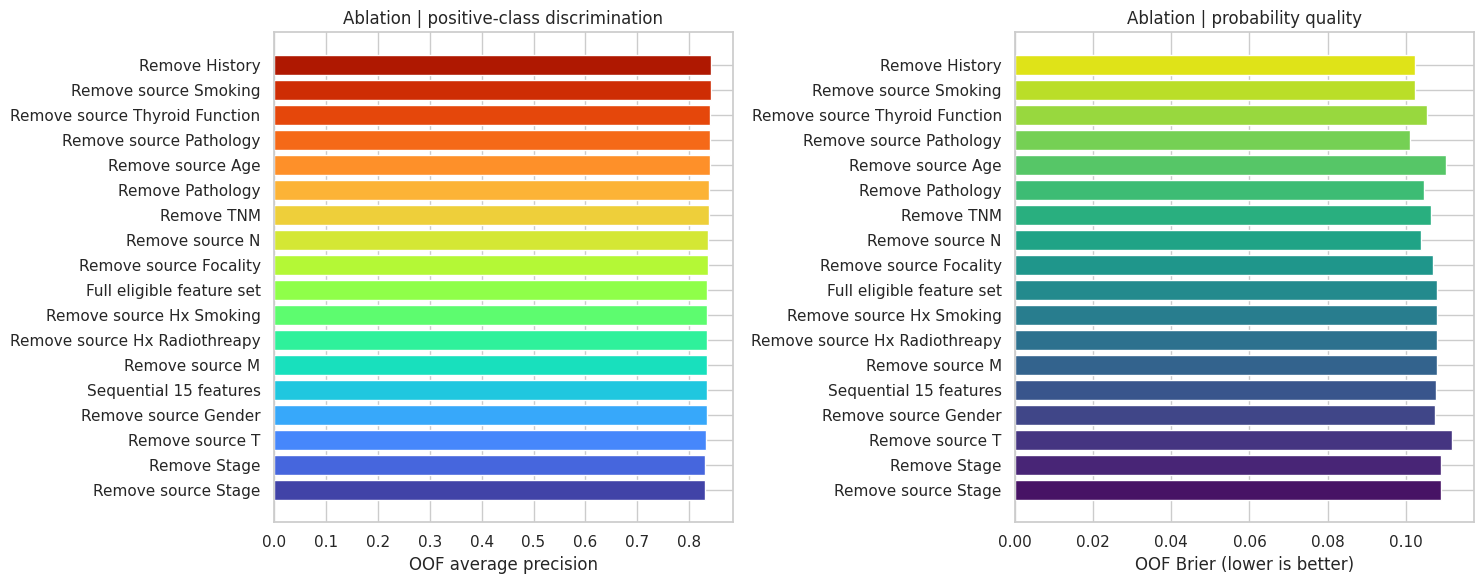

In [84]:
# Difference against FULL on the SAME development patients; all intervals are descriptive (single OOF partition).
abl_comparisons=[]
for s in abl_specs:
    if s=='Full eligible feature set':continue
    ci=paired_bootstrap(ydev,abl_oof['Full eligible feature set'],abl_oof[s],
                        nboot=EXT_BOOTSTRAPS,seed=SEED+201+len(s))
    ci.insert(0,'ablation',s)
    abl_comparisons.append(ci)
abla_ci=pd.concat(abl_comparisons,ignore_index=True)
abla_ci.to_csv(EXT_DIR/'Ablation_paired_bootstrap_full_minus_ablated.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(15,6))
top_abl=abl_summary.head(18).iloc[::-1]
axs[0].barh(top_abl.scenario,top_abl.average_precision,color=mpl.colormaps['turbo'](np.linspace(.07,.93,len(top_abl))))
axs[0].set(xlabel='OOF average precision',title='Ablation | positive-class discrimination')
axs[1].barh(top_abl.scenario,top_abl.brier,color=mpl.colormaps['viridis'](np.linspace(.05,.95,len(top_abl))))
axs[1].set(xlabel='OOF Brier (lower is better)',title='Ablation | probability quality')
fig.tight_layout();save_plot(fig,'EXT_Ablation_Benchmark');plt.show()

## 19X.2 Preprocessing and balancing ablation
Compare no scaling, several numerical scalers, class weighting, ROS and SMOTE **inside training folds only**, at fixed classifier settings. Performance changes may be favorable or unfavorable. Never oversample validation/test patients. For XGBoost, scaling Age alone should usually leave predictions unchanged; differences require investigation.

In [85]:
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import FunctionTransformer
PREP_MODES=['Raw','Standard','MinMax','Robust','Raw_ROS','Standard_ROS','Standard_SMOTE','MinMax_SMOTE','Raw_class_weight']
def preprocessing_variant(name):
    scale=('standard' if name.startswith('Standard') else 'minmax' if name.startswith('MinMax')
           else 'robust' if name.startswith('Robust') else 'raw')
    steps=[('preprocess',preprocessing(ALL_PREDICTORS,scale))]
    if name.endswith('_ROS'):steps.append(('sampler',RandomOverSampler(random_state=SEED)))
    if name.endswith('_SMOTE'):steps.append(('sampler',SMOTE(k_neighbors=3,random_state=SEED)))
    model=xgb()
    if name.endswith('_class_weight'):
        # Weight based on each fold's own class ratio; never derived from test data.
        model.set_params(scale_pos_weight=1.) # overridden during fold fit, below
    steps.append(('model',model))
    return ImbPipeline(steps)
prep_rows=[];prep_oof={}
for mode in PREP_MODES:
    oof=np.full(len(ydev),np.nan)
    for fold,(tr,va) in enumerate(cv_splits,1):
        model=preprocessing_variant(mode)
        if mode=='Raw_class_weight':
            train_y=ydev.iloc[tr];ratio=float((train_y==0).sum()/max(1,(train_y==1).sum()))
            model.set_params(model__scale_pos_weight=ratio)
        model.fit(Xdev.iloc[tr],ydev.iloc[tr]);q=model.predict_proba(Xdev.iloc[va])[:,1]
        oof[va]=q;prep_rows.append({'configuration':mode,'fold':fold,**evaluate(ydev.iloc[va],q)})
    prep_oof[mode]=oof
prep_df=pd.DataFrame(prep_rows);prep_df.to_csv(EXT_DIR/'Preprocessing_ablation_by_fold.csv',index=False)
prep_summary=pd.DataFrame([{'configuration':k,**evaluate(ydev,v)} for k,v in prep_oof.items()])
prep_summary.to_csv(EXT_DIR/'Preprocessing_ablation_OOF.csv',index=False)
print(prep_summary[['configuration','weighted_f1','recurrence_f1','average_precision','brier']].round(4).to_string(index=False))

   configuration  weighted_f1  recurrence_f1  average_precision  brier
             Raw       0.8540         0.7317             0.8344 0.1081
        Standard       0.8540         0.7317             0.8344 0.1081
          MinMax       0.8540         0.7317             0.8344 0.1081
          Robust       0.8540         0.7317             0.8344 0.1081
         Raw_ROS       0.8688         0.7647             0.8412 0.1065
    Standard_ROS       0.8688         0.7647             0.8412 0.1065
  Standard_SMOTE       0.8622         0.7529             0.8345 0.1131
    MinMax_SMOTE       0.8658         0.7602             0.8375 0.1110
Raw_class_weight       0.8688         0.7647             0.8363 0.1079


## 19X.3 Cross-fitted calibration suite: none, sigmoid (Platt), isotonic
Calibration must be learned inside each training fold with an additional *inner* 3-fold CV; the validation fold remains unseen. The OOF Brier score selects calibration using development data alone. Isotonic can overfit a small cohort, and recalibration can improve Brier without improving ranking/AUC. The selected calibrator is subsequently refitted on all development cases. Calibration is assessed on the old historical test descriptively, never to choose a calibrator.

In [86]:
CAL_METHODS=['uncalibrated','sigmoid','isotonic']
cal_oof={};cal_rows=[]
def calibrated_model(method):
    base=build_model('XGB_raw')
    if method=='uncalibrated':return base
    try:return CalibratedClassifierCV(estimator=base,method=method,cv=3,ensemble=True)
    except TypeError:return CalibratedClassifierCV(base_estimator=base,method=method,cv=3,ensemble=True)
for method in CAL_METHODS:
    probs=np.full(len(ydev),np.nan)
    for k,(tr,va) in enumerate(cv_splits,1):
        model=calibrated_model(method);model.fit(Xdev.iloc[tr],ydev.iloc[tr])
        p=model.predict_proba(Xdev.iloc[va])[:,1];probs[va]=p
        cal_rows.append({'method':method,'fold':k,**evaluate(ydev.iloc[va],p)})
    cal_oof[method]=probs
cal_summary=pd.DataFrame([{'method':m,**evaluate(ydev,p),**calibration_parameters(ydev,p)}
                          for m,p in cal_oof.items()])
cal_summary.to_csv(EXT_DIR/'Calibration_out_of_fold_comparison.csv',index=False)
pd.DataFrame(cal_rows).to_csv(EXT_DIR/'Calibration_fold_level.csv',index=False)
CAL_SELECTED=cal_summary.sort_values(['brier','method']).iloc[0]['method']
CAL_LOCKED=calibrated_model(CAL_SELECTED).fit(Xdev,ydev)
from joblib import dump
dump(CAL_LOCKED,EXT_DIR/'Locked_Development_Selected_Calibrated_Model.joblib')
(EXT_DIR/'calibrator_selection.json').write_text(json.dumps({'selected':CAL_SELECTED,'criterion':'minimum OOF Brier',
   'selection_uses_test':False,'selection_uses_external':False},indent=2))
print(cal_summary[['method','brier','log_loss','roc_auc','calibration_intercept','calibration_slope']].round(3).to_string(index=False))
print('Selected from development-only data:',CAL_SELECTED)

      method  brier  log_loss  roc_auc  calibration_intercept  calibration_slope
uncalibrated  0.108     0.420    0.897                 -0.160              0.494
     sigmoid  0.096     0.333    0.888                  0.246              1.274
    isotonic  0.097     0.442    0.893                 -0.282              0.659
Selected from development-only data: sigmoid


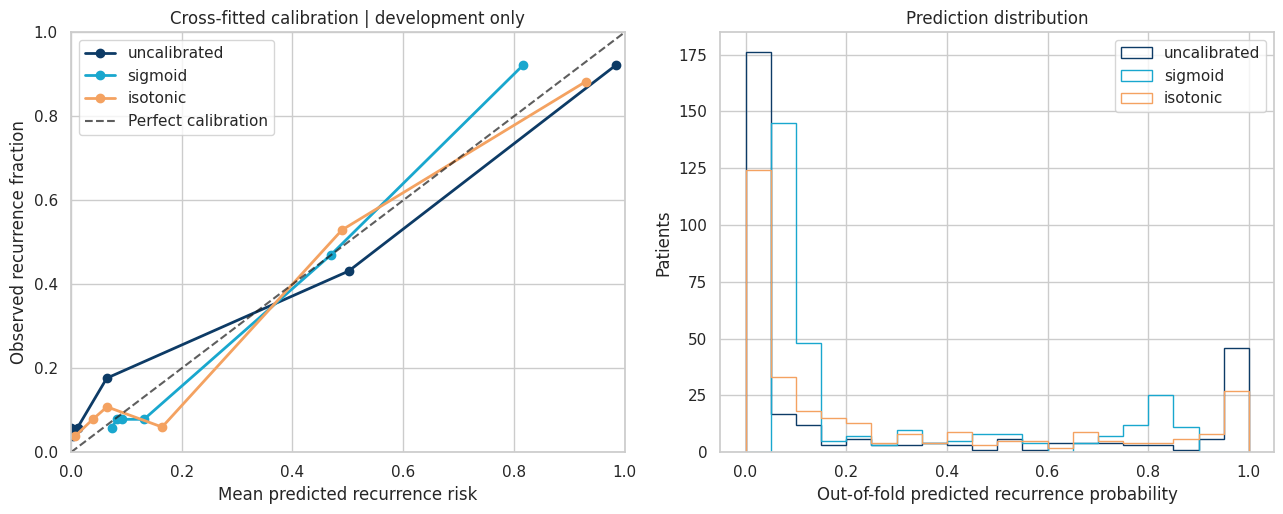

In [87]:
fig,axs=plt.subplots(1,2,figsize=(13,5.3))
for i,(method,p) in enumerate(cal_oof.items()):
    observed,predicted=calibration_curve(ydev,p,n_bins=6,strategy='quantile')
    axs[0].plot(predicted,observed,marker='o',lw=2,color=PALETTE[i],label=method)
axs[0].plot([0,1],[0,1],'k--',alpha=.7,label='Perfect calibration')
axs[0].set(xlabel='Mean predicted recurrence risk',ylabel='Observed recurrence fraction',
           title='Cross-fitted calibration | development only',xlim=(0,1),ylim=(0,1))
axs[0].legend()
for i,(method,p) in enumerate(cal_oof.items()):
    axs[1].hist(p,bins=np.linspace(0,1,21),histtype='step',lw=2,color=PALETTE[i],label=method)
axs[1].set(xlabel='Out-of-fold predicted recurrence probability',ylabel='Patients',title='Prediction distribution')
axs[1].legend();fig.tight_layout();save_plot(fig,'EXT_Calibration_Curves');plt.show()
cal_test_rows=[]
for method in CAL_METHODS:
    est=calibrated_model(method).fit(Xdev,ydev)
    p=est.predict_proba(Xtest)[:,1]
    cal_test_rows.append({'method':method,**evaluate(ytest,p)})
pd.DataFrame(cal_test_rows).to_csv(EXT_DIR/'Historical_test_calibration_descriptive_only.csv',index=False)

## 19X.4 Formal paired statistical comparisons and multiplicity
- **Exact McNemar** on discordant correctness (not an independent-model accuracy test).
- **Paired stratified bootstrap** for AUROC/AP/Brier/recurrence recall/MCC differences; preserve class counts.
- **Benjamini–Hochberg exploratory adjustment** across named clinical/model comparisons.
Small test sample and prior repeated inspection mean all historical test p-values are **exploratory**; a p-value cannot repair repeated use of that split. No significance is claimed merely because the point estimate differs.

In [88]:
from statsmodels.stats.multitest import multipletests
from scipy.stats import binomtest
pair_names=[('XGB_raw','ATA_Risk_only'),('XGB_raw','Risk_Adenopathy_LR')]
# Advanced model was already selected using development; historical test remains a previously viewed split.
stat_rows=[];stat_boot=[]
for left,right in pair_names:
    a=holdout_proba[left];b=holdout_proba[right]
    correct_a=((a>=.5).astype(int)==ytest.to_numpy());correct_b=((b>=.5).astype(int)==ytest.to_numpy())
    A_only=int(np.sum(correct_a&~correct_b));B_only=int(np.sum(~correct_a&correct_b))
    pval=float(binomtest(min(A_only,B_only),A_only+B_only,p=.5,alternative='two-sided').pvalue) if A_only+B_only else 1.
    stat_rows.append({'model_a':left,'model_b':right,'discordant_a_correct_b_wrong':A_only,
                      'discordant_a_wrong_b_correct':B_only,'mcnemar_exact_p_exploratory':pval})
    tmp=paired_bootstrap(ytest,a,b,nboot=EXT_BOOTSTRAPS,seed=SEED+110+len(right))
    tmp.insert(0,'comparison',left+' minus '+right);stat_boot.append(tmp)
if stat_rows:
    statdf=pd.DataFrame(stat_rows)
    statdf['BH_adjusted_p_exploratory']=multipletests(statdf.mcnemar_exact_p_exploratory,method='fdr_bh')[1]
    statdf.to_csv(EXT_DIR/'Paired_McNemar_BH_adjusted_exploratory.csv',index=False)
    pd.concat(stat_boot,ignore_index=True).to_csv(EXT_DIR/'Paired_stratified_bootstrap_model_differences.csv',index=False)
    print(statdf.to_string(index=False))
# Compare error pattern of full clinical model vs baseline (descriptive held-out test, not causal evidence).
error=pd.DataFrame({'historical_row_index':test_idx,'true_recurred':ytest.to_numpy(),
    'XGB_error':(holdout_proba['XGB_raw']>=.5).astype(int)!=ytest.to_numpy(),
    'Risk_Adenopathy_error':(holdout_proba['Risk_Adenopathy_LR']>=.5).astype(int)!=ytest.to_numpy()})
error.to_csv(EXT_DIR/'Historical_error_overlap_analysis.csv',index=False)

model_a            model_b  discordant_a_correct_b_wrong  discordant_a_wrong_b_correct  mcnemar_exact_p_exploratory  BH_adjusted_p_exploratory
XGB_raw      ATA_Risk_only                             3                             1                        0.625                        1.0
XGB_raw Risk_Adenopathy_LR                             3                             4                        1.000                        1.0


## 19X.5 Three-dimensional comparative analytics and diagnostic curves
Interactive HTML + static publication-quality PNG/SVG. Each point corresponds to **measured** metrics; 3D height does not establish superiority. Reports show trade-offs among class sensitivity, discrimination, and calibration and include clinical baselines.

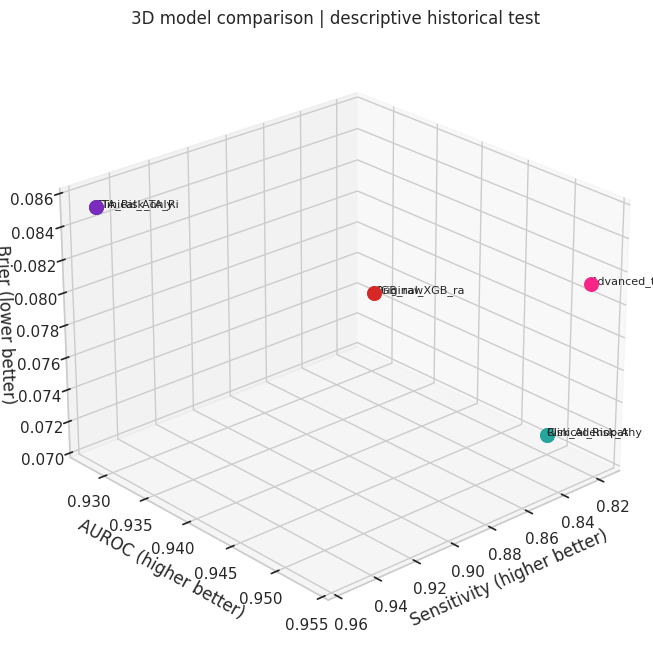

Interactive: EXT_3D_model_tradeoffs_interactive.html
Interactive: EXT_parallel_coordinates_models.html


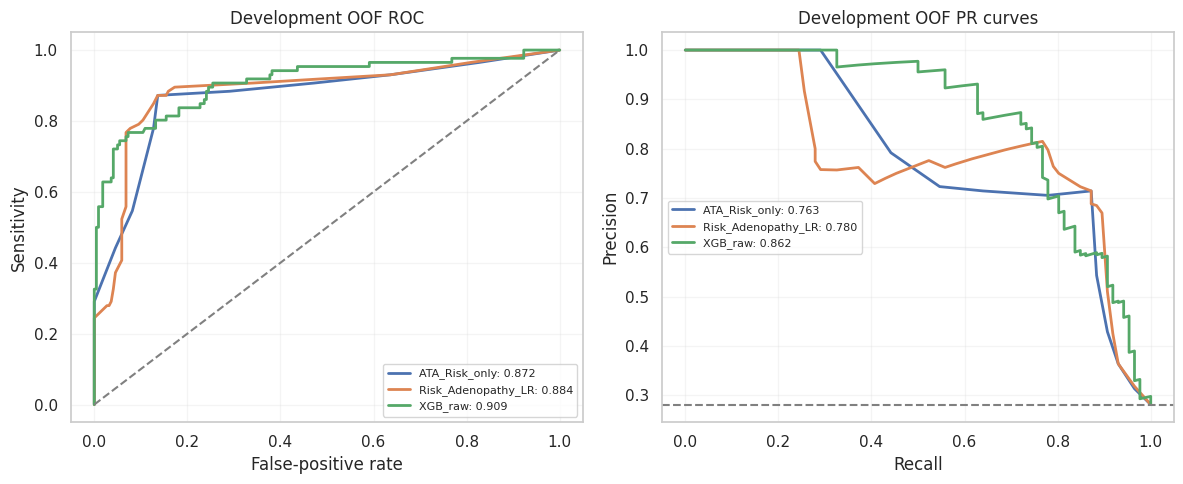

In [89]:
models_to_graph=pd.concat([
    holdout.assign(dataset='Historical test (previously viewed)'),
    advanced_holdout.assign(dataset='Historical test (previously viewed)')],ignore_index=True)
models_to_graph=models_to_graph.drop_duplicates(subset=['model','dataset']).copy()
models_to_graph.to_csv(EXT_DIR/'Figure_3D_model_metric_source_data.csv',index=False)
fig=plt.figure(figsize=(11,8));ax=fig.add_subplot(111,projection='3d')
for i,r in enumerate(models_to_graph.itertuples()):
    ax.scatter(r.recurrence_recall,r.roc_auc,r.brier,c=[PALETTE[i%len(PALETTE)]],s=95,depthshade=True)
    ax.text(r.recurrence_recall,r.roc_auc,r.brier,str(r.model)[:15],fontsize=8)
ax.set(xlabel='Sensitivity (higher better)',ylabel='AUROC (higher better)',
       zlabel='Brier (lower better)',title='3D model comparison | descriptive historical test')
ax.view_init(elev=25,azim=48);save_plot(fig,'EXT_3D_model_tradeoffs');plt.show()
if PLOTLY_OK:
    fig3=px.scatter_3d(models_to_graph,x='recurrence_recall',y='roc_auc',z='brier',color='model',
        size='recurrence_f1',hover_data=['accuracy','specificity','mcc'],
        title='3D risk-prediction performance: discrimination × detection × calibration')
    plotly_save(fig3,'EXT_3D_model_tradeoffs_interactive')
# Interactive model comparison parallel coordinates, no invented measurements.
if PLOTLY_OK:
    mm=models_to_graph[['accuracy','recurrence_recall','specificity','roc_auc','average_precision','brier']].copy()
    mm['model_index']=np.arange(len(mm))
    pp=px.parallel_coordinates(mm,color='model_index',dimensions=['accuracy','recurrence_recall',
        'specificity','roc_auc','average_precision','brier'],color_continuous_scale='Turbo',
        title='Observed model-metric trade-offs (historical test)')
    plotly_save(pp,'EXT_parallel_coordinates_models')
# Discrimination and calibration visual summary of PRIMARY development OOF data.
fig,axs=plt.subplots(1,2,figsize=(12,5))
for n,p in oof_preds.items():
    fpr,tpr,_=roc_curve(ydev,p)
    precision,recall,_=precision_recall_curve(ydev,p)
    axs[0].plot(fpr,tpr,lw=2,label=f'{n}: {roc_auc_score(ydev,p):.3f}')
    axs[1].plot(recall,precision,lw=2,label=f'{n}: {average_precision_score(ydev,p):.3f}')
axs[0].plot([0,1],[0,1],'--',color='gray');axs[0].set(xlabel='False-positive rate',ylabel='Sensitivity',title='Development OOF ROC')
axs[1].axhline(ydev.mean(),ls='--',color='gray');axs[1].set(xlabel='Recall',ylabel='Precision',title='Development OOF PR curves')
for ax in axs:ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.tight_layout();save_plot(fig,'EXT_OOF_ROC_PR');plt.show()

## 19X.6 Locked true external validation — independent CSV + provenance check
**Strict independent external validation is not automatically performed by recycling the UCI dataset.** Add an independently collected cohort at `/kaggle/input/.../external_thyroid.csv` or set `THYREC_EXTERNAL_CSV_PATH`. Provide provenance metadata: different source site/cohort, collection period, outcome definition (recurrence, not progression or mortality), and timing of predictors. The **locked original full XGBoost** and **development-selected calibrated XGBoost** are evaluated unchanged, with no external re-fitting, scaling updates, feature selection or threshold optimization. A duplicate exact-record check blocks known overlap. If unavailable/incompatible, output `NOT_PERFORMED` (never a made-up score).

In [90]:
from pathlib import Path
STRICT_EXTERNAL_PATH=os.getenv('THYREC_EXTERNAL_CSV_PATH','').strip()
STRICT_META_PATH=os.getenv('THYREC_EXTERNAL_META_JSON','').strip()
EXT_REQUIRED_METADATA=('cohort_name','institution_or_repository','collection_period',
                       'outcome_definition','predictor_time_point','independent_of_UCI_915')
def normalize_external_target(s):
    if pd.api.types.is_numeric_dtype(s):
        if not set(s.dropna().astype(float).unique()).issubset({0.,1.}):raise ValueError('Target not binary 0/1')
        return s.astype(int)
    mapping={'yes':1,'no':0,'1':1,'0':0,'recurred':1,'no recurrence':0,'true':1,'false':0}
    ans=s.astype(str).str.strip().str.casefold().map(mapping)
    if ans.isna().any():raise ValueError('Unrecognized target labels: '+str(s[ans.isna()].unique()[:5]))
    return ans.astype(int)
def verify_external_cohort(d,meta):
    absent=[c for c in EXT_REQUIRED_METADATA if not meta.get(c)]
    if absent:raise ValueError('Missing provenance: '+', '.join(absent))
    if any('REPLACE_WITH' in str(v).upper() for v in meta.values()):
        raise ValueError('External provenance template still has placeholders; independently verify each field')
    if meta['independent_of_UCI_915'] is not True:raise ValueError('Explicit independence attestation required')
    if not ('recurr' in str(meta['outcome_definition']).lower()):raise ValueError('Recurrence endpoint not established')
    if not ('before' in str(meta['predictor_time_point']).lower() or 'initial' in str(meta['predictor_time_point']).lower()):
        raise ValueError('Provide explicit pretreatment/initial clinicopathological predictor timing')
    missing=[c for c in ALL_PREDICTORS+['Recurred'] if c not in d.columns]
    if missing:raise ValueError('Missing required model features / target: '+str(missing))
    if len(d)<30:raise ValueError('External n<30: not suitable for requested quantitative assessment')
    xx=d[ALL_PREDICTORS].copy();xx['Age']=pd.to_numeric(xx['Age'],errors='coerce')
    if xx.Age.isna().any():raise ValueError('External Age missing/non-numeric: prespecified complete-case analysis required')
    # Guard overt misuse of direct copies of the source dataset. Identical FULL records are a block.
    external_target=normalize_external_target(d['Recurred'])
    source_fingerprint=set(signatures(raw_df[ALL_PREDICTORS+['Recurred']]))
    for_check=xx.copy();for_check['Recurred']=np.where(external_target==1,'Yes','No')
    # Standardized joint feature fingerprint is robust to CSV column order (not to nonstandard coding).
    ss=set(signatures(for_check[ALL_PREDICTORS+['Recurred']]))
    overlaps=len(ss & source_fingerprint)
    if overlaps:raise ValueError(f'Full-record overlap with source UCI data: {overlaps} signatures; investigate before testing')
    if external_target.nunique()<2:raise ValueError('External data has only one class: AUROC undefined')
    return xx,external_target,overlaps
strict_status={'status':'NOT_PERFORMED','reason':'No independent harmonized CSV and required provenance metadata supplied'}
if STRICT_EXTERNAL_PATH:
    try:
        if not STRICT_META_PATH:raise ValueError('Set THYREC_EXTERNAL_META_JSON with strict provenance fields')
        metadata=json.loads(Path(STRICT_META_PATH).read_text())
        independent=pd.read_csv(STRICT_EXTERNAL_PATH)
        ext_x,ext_y,overlap=verify_external_cohort(independent,metadata)
        ext_probs={'Locked original XGBoost':fitted['XGB_raw'].predict_proba(ext_x)[:,1],
                   'Development-selected calibrated XGBoost':CAL_LOCKED.predict_proba(ext_x)[:,1],
                   'Locked clinical Risk+Adenopathy LR':fitted['Risk_Adenopathy_LR'].predict_proba(ext_x)[:,1]}
        ext_metrics=pd.DataFrame([{'model':name,'cohort':metadata['cohort_name'],**evaluate(ext_y,q)}
                                  for name,q in ext_probs.items()])
        ext_metrics.to_csv(EXT_DIR/'EXTERNAL_True_Independent_Cohort_Metrics.csv',index=False)
        # Save probabilities with hashed row identity only, without patient identifiers.
        pd.DataFrame({'external_row':np.arange(len(ext_y)),'observed':ext_y.to_numpy(),
              **ext_probs}).to_csv(EXT_DIR/'EXTERNAL_Locked_Individual_Risk_Scores.csv',index=False)
        strict_status={'status':'COMPLETED_INDEPENDENT_COHORT','cohort':metadata['cohort_name'],
                       'n':len(ext_y),'recurrences':int(ext_y.sum()),'overlap':overlap,
                       'source_sha256':hashlib.sha256(Path(STRICT_EXTERNAL_PATH).read_bytes()).hexdigest(),
                       'metadata':metadata,'models_refitted_on_external':False}
        print(ext_metrics[['model','n','accuracy','recurrence_recall','roc_auc','average_precision','brier']].round(3).to_string(index=False))
    except Exception as e:
        strict_status={'status':'NOT_PERFORMED','reason':str(e)}
        print('Independent external validation blocked:',e)
(EXT_DIR/'EXTERNAL_STRICT_STATUS.json').write_text(json.dumps(strict_status,indent=2,default=str))
print('INDEPENDENT EXTERNAL:',strict_status['status'])

INDEPENDENT EXTERNAL: NOT_PERFORMED


## 19X.7 Optional **exploratory TCGA thyroid transport** (different target; not strict external recurrence validation)
Uses cBioPortal's TCGA Thyroid Carcinoma PanCancer Atlas clinical files. A model is built and locked **only on UCI development cases using genuinely shared features**, then applied to independent TCGA patients. Disease-free/progression-free outcome can be *recurrence or progression*, may use a different follow-up period, and **must not be called the same target as UCI's `Recurred`**. TCGA lacks several UCI predictors (especially ATA `Risk` and often `Adenopathy`), so the full 16-feature model **cannot** be transported. If real TCGA clinical files are unavailable or insufficiently harmonizable, this section reports `NOT_PERFORMED`. No fabricated substitutes or labels.

In [91]:
# Optional downloadable TCGA files; Kaggle Internet required or local cBioPortal data files in INPUT.
TCGA_ENABLE=os.getenv('THYREC_ENABLE_TCGA_BRIDGE','1')=='1'
TCGA_PATIENT_PATH=os.getenv('THYREC_TCGA_PATIENT_FILE','').strip()
TCGA_SAMPLE_PATH=os.getenv('THYREC_TCGA_SAMPLE_FILE','').strip()
TCGA_BASE='https://media.githubusercontent.com/media/cBioPortal/datahub/master/public/thca_tcga_pan_can_atlas_2018/'
def get_tcga_table(name,local_override=''):
    if local_override:
        source=Path(local_override)
        if not source.exists():raise FileNotFoundError(source)
        return pd.read_csv(source,sep='\t',comment='#',low_memory=False)
    local=OUTPUT/name
    if not local.exists():
        import requests
        r=requests.get(TCGA_BASE+name,timeout=75)
        r.raise_for_status()
        if b'git-lfs.github.com/spec/v1' in r.content[:150]:
            raise RuntimeError('Git LFS pointer returned, not the actual clinical cohort')
        if len(r.content)<1000:raise RuntimeError('Clinical download too small; may not contain patient table')
        local.write_bytes(r.content)
    return pd.read_csv(local,sep='\t',comment='#',low_memory=False)
def select_col(d,names):
    lookup={str(c).upper():c for c in d.columns}
    for n in names:
        if n.upper() in lookup:return lookup[n.upper()]
    return None
def clean_tnm(v,prefix):
    # Prespecified coarse common categories; both UCI and TCGA mapped identically.
    s=pd.Series(v).astype('string').str.upper().str.strip()
    hit=s.str.extract(r'('+prefix+r'[0-4])',expand=False)
    return hit.astype('string')
def clean_stage(v):
    s=pd.Series(v).astype('string').str.upper().str.replace('STAGE','',regex=False).str.strip()
    # Coarse stage IV includes IVA, IVB, IVC; do not remap unknown observations silently.
    return s.str.extract(r'^(IV|III|II|I)(?:[ABC])?$',expand=False).astype('string')
def build_bridge_features(d,mapping):
    result=pd.DataFrame(index=d.index)
    for target,source in mapping.items():
        if source is None:continue
        if target=='Age':result[target]=pd.to_numeric(d[source],errors='coerce')
        elif target=='Gender':
            v=d[source].astype('string').str.strip().str.lower()
            result[target]=v.map({'female':'F','male':'M','f':'F','m':'M'}).astype('string')
        elif target in ('T','N','M'):result[target]=clean_tnm(d[source],target)
        elif target=='Stage':result[target]=clean_stage(d[source])
    return result
bridge_status={'status':'NOT_PERFORMED','reason':'Optional independent transport source not available or disabled'}
if TCGA_ENABLE:
  try:
    patient=get_tcga_table('data_clinical_patient.txt',TCGA_PATIENT_PATH)
    sample=get_tcga_table('data_clinical_sample.txt',TCGA_SAMPLE_PATH)
    pat_id=select_col(patient,['PATIENT_ID']); sam_id=select_col(sample,['PATIENT_ID'])
    if not pat_id or not sam_id:raise ValueError('Missing patient identifiers in public TCGA clinical tables')
    if patient[pat_id].duplicated().any():raise ValueError('TCGA patient clinical file contains duplicate IDs')
    sample=sample.drop_duplicates(subset=[sam_id]).copy()
    combined=patient.merge(sample,left_on=pat_id,right_on=sam_id,how='left',suffixes=('','_SAMPLE'))
    mapping={
      'Age':select_col(combined,['AGE','AGE_AT_DIAGNOSIS','AGE_AT_INITIAL_PATHOLOGIC_DIAGNOSIS']),
      'Gender':select_col(combined,['SEX','GENDER']),
      'T':select_col(combined,['PATH_T_STAGE','AJCC_PATHOLOGIC_T','PATHOLOGIC_T','PATHOLOGIC_T_STAGE']),
      'N':select_col(combined,['PATH_N_STAGE','AJCC_PATHOLOGIC_N','PATHOLOGIC_N','PATHOLOGIC_N_STAGE']),
      'M':select_col(combined,['PATH_M_STAGE','AJCC_PATHOLOGIC_M','PATHOLOGIC_M','PATHOLOGIC_M_STAGE']),
      'Stage':select_col(combined,['AJCC_PATHOLOGIC_TUMOR_STAGE','TUMOR_STAGE','PATHOLOGIC_STAGE','STAGE'])}
    endpoint=select_col(combined,['DFS_STATUS','PFS_STATUS'])
    if endpoint is None:raise ValueError('No recorded DFS/PFS status in TCGA files; endpoint absent')
    if endpoint=='PFS_STATUS':print('CAUTION: PFS includes progression, is not thyroid recurrence alone')
    bridge_x=build_bridge_features(combined,mapping)
    UCI_map={c:c if c in Xdev else None for c in mapping}
    bridge_train=build_bridge_features(Xdev,UCI_map)
    available=[c for c in mapping if c in bridge_x and c in bridge_train and
               bridge_x[c].notna().mean()>=.70 and bridge_train[c].notna().mean()>=.90]
    if len(available)<3 or not {'Age','T','N'}.issubset(available):
        raise ValueError('Too few clinically harmonized common features; available: '+str(available))
    status=combined[endpoint].astype('string').str.strip()
    valid=status.str.match(r'^[01]:',na=False)
    outcome=status.str.extract(r'^([01]):',expand=False).map({'0':0,'1':1})
    usable=bridge_x[available].notna().all(axis=1)&valid&outcome.notna()
    if usable.sum()<35:raise ValueError('Fewer than 35 completely harmonized external patients')
    ext_features=bridge_x.loc[usable,available].copy()
    ext_status=outcome.loc[usable].astype(int)
    if ext_status.nunique()!=2 or ext_status.sum()<5:raise ValueError('Insufficient event cases for exploratory metrics')
    # Fit a separate source-only common-feature bridge. NEVER insert missing ATA Risk values.
    bridge_dev=bridge_train[available].copy()
    bridge_est=xgb_columns(available).fit(bridge_dev,ydev)
    bridge_hist_p=bridge_est.predict_proba(build_bridge_features(Xtest,{c:c for c in mapping})[available])[:,1]
    bridge_ext_p=bridge_est.predict_proba(ext_features)[:,1]
    bridge_stats=pd.DataFrame([{'dataset':'Original UCI historical test','endpoint':'UCI Recurred',
              **evaluate(ytest,bridge_hist_p)},
             {'dataset':'Independent TCGA thyroid','endpoint':endpoint+' (different follow-up endpoint)',
              **evaluate(ext_status,bridge_ext_p)}])
    bridge_stats.to_csv(EXT_DIR/'TCGA_EXPLORATORY_Bridge_source_vs_external.csv',index=False)
    features_export=ext_features.copy();features_export['TCGA_event_composite']=ext_status.to_numpy()
    features_export['locked_bridge_risk']=bridge_ext_p
    features_export.to_csv(EXT_DIR/'TCGA_Exploratory_Locked_Bridge_Results.csv',index=False)
    dump(bridge_est,EXT_DIR/'TCGA_Exploratory_UCI_Trained_Bridge_Model.joblib')
    bridge_status={'status':'COMPLETED_EXPLORATORY_TARGET_MISMATCH_NOT_FULL_EXTERNAL_VALIDATION',
       'tcga_patients_evaluated':len(ext_status),'tcga_composite_events':int(ext_status.sum()),
       'common_features':available,'mapped_fields':mapping,'endpoint':endpoint,
       'full_UCI_model_external_validation':False,
       'reason':'TCGA recurrence/progression endpoint and source cohort recurrence target differ'}
    print(bridge_stats[['dataset','endpoint','n','events','roc_auc','average_precision','brier']].round(3).to_string(index=False))
  except Exception as e:
    bridge_status={'status':'NOT_PERFORMED','reason':str(e)}
    print('TCGA exploratory bridge not completed:',e)
(EXT_DIR/'TCGA_Exploratory_Transport_Status.json').write_text(json.dumps(bridge_status,indent=2,default=str))
print('TCGA:',bridge_status['status'])

                     dataset                                  endpoint   n  events  roc_auc  average_precision  brier
Original UCI historical test                              UCI Recurred  77      22    0.917              0.745  0.102
    Independent TCGA thyroid DFS_STATUS (different follow-up endpoint) 314      22    0.662              0.154  0.247
TCGA: COMPLETED_EXPLORATORY_TARGET_MISMATCH_NOT_FULL_EXTERNAL_VALIDATION


## 19X.8 Covariate shift and clinical utility stress testing (source development vs. historical test)
Distribution-change checks are descriptive, not an external cohort. We save Risk/Stage/sex category shift, age PSI and threshold performance curves. Threshold choice and utility claims require external prospective evaluation. The old test data are shown **for reporting only**, never used to choose models.

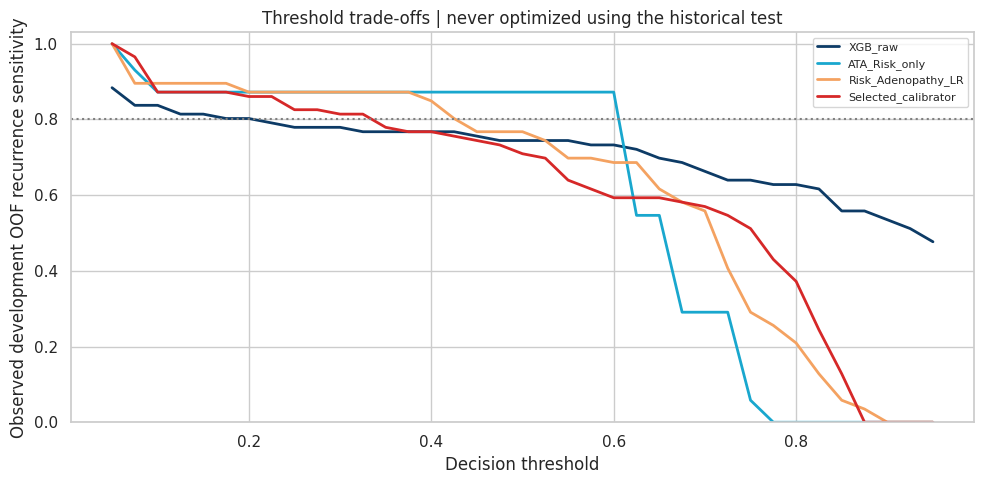

In [92]:
from scipy.spatial.distance import jensenshannon
shift_rows=[]
for feat in ALL_PREDICTORS:
    if feat=='Age':
        # Bin edges based ONLY on source/development observations.
        edges=np.unique(np.quantile(Xdev.Age,[0,.1,.25,.5,.75,.9,1]))
        if len(edges)<3:continue
        dev=np.histogram(Xdev.Age,bins=np.r_[-np.inf,edges[1:-1],np.inf])[0]
        te=np.histogram(Xtest.Age,bins=np.r_[-np.inf,edges[1:-1],np.inf])[0]
        eps=.00001; p=(dev+eps)/(sum(dev)+len(dev)*eps);q=(te+eps)/(sum(te)+len(te)*eps)
        value=float(np.sum((p-q)*np.log(p/q)));measure='PSI'
    else:
        a=Xdev[feat].astype(str).value_counts();bb=Xtest[feat].astype(str).value_counts()
        idx=a.index.union(bb.index);p=a.reindex(idx,fill_value=0).to_numpy(dtype=float)+1e-5
        q=bb.reindex(idx,fill_value=0).to_numpy(dtype=float)+1e-5;p=p/p.sum();q=q/q.sum()
        value=float(jensenshannon(p,q)**2);measure='Jensen-Shannon divergence (squared)'
    shift_rows.append({'feature':feat,'measure':measure,'value':value})
shift=pd.DataFrame(shift_rows).sort_values('value',ascending=False)
shift.to_csv(EXT_DIR/'Historical_split_covariate_shift_descriptive.csv',index=False)
thresholds_ext=np.arange(.05,.951,.025)
threshold_eval=[]
for t in thresholds_ext:
    for model_name,p in [('XGB_raw',oof_preds['XGB_raw']),('ATA_Risk_only',oof_preds['ATA_Risk_only']),
                         ('Risk_Adenopathy_LR',oof_preds['Risk_Adenopathy_LR']),('Selected_calibrator',cal_oof[CAL_SELECTED])]:
        threshold_eval.append({'threshold':float(t),'model':model_name,**evaluate(ydev,p,threshold=t)})
thresh_report=pd.DataFrame(threshold_eval)
thresh_report.to_csv(EXT_DIR/'Development_only_threshold_sensitivity_specificity.csv',index=False)
fig,ax=plt.subplots(figsize=(10,5))
for i,(nm,part) in enumerate(thresh_report.groupby('model',sort=False)):
    ax.plot(part.threshold,part.recurrence_recall,label=nm,lw=2,color=PALETTE[i])
ax.axhline(.8,ls=':',color='gray');ax.set(xlabel='Decision threshold',ylabel='Observed development OOF recurrence sensitivity',
    title='Threshold trade-offs | never optimized using the historical test',ylim=(0,1.03))
ax.legend(fontsize=8);fig.tight_layout();save_plot(fig,'EXT_Threshold_Sensitivity_Tradeoffs');plt.show()

## 19X.9 Audit gates, reproducibility manifest, submission evidence inventory
No automatic 10/10 or journal acceptance declaration. Reports explicitly distinguish: (i) training/development, (ii) the **historical** UCI test, (iii) independent full-model external testing **if supplied**, (iv) optional TCGA surrogate-endpoint transport. A complete notebook should be run with `THYREC_FAST_MODE=0`; read all warnings and manuscript consistency tables. A failed/missing experiment is identified, never silently considered satisfied.

In [93]:
from datetime import datetime,timezone
full_external_done=strict_status['status']=='COMPLETED_INDEPENDENT_COHORT'
audit_gates={
 'run_mode':'QUICK_SMOKE_TEST_NOT_FOR_PAPER' if FAST_MODE else 'FULL',
 'original_200_pipeline_reconstruction_complete':bool(RUN_FULL_ORIGINAL and len(full200)==1000 and not full200_failures),
 'feature_ablation_experiments':int(len(abl_specs)),
 'preprocessing_ablation_variants':int(len(PREP_MODES)),
 'cross_fitted_calibration_methods':list(cal_oof),
 'calibration_selected_without_test':CAL_SELECTED,
 'true_independent_external_validation_completed':full_external_done,
 'true_external_status':strict_status,
 'tcga_exploratory_status':bridge_status,
 'historical_test_previously_accessed':True,
 'historical_test_suitable_for_new_unbiased_selection':False,
 'test_predictor_signature_collisions':len(common),
 'can_claim_full_clinical_validation':False,
 'predictive_performance_improvement_guaranteed':False,
 'original_manuscript_results_reconciled':False,
 'source_dataset_Doi':'10.24432/C5632J',
 'software_python':platform.python_version(),
 'generated_at_utc':datetime.now(timezone.utc).isoformat()
}
(EXT_DIR/'FINAL_CLINICAL_RESEARCH_READINESS.json').write_text(json.dumps(audit_gates,indent=2,default=str))
with (EXT_DIR/'READ_ME_FIRST_Reviewer2.txt').open('w') as handle:
    handle.write('THYREC-LC reviewer extension.\n\n')
    handle.write('TRUE EXTERNAL VALIDATION: '+strict_status['status']+'\n'+str(strict_status.get('reason',''))+'\n')
    handle.write('TCGA SURROGATE ENDPOINT: '+bridge_status['status']+'\n'+str(bridge_status.get('reason',''))+'\n')
    handle.write('ALL newly explored historical-test comparisons are descriptive (test previously viewed).\n')
    handle.write('Compare original manuscript numbers to reconstructed pipeline before resubmission.\n')
    handle.write('No promise that new models outperform clinical baselines.\n')
print('Reviewer gates:',json.dumps({k:v for k,v in audit_gates.items() if k not in ('true_external_status','tcga_exploratory_status')},indent=2))

Reviewer gates: {
  "run_mode": "FULL",
  "original_200_pipeline_reconstruction_complete": true,
  "feature_ablation_experiments": 37,
  "preprocessing_ablation_variants": 9,
  "cross_fitted_calibration_methods": [
    "uncalibrated",
    "sigmoid",
    "isotonic"
  ],
  "calibration_selected_without_test": "sigmoid",
  "true_independent_external_validation_completed": false,
  "historical_test_previously_accessed": true,
  "historical_test_suitable_for_new_unbiased_selection": false,
  "test_predictor_signature_collisions": 7,
  "can_claim_full_clinical_validation": false,
  "predictive_performance_improvement_guaranteed": false,
  "original_manuscript_results_reconciled": false,
  "source_dataset_Doi": "10.24432/C5632J",
  "software_python": "3.13.15",
  "generated_at_utc": "2026-10-14T07:43:16.650264+00:00"
}


## 19. Manuscript-ready result tables and draft report (numbers generated *after execution*)

The following exports summarize actual notebook outputs, with no fabricated values. Read the results **before** adding them to the revised Results and Discussion; unexpected scores may indicate version differences, predictor-vector collisions, or data-processing differences from the original script. One manuscript section may describe the new analyses, while full fold tables go into supplementary files.

In [94]:
def fmt(v,dec=3):
    if v is None or not np.isfinite(v):return 'NA'
    return f'{v:.{dec}f}'
ml=holdout.set_index('model').loc['XGB_raw']
a=holdout.set_index('model').loc['ATA_Risk_only']
b=holdout.set_index('model').loc['Risk_Adenopathy_LR']
cv_x=repeated.loc[repeated.model=='XGB_raw','weighted_f1']
report=[
 '# THYREC-LC | Reviewer 2 supplemental reproducible results','',
 '> Generated from actual notebook computations. The 77-case test partition is not a new external sample.','',
 f'- Source: UCI 915; n={len(y)}; recurrences={int(y.sum())}; CSV SHA-256 `{SOURCE_SHA256}`.',
 f'- Duplicate audit: {AUDIT["exact_duplicate_rows_after_first"]} repeat rows beyond first; '+
   f'{AUDIT["predictor_duplicate_rows_after_first"]} matching predictor rows beyond first; '+
   f'{AUDIT["conflicting_label_predictor_groups"]} conflicting-outcome predictor groups.',
 f'- Original split: {len(ydev)} development / {len(ytest)} test, '+
   f'{SPLIT_AUDIT["cross_split_predictor_signature_groups"]} cross-boundary predictor-signature groups.',
 '', '## Clinical comparison on historical test set',
 '| Model | AUROC | Recurrence F1 | Balanced accuracy | Brier |',
 '|---|---:|---:|---:|---:|',
 *[f'| {r.model} | {fmt(r.roc_auc)} | {fmt(r.recurrence_f1)} | '+
   f'{fmt(r.balanced_accuracy)} | {fmt(r.brier)} |' for r in holdout.itertuples()],
 '', f'- XGB_raw repeated development CV weighted F1: '+
     f'{fmt(cv_x.mean())} ± {fmt(cv_x.std(ddof=1))} over {len(cv_x)} correlated fold estimates.',
 f'- XGB_raw development-OOF Brier: {fmt(brier_score_loss(ydev,oof_preds["XGB_raw"]))}.',
 '- Bootstrap improvements vs risk-only/two-feature models are in table_R2_paired_bootstrap_95ci.csv.',
 '- Calibration slope/intercept and Brier appear in table_R2_calibration_slope_intercept_brier.csv.',
 '- Clinical net benefit is exploratory and calculated from development-only out-of-fold probabilities.',
 '', '## Scientific reporting cautions',
 '- Predictor collisions cannot be equated with duplicate patient identity without patient IDs.',
 '- Original test data were already reported: avoid describing new comparisons as fresh validation.',
 '- An independent original 200-pipeline reconstruction is included; exact historical model defaults remain unverified.',
 '- Neither prospective safety, independent external validation, clinical utility, nor causal effects are established.',
 '- Run with FAST_MODE=False before submission and review every fold failure log.',
 '']
(OUTPUT/'MANUSCRIPT_RESULTS_FROM_COMPUTATION.md').write_text('\n'.join(report),encoding='utf-8')
print('\n'.join(report[:17]))

# THYREC-LC | Reviewer 2 supplemental reproducible results

> Generated from actual notebook computations. The 77-case test partition is not a new external sample.

- Source: UCI 915; n=383; recurrences=108; CSV SHA-256 `a2c65f7c8fa0e78a65aa4946961aafd45218c92760d10375fe2c778045c97b44`.
- Duplicate audit: 19 repeat rows beyond first; 27 matching predictor rows beyond first; 1 conflicting-outcome predictor groups.
- Original split: 306 development / 77 test, 7 cross-boundary predictor-signature groups.

## Clinical comparison on historical test set
| Model | AUROC | Recurrence F1 | Balanced accuracy | Brier |
|---|---:|---:|---:|---:|
| ATA_Risk_only | 0.928 | 0.824 | 0.905 | 0.085 |
| Risk_Adenopathy_LR | 0.950 | 0.857 | 0.891 | 0.071 |
| XGB_raw | 0.949 | 0.851 | 0.909 | 0.083 |

- XGB_raw repeated development CV weighted F1: 0.859 ± 0.042 over 25 correlated fold estimates.
- XGB_raw development-OOF Brier: 0.096.


## 20. TRIPOD+AI evidence map (working checklist, not an automatic compliance claim)

The **official 2024 TRIPOD+AI** guideline has 27 top-level items and multiple subitems; this mapping is **only a working index of experiment-supported evidence**. The actual expanded checklist must be completed against the final journal manuscript, including exact pages, source-cohort inclusion criteria and any unavailable information. Source: [Collins et al. 2024, BMJ 385:e078378](https://doi.org/10.1136/bmj-2023-078378).

In [95]:
tripod_map={
 1:'Title: population, target and prediction task',2:'Unstructured/structured abstract per journal policy',
 3:'Introduction clinical context, comparator need',4:'Explicit prediction time point and study objectives',
 5:'UCI 915 source details, DOI, 15-year cohort origin',6:'Eligibility: original publication, unknown sampling details',
 7:'Outcome definition, recurrent Yes/No; no recurrence time available',
 8:'Risk, Adenopathy and remaining feature names; Response excluded',
 9:'n=383, events=108; no formal adequacy claim',10:'No missing data asserted by UCI; duplicates audited',
 11:'Preprocessing and analytical plan, seed, threshold, validation strategy',
 12:'Primary XGBoost and simple logistic baselines, full settings JSON',
 13:'Original split plus repeated/nested development CV and group sensitivity',
 14:'No clinical model updating claimed; development-only sigmoid calibration explored',
 15:'Original SHAP and permutation analyses; here: incremental baselines and ablation',
 16:'Risk group source feature; threshold analyses do not define approved strata',
 17:'No missing rows in released UCI; imputation defined inside folds for robustness',
 18:'UCI DOI, source SHA-256, executable notebook, requirement/version exports',
 19:'Public/patient involvement not documented; must state author knowledge',
 20:'Source cohort and original 306/77 counts; signature-match audit',
 21:'Original cohort feature and target table; subgroup counts exported',
 22:'Fitted parameters exported; predictor inputs and probability outputs documented',
 23:'Holdout clinical baselines, CV, nested CV, calibration and DCA tables',
 24:'Paired incremental comparison; alternative criteria; group-disjoint analysis',
 25:'Interpretation must address whether full ML exceeds simple clinical rules',
 26:'Small cohort, no patient IDs, no external site, bias/threshold/precision limitations',
 27:'Research benchmark only; prospective validation required before clinical use'}
map_table=pd.DataFrame([{'TRIPOD_AI_item':i,'planned_evidence':desc,
                         'manuscript_page_to_complete':'',
                         'verified_fully_compliant':'NOT ASSESSED'} for i,desc in tripod_map.items()])
map_table.to_csv(OUTPUT/'TRIPOD_AI_27_item_working_evidence_map.csv',index=False)
print('Working evidence map exported,',len(map_table),'top-level items; fill official expanded checklist separately.')

Working evidence map exported, 27 top-level items; fill official expanded checklist separately.


## 21. Final safety audit, figure inventory, zipped reviewer supplement

**Before sending the revision:** run the entire notebook with FAST_MODE=False, confirm data fingerprint and no unexpected CV failures, compare any reconstructed historical test score against the manuscript, check all plots manually, complete TRIPOD+AI, deposit the final executable code publicly (e.g., Zenodo/GitHub), and update the response letter with **actual** numbers. Never assert that the already-used test set or the group-signature sensitivity test is independent multicenter external validation.

In [96]:
import shutil
files=sorted(p for p in OUTPUT.iterdir() if p.is_file())
print('Artifacts:',len(files))
for p in files: print('  ',p.name,round(p.stat().st_size/1024,1),'KB')
WARNINGS=[]
if FAST_MODE: WARNINGS.append('FAST_MODE: use full settings before publication')
if not RUN_FULL_ORIGINAL: WARNINGS.append('Full 20x10 reconstruction was skipped in FAST_MODE')
if RUN_FULL_ORIGINAL and (len(full200)!=1000 or full200_failures): WARNINGS.append('Incomplete original 200-pipeline reconstruction; inspect errors')
if cv_errors: WARNINGS.append(f'{len(cv_errors)} model-fold failures; inspect cv_errors.csv')
if OPTIONAL_MISSING: WARNINGS.append('Advanced optional models not available: '+', '.join(OPTIONAL_MISSING))
if not np.isfinite(advanced_oof).all(): WARNINGS.append('Advanced OOF outputs incomplete')
if common: WARNINGS.append('Original split contains duplicate predictor-signature collisions')
if abs(holdout.set_index('model').loc['XGB_raw','accuracy']-69/77)>0.001:
    WARNINGS.append('Recomputed XGB historical accuracy differs from 69/77 (model configuration/version audit needed)')

if not full_external_done: WARNINGS.append('True independent full-model external validation NOT completed; required external independent dataset unavailable/incompatible')
if bridge_status['status']=='NOT_PERFORMED': WARNINGS.append('TCGA transport NOT_PERFORMED (optional, non-equivalent outcome)')
(OUTPUT/'final_warnings.json').write_text(json.dumps(WARNINGS,indent=2))
print('FINAL WARNINGS:', WARNINGS or 'None, within scope of implemented checks')
archive=shutil.make_archive(str(OUTPUT.parent/'THYREC_LC_R2_Results'),'zip',root_dir=OUTPUT)
print('Created result ZIP:',archive)
print('Independent external validation status:', strict_status['status'])

Artifacts: 82
   ADV_README_FOR_REVIEWERS.md 0.8 KB
   ADV_clinical_interaction_fold_comparison.csv 2.6 KB
   ADV_conformal_development_fold_level.csv 18.5 KB
   ADV_conformal_summary.json 0.3 KB
   ADV_development_OOF_threshold_sweep.csv 15.3 KB
   ADV_development_nested_decision_curves.csv 5.3 KB
   ADV_development_only_model_gate.json 0.8 KB
   ADV_development_threshold_tradeoffs.png 183.8 KB
   ADV_full_development_tuning.csv 1.0 KB
   ADV_full_research_protocol.json 1.5 KB
   ADV_historical_holdout_ALL_models.csv 1.3 KB
   ADV_historical_test_predictions.csv 2.2 KB
   ADV_historical_test_threshold_comparison.csv 0.9 KB
   ADV_learning_curve_fold_results.csv 5.1 KB
   ADV_learning_curves.png 198.4 KB
   ADV_locked_selection.json 0.5 KB
   ADV_locked_train_selected_model.joblib 202.3 KB
   ADV_matching_fold_development_model_comparison.csv 1.2 KB
   ADV_negative_control_label_shuffling.csv 5.0 KB
   ADV_nested_all_inner_model_scores.csv 5.0 KB
   ADV_nested_decision_curves.png 187.3